In [1]:
import os
import time
import regionmask
import numpy as np
import pandas as pd
import xarray as xr
import xesmf as xe
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import statsmodels.api as sm_stats
import scipy.stats as stats
from scipy.stats import binomtest
from scipy.stats import fisher_exact
from scipy.stats import theilslopes, kendalltau
import matplotlib.cm as cm
import matplotlib.path as mpath
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.patches import Circle
from shapely.errors import GEOSException

In [2]:
# The time coordinate is standardized to the first day of each month.
def first_day_each_month(ds: xr.Dataset) -> xr.Dataset:
    """
    Force ds.time to the first day of each month. 
    Works for both ERA5 and GRACE monthly data.
    """
    t = pd.to_datetime(ds.indexes["time"]).to_period("M").to_timestamp()  # month-end by default
    t = t - pd.offsets.MonthEnd(1) + pd.offsets.Day(1)  # shift to first day
    return ds.assign_coords(time=t)

In [3]:
#loading era5 data
era5_path = os.path.join("/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed", "era5_data.nc")
era5_data = xr.open_dataset(era5_path)
era5_data = first_day_each_month(era5_data)
era5_data

<xarray.Dataset> Size: 15GB
Dimensions:  (time: 900, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2024-12-01
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    swe      (time, lat, lon) float32 4GB ...
    t2m      (time, lat, lon) float32 4GB ...
    ppt      (time, lat, lon) float32 4GB ...
    eto      (time, lat, lon) float32 4GB ...

In [4]:
#loading era5 data
era5_land_path = os.path.join("/home/mgurazada/snowdroughts_thirst/data/era5_land_swe", "era5_land_swe_mm_1950_2024_processed.nc")
era5_land_data = xr.open_dataset(era5_land_path)
era5_land_data = first_day_each_month(era5_land_data)
era5_land_data

<xarray.Dataset> Size: 12GB
Dimensions:  (time: 900, lat: 901, lon: 3600)
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2024-12-01
  * lat      (lat) float64 7kB 0.0 0.1 0.2 0.3 0.4 ... 89.6 89.7 89.8 89.9 90.0
  * lon      (lon) float64 29kB -180.0 -179.9 -179.8 ... 179.7 179.8 179.9
Data variables:
    swe      (time, lat, lon) float32 12GB ...

In [5]:
# Compute resolution (in degrees)
dlat = np.abs(era5_data.lat[1] - era5_data.lat[0]).item()
dlon = np.abs(era5_data.lon[1] - era5_data.lon[0]).item()
print(f"ERA5 grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

ERA5 grid spacing: 0.250° lat × 0.250° lon


In [6]:
# Compute resolution (in degrees)
dlat = np.abs(era5_land_data.lat[1] - era5_land_data.lat[0]).item()
dlon = np.abs(era5_land_data.lon[1] - era5_land_data.lon[0]).item()
print(f"ERA5 grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

ERA5 grid spacing: 0.100° lat × 0.100° lon


In [7]:
# load hydrobasins level 4
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")
hb.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

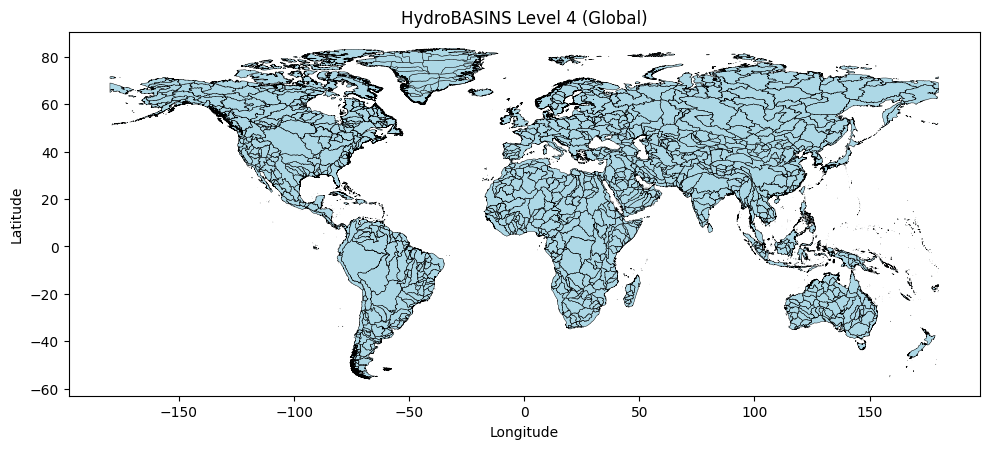

In [8]:
# Plot hydrobasins
fig, ax = plt.subplots(figsize=(10, 6))
hb.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.3)

ax.set_title("HydroBASINS Level 4 (Global)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [9]:
# Simplify basin geometries
# Reduces polygon complexity for faster processing
# preserve_topology=True avoids breaking shapes

hb_simple = hb.copy()
hb_simple["geometry"] = hb.geometry.simplify(0.01, preserve_topology=True)

# Fix invalid geometries introduced by simplify
# buffer(0) is a common geometry fix
hb_simple["geometry"] = hb_simple.geometry.buffer(0)

# Get all unique major basin IDs (sorted)
# (MAIN_BAS groups multiple polygons belonging to one larger basin)
main_ids = np.sort(hb_simple["MAIN_BAS"].unique())

Plotting MAIN_BAS = 1040000010


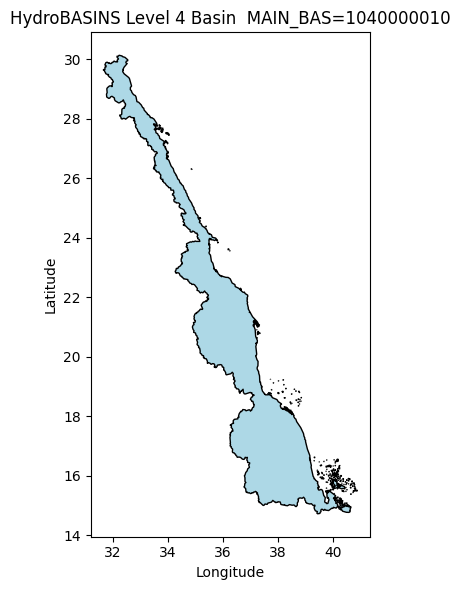

Plotting MAIN_BAS = 9040018060


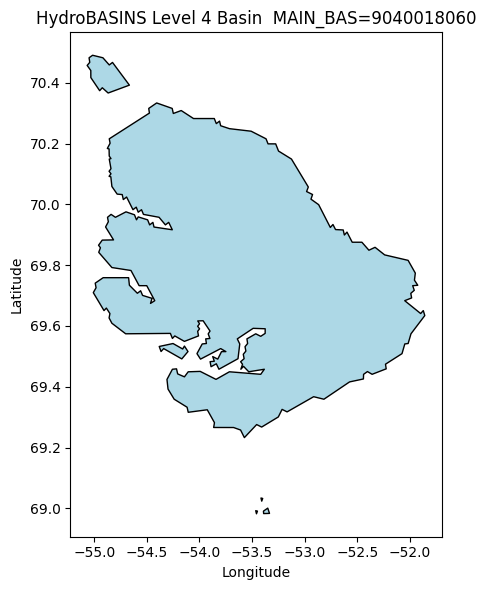

In [10]:
# Identify first and last basins
first_id = main_ids[0]
last_id  = main_ids[-1]

# Plot only first and last basins to verify geometry structure
for main_id in main_ids:
    basin = hb_simple[hb_simple["MAIN_BAS"] == main_id]

    # Only plot first and last basins
    if main_id in [first_id, last_id]:
        print(f"Plotting MAIN_BAS = {main_id}")

        fig, ax = plt.subplots(figsize=(8, 6))
        basin.plot(ax=ax, color="lightblue", edgecolor="black")

        ax.set_title(f"HydroBASINS Level 4 Basin  MAIN_BAS={main_id}", fontsize=12)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

        plt.tight_layout()
        plt.show()

In [11]:
print(hb_simple["MAIN_BAS"].values)

[1040000010 1040003990 1040006850 ... 3040024180 3040024310 3040001840]


EPSG:4326
Original basins: 1342
Basins intersecting 0–60°N: 846


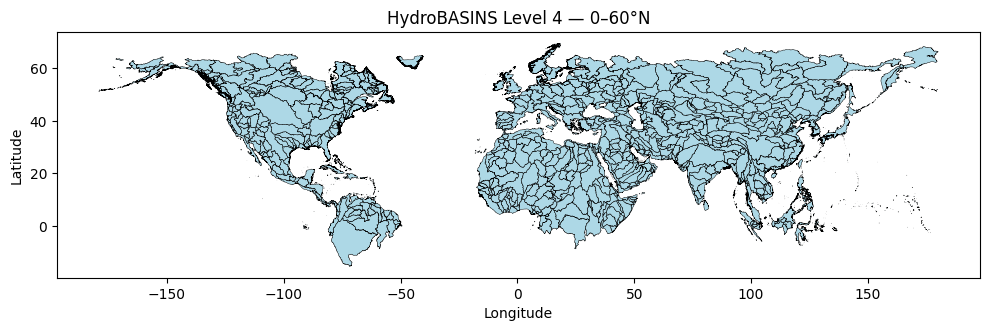

In [12]:
# Create latitude bounding box
# Keep only 0–60°N region

from shapely.geometry import box

# Read HydroBASINS level 3
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")
print(hb.crs)

# Define bounding box for 0–60°N (all longitudes)
bbox_geom = box(-180, 0, 180, 60)  # (minx, miny, maxx, maxy)

# Keep polygons that intersect this band (including edge-touching basins)
# Keep basins intersecting the latitude band -- keeps partial basins crossing boundaries
hb_0_60N = hb[hb.geometry.intersects(bbox_geom)].copy()

# # Keep only basins fully inside the band 
# Alternative: within() would keep only fully enclosed basins
# hb_0_60N = hb[hb.geometry.within(bbox_geom)].copy()

print("Original basins:", len(hb))
print("Basins intersecting 0–60°N:", len(hb_0_60N))

# Quick plot
fig, ax = plt.subplots(figsize=(10, 6))
hb_0_60N.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.3)

ax.set_title("HydroBASINS Level 4 — 0–60°N")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [13]:
# Simplify geometries again after subsetting
hb_simple = hb_0_60N.copy()

hb_simple["geometry"] = hb_0_60N.geometry.simplify(0.01, preserve_topology=True)

# Fix invalid geometries introduced by simplify
hb_simple["geometry"] = hb_simple.geometry.buffer(0)

# Get all unique MAIN_BAS IDs (sorted) 
main_ids = np.sort(hb_simple["MAIN_BAS"].unique())

In [14]:
# These will define regionmask regions
main_ids = main_ids.copy()  # keep original order used to build `regions`

In [15]:
# Build regionmask inputs
geoms   = []
names   = []
abbrevs = []
main_ids_valid = []

# Create one merged geometry per MAIN_BAS
for mid in main_ids:
    basin = hb_simple[hb_simple["MAIN_BAS"] == mid]

    try:
        # dissolve polygons for this MAIN_BAS
        geom = basin.geometry.union_all()
        # clean again just in case
        geom = geom.buffer(0)
        if geom.is_empty:
            print(f"Skipping MAIN_BAS={mid} (empty after buffer)")
            continue
    except GEOSException as e:
        print(f"Skipping MAIN_BAS={mid} due to topology error: {e}")
        continue
    
    geoms.append(geom)
    names.append(f"basin_{mid}")
    abbrevs.append(str(mid))
    main_ids_valid.append(mid) 

In [16]:
# MAIN_BAS -> actual regionmask index
basin_to_region_index = {
    bid: i for i, bid in enumerate(main_ids_valid)
} # Dictionary: MAIN_BAS → region index - Useful later for mapping outputs

In [17]:
# Create regionmask object
# This enables assigning ERA5 / GRACE grid cells to basin IDs
regions = regionmask.Regions(geoms, names=names, abbrevs=abbrevs)
regions

<regionmask.Regions 'unnamed'>
overlap:  None

Regions:
  0 1040000010 basin_1040000010
  1 1040003990 basin_1040003990
  2 1040006850 basin_1040006850
  3 1040006860 basin_1040006860
  4 1040007000 basin_1040007000
 ..        ...              ...
597 8040018120 basin_8040018120
598 8040018970 basin_8040018970
599 8040018980 basin_8040018980
600 8040019790 basin_8040019790
601 9040005890 basin_9040005890

[602 regions]

In [18]:
print("hb:", len(hb)) # all global Level-4 polygons
print("hb_0_60N:", len(hb_0_60N)) # polygons intersecting 0–60°N
print("hb_simple:", len(hb_simple)) # same subset after simplification -- simplification did not drop any basin polygons,
print("Number of regions:", len(regions)) # once the basins are dissolved by MAIN_BAS, those 846 polygons become 602

hb: 1342
hb_0_60N: 846
hb_simple: 846
Number of regions: 602


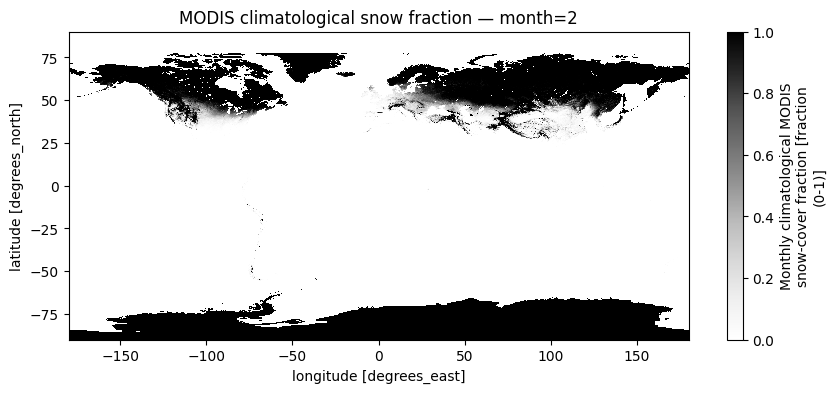

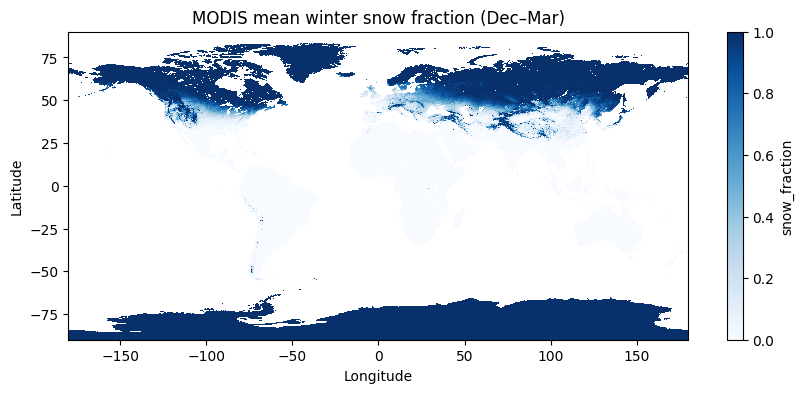

In [19]:
# monthly MODIS snow-cover climatology and turning it into one continuous winter snow-fraction for Dec-Mar.
    
# Load MODIS snow climatology
# Select winter months (Dec–Mar)
# Calculate mean winter snow-cover fraction (Dec–Mar)
# load snow mask climatology (MODIS NSIDC)
snow_path = "/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/snow_mask_monthly_climatology/modis_nsidc_snow_fraction_monthly_0p05deg_v1.nc"
snow = xr.open_dataset(snow_path)

snow_clim = snow["snow_fraction"]

# pick snow months Dec–Mar
snow_winter = snow_clim.sel(month=[12, 1, 2, 3])

snow_winter.isel(month=2).plot(
    x="lon", y="lat",
    cmap="Greys",
    vmin=0, vmax=1,
    figsize=(10, 4)
)
plt.title(
    f"MODIS climatological snow fraction — "
    f"month={int(snow_winter.month.values[2])}"
)
plt.show()

# Mean Dec–Mar climatological snow fraction
winter_snow_frac = snow_winter.mean(dim="month")

winter_snow_frac

winter_snow_frac.plot(
    x="lon",
    y="lat",
    cmap="Blues",
    vmin=0,
    vmax=1,
    figsize=(10, 4),
    add_colorbar=True
)

plt.title("MODIS mean winter snow fraction (Dec–Mar)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

0.0 100.0
0.0 1.0


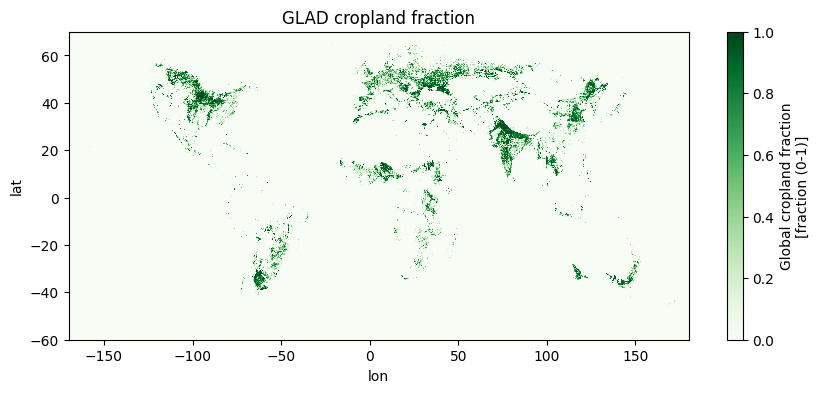

In [20]:
# Load cropland
# Standardize coordinates (x/y → lon/lat)
# Ensure latitude ordering
# Convert cropland to boolean presence

# load cropland (2019)
crop_path = "/home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc"
crop = xr.open_dataset(crop_path)
crop_var_name = list(crop.data_vars)[1]
cropland = crop[crop_var_name]  # e.g., cropland

# If coordinates are named x/y, rename to lon/lat once:
if "x" in cropland.dims and "y" in cropland.dims:
    cropland = cropland.rename({"y": "lat", "x": "lon"})

# sort latitude ascending
if (cropland.lat.diff("lat") < 0).any():
    cropland = cropland.sortby("lat")

print(cropland.min().item(), cropland.max().item())

# Convert cropland percentage (0–100) to fraction (0–1)
cropland_frac = cropland / 100.0

# Safety check
cropland_frac = cropland_frac.clip(0, 1)

cropland_frac.attrs["long_name"] = "Global cropland fraction"
cropland_frac.attrs["units"] = "fraction (0-1)"
cropland_frac.attrs["source"] = "GLAD Global Cropland Extent 2019"

print(
    cropland_frac.min().item(),
    cropland_frac.max().item()
)

cropland_frac.plot(
    x="lon",
    y="lat",
    cmap="Greens",
    vmin=0,
    vmax=1,
    figsize=(10, 4)
)

plt.title("GLAD cropland fraction")
plt.show()

In [21]:
# ============================================================
# ERA5 grid basin mask
# ============================================================

mask3d_era5 = regions.mask_3D(
    era5_data["lon"],
    era5_data["lat"],
    drop=False
).load()

overlap_count = mask3d_era5.sum(dim="region")

print(
    "Maximum overlapping basins:",
    overlap_count.max().item()
)

n_overlap_cells = (overlap_count > 1).sum().item()

print(
    "ERA5 cells belonging to >1 basin:",
    n_overlap_cells
)


# ============================================================
# ERA5 latitude-dependent area weights
# ============================================================

lat_weights_era5 = np.cos(
    np.deg2rad(era5_data["lat"])
)

w2d_era5 = xr.DataArray(
    lat_weights_era5,
    coords={"lat": era5_data["lat"]},
    dims=["lat"]
).broadcast_like(
    era5_data.isel(time=0, drop=True)
)

w2d_era5 = w2d_era5.load()

print("mask3d_era5:", mask3d_era5.dims, mask3d_era5.shape)
print("w2d_era5:", w2d_era5.dims, w2d_era5.shape)

Maximum overlapping basins: 2
ERA5 cells belonging to >1 basin: 16
mask3d_era5: ('region', 'lat', 'lon') (602, 721, 1440)
w2d_era5: ('lat', 'lon') (721, 1440)


/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


In [22]:
# ============================================================
# ERA5-Land grid basin mask for SWE
# ============================================================

mask3d_era5_land = regions.mask_3D(
    era5_land_data["lon"],
    era5_land_data["lat"],
    drop=False
).load()

overlap_count_land = mask3d_era5_land.sum(dim="region")

print(
    "Maximum overlapping basins on ERA5-Land grid:",
    overlap_count_land.max().item()
)

n_overlap_cells_land = (
    overlap_count_land > 1
).sum().item()

print(
    "ERA5-Land cells belonging to >1 basin:",
    n_overlap_cells_land
)


# ============================================================
# ERA5-Land latitude-dependent area weights
# ============================================================

lat_weights_era5_land = np.cos(
    np.deg2rad(era5_land_data["lat"])
)

w2d_era5_land = xr.DataArray(
    lat_weights_era5_land,
    coords={"lat": era5_land_data["lat"]},
    dims=["lat"]
).broadcast_like(
    era5_land_data.isel(time=0, drop=True)
)

w2d_era5_land = w2d_era5_land.load()

print(
    "mask3d_era5_land:",
    mask3d_era5_land.dims,
    mask3d_era5_land.shape
)

print(
    "w2d_era5_land:",
    w2d_era5_land.dims,
    w2d_era5_land.shape
)

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


Maximum overlapping basins on ERA5-Land grid: 2
ERA5-Land cells belonging to >1 basin: 109
mask3d_era5_land: ('region', 'lat', 'lon') (602, 901, 3600)
w2d_era5_land: ('lat', 'lon') (901, 3600)


In [23]:
# Conservative area-weighted regridding to ERA5
# This helper function is preparing the cell edges/boundaries that xESMF needs for conservative area-weighted regridding.

# data only give cell centers - but conservative regridding needs the actual area of each source cell and how much it overlaps each ERA5 target cell. For that, it needs the cell boundaries.

# What the function does:

# makes sure lat and lon are increasing;
# reads the grid-center coordinates;
# estimates the grid spacing using the median difference;
# creates cell-edge coordinates halfway between adjacent centers;
# clips latitude edges to -90 and 90;
# returns:
# the possibly re-sorted data array, and
# a grid dataset containing both centers and bounds.

def add_grid_bounds(da):
    """
    Create lat/lon cell boundaries for conservative regridding.
    Assumes a regular 1D lat/lon grid.
    """

    if da["lat"].values[1] < da["lat"].values[0]:
        da = da.sortby("lat")

    if da["lon"].values[1] < da["lon"].values[0]:
        da = da.sortby("lon")

    lat = da["lat"].values
    lon = da["lon"].values

    dlat = np.median(np.diff(lat))
    dlon = np.median(np.diff(lon))

    lat_b = np.concatenate([
        [lat[0] - dlat / 2],
        (lat[:-1] + lat[1:]) / 2,
        [lat[-1] + dlat / 2]
    ])

    lon_b = np.concatenate([
        [lon[0] - dlon / 2],
        (lon[:-1] + lon[1:]) / 2,
        [lon[-1] + dlon / 2]
    ])

    lat_b = np.clip(lat_b, -90, 90)

    grid = xr.Dataset({
        "lat": (["lat"], lat),
        "lon": (["lon"], lon),
        "lat_b": (["lat_b"], lat_b),
        "lon_b": (["lon_b"], lon_b),
    })

    return da, grid

In [24]:
def conservative_to_era5(source_da, era5_data, weight_file):

    """
    Conservatively regrid a fractional lat/lon field to the ERA5 grid
    while preserving area-weighted fractions.
    Reuses a saved xESMF weight file if it already exists.
    """

    source_da = source_da.sortby("lat").sortby("lon")
    source_da, source_grid = add_grid_bounds(source_da)

    era5_grid_da = era5_data.isel(time=0, drop=True)
    era5_grid_da, era5_grid = add_grid_bounds(era5_grid_da)

    regridder = xe.Regridder(
        source_grid,
        era5_grid,
        method="conservative_normed",
        periodic=True,
        filename=weight_file,
        reuse_weights=os.path.exists(weight_file)
    )

    out = regridder(source_da)

    return out.clip(0, 1)

In [25]:
def conservative_to_era5_land(
    source_da,
    era5_land_data,
    weight_file
):

    """
    Conservatively regrid a fractional lat/lon field
    to the ERA5-Land grid while preserving area-weighted fractions.
    Reuses a saved xESMF weight file if it already exists.
    """

    source_da = source_da.sortby("lat").sortby("lon")
    source_da, source_grid = add_grid_bounds(source_da)

    era5_land_grid_da = (
        era5_land_data["swe"]
        .isel(time=0, drop=True)
    )

    era5_land_grid_da, era5_land_grid = add_grid_bounds(
        era5_land_grid_da
    )

    regridder = xe.Regridder(
        source_grid,
        era5_land_grid,
        method="conservative_normed",
        periodic=True,
        filename=weight_file,
        reuse_weights=os.path.exists(weight_file)
    )

    out = regridder(source_da)

    return out.clip(0, 1)

In [26]:
weight_dir = "/home/mgurazada/snowdroughts_thirst/data/regridding_weights"

os.makedirs(weight_dir, exist_ok=True)

print(os.access(weight_dir, os.W_OK))

True


In [27]:
print(
    os.access(
        "/home/mgurazada/snowdroughts_thirst/data/regridding_weights",
        os.W_OK
    )
)

True


In [28]:
# weight_file = ("/home/mgurazada/snowdroughts_thirst/data/regridding_weights/weights_modis_to_era5_land.nc")

# t0 = time.time()

# snow_on_era5_land = conservative_to_era5_land(
#     winter_snow_frac,
#     era5_land_data,
#     weight_file=weight_file
# )

# print("Elapsed minutes:", (time.time() - t0) / 60)
# print("Weight file exists:", os.path.exists(weight_file))

In [29]:
# weight_file = "/home/mgurazada/snowdroughts_thirst/data/regridding_weights/weights_glad_to_era5.nc"

# t0 = time.time()

# crop_on_era5 = conservative_to_era5(
#     cropland_frac,
#     era5_data,
#     weight_file=weight_file
# )

# print("Elapsed minutes:", (time.time() - t0) / 60)
# print("Weight file exists:", os.path.exists(weight_file))

In [30]:
# # validation

# print(
#     "Cropland fraction range:",
#     float(crop_on_era5.min()),
#     float(crop_on_era5.max())
# )

# print(
#     "Snow fraction range:",
#     float(snow_on_era5_land.min()),
#     float(snow_on_era5_land.max())
# )

In [31]:
# # confirm alignment

# assert np.allclose(
#     crop_on_era5.lat.values,
#     era5_data.lat.values
# )

# assert np.allclose(
#     crop_on_era5.lon.values,
#     era5_data.lon.values
# )

# assert np.allclose(
#     snow_on_era5_land.lat.values,
#     era5_land_data.lat.values
# )

# assert np.allclose(
#     snow_on_era5_land.lon.values,
#     era5_land_data.lon.values
# )

# print("Cropland grid is aligned with ERA5.")
# print("Snow grid is aligned with ERA5-Land.")

In [32]:
# # save attributes/metadata
# snow_on_era5_land.attrs["long_name"] = (
#     "Mean Dec-Mar MODIS snow-cover fraction regridded to ERA5-Land"
# )
# snow_on_era5_land.attrs["units"] = "fraction (0-1)"
# snow_on_era5_land.attrs["regridding"] = "xESMF conservative_normed"

# crop_on_era5.attrs["long_name"] = (
#     "GLAD 2019 cropland fraction regridded to ERA5"
# )
# crop_on_era5.attrs["units"] = "fraction (0-1)"
# crop_on_era5.attrs["regridding"] = "xESMF conservative_normed"

In [33]:
# # save data

# out_dir = "/home/mgurazada/snowdroughts_thirst/data/regridded"

# os.makedirs(out_dir, exist_ok=True)

# snow_out = f"{out_dir}/modis_winter_snow_fraction_on_era5_land.nc"
# crop_out = f"{out_dir}/glad_cropland_fraction_on_era5.nc"

# snow_on_era5_land.to_netcdf(snow_out)
# crop_on_era5.to_netcdf(crop_out)

# print(snow_out)
# print(crop_out)

In [34]:
# load the same data

snow_on_era5_land = xr.open_dataarray(
    "/home/mgurazada/snowdroughts_thirst/data/regridded/modis_winter_snow_fraction_on_era5_land.nc"
)

crop_on_era5 = xr.open_dataarray(
    "/home/mgurazada/snowdroughts_thirst/data/regridded/glad_cropland_fraction_on_era5.nc"
)

In [35]:
print(
    "Snow NaNs:",
    int(snow_on_era5_land.isnull().sum())
)

print(
    "Crop NaNs:",
    int(crop_on_era5.isnull().sum())
)

Snow NaNs: 2057624
Crop NaNs: 0


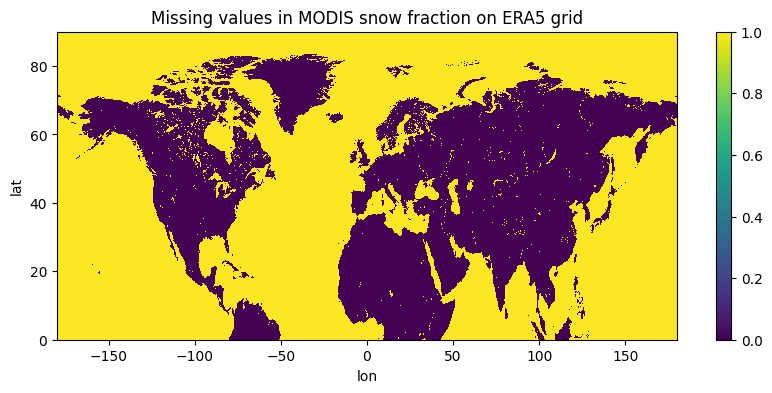

In [36]:
snow_on_era5_land.isnull().plot(
    x="lon",
    y="lat",
    figsize=(10, 4)
)

plt.title("Missing values in MODIS snow fraction on ERA5 grid")
plt.show() # Yellow = NaN / missing

In [37]:
inside_any_basin = mask3d_era5_land.any(dim="region")
n_inside = int(inside_any_basin.sum())
n_nan_inside = int(
    (snow_on_era5_land.isnull() & inside_any_basin).sum()
)

print("Total ERA5-Land cells inside basin domain:", n_inside)
print("Snow NaNs inside basin domain:", n_nan_inside)
print("Percent missing inside basin domain:", 100 * n_nan_inside / n_inside)

Total ERA5-Land cells inside basin domain: 945165
Snow NaNs inside basin domain: 33963
Percent missing inside basin domain: 3.593340845249242


In [38]:
# missingness by basin, because a modest overall percentage could still
# mean a few individual basins have poor MODIS coverage.

# Number of ERA5-Land cells in each basin
basin_cells = mask3d_era5_land.sum(dim=["lat", "lon"])

# Number of missing-snow cells in each basin
missing_snow_cells = (mask3d_era5_land & snow_on_era5_land.isnull()).sum(dim=["lat", "lon"])

# Fraction missing for each basin
missing_snow_frac = (missing_snow_cells / basin_cells)

print(missing_snow_frac.to_series().describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

print("Basins >10% missing:", int((missing_snow_frac > 0.10).sum()))
print("Basins >25% missing:", int((missing_snow_frac > 0.25).sum()))
print("Basins >50% missing:", int((missing_snow_frac > 0.50).sum()))

# 591 basins have at least one ERA5-Land cell.
# Median basin has about 2.6% of its ERA5-Land cells missing snow data.

# 143 basins have >10% missing snow cells.
# 48 basins have >25% missing snow cells.
# 31 basins have >50% missing snow cells.

# The 90th percentile of basin missingness is about 21.8%.
# The 95th percentile is about 52.7%.
# Some basins are 100% missing.

# So we should not immediately compute basin snow fraction using only
# the valid cells and move on, because for some basins that would mean
# estimating basin snow cover from only a small part of the basin.

# The likely reason is that MODIS snow-cover coverage is mostly land-only,
# while HydroBASINS polygons and ERA5-Land cell-center assignment may include
# coastal/water cells and areas outside valid MODIS coverage. Some high-latitude
# or special-surface cells may also be missing.

count    591.000000
mean       0.093830
std        0.188614
min        0.000000
50%        0.025862
90%        0.217539
95%        0.526647
99%        1.000000
max        1.000000
dtype: float64
Basins >10% missing: 143
Basins >25% missing: 48
Basins >50% missing: 31


In [39]:
# which basins have high missingness and whether they are coastal /
# mostly water / outside the MODIS valid land domain

high_missing = missing_snow_frac.where(
    missing_snow_frac > 0.25,
    drop=True
)

print(high_missing.sortby(high_missing, ascending=False).to_series().head(30))

region
568    1.000000
567    1.000000
496    1.000000
429    1.000000
427    1.000000
425    1.000000
423    1.000000
354    1.000000
353    1.000000
191    1.000000
34     1.000000
355    0.966667
171    0.900000
571    0.888889
418    0.848485
411    0.837838
447    0.833333
278    0.788462
577    0.718954
488    0.666667
50     0.642857
163    0.635468
600    0.634921
277    0.629630
359    0.616667
446    0.597826
410    0.586207
347    0.549020
166    0.547170
49     0.541667
dtype: float64


In [40]:
print(
    "Basins with 100% missing snow:",
    int((missing_snow_frac == 1).sum())
)

Basins with 100% missing snow: 11


In [41]:
# map region indices back to basin IDs/names

# Create a table of missingness by region
missing_df = missing_snow_frac.to_dataframe(
    name="missing_snow_fraction"
).reset_index()

# Mapping from regionmask region number to metadata
region_to_mainbas = {
    number: int(abbrev)
    for number, abbrev in zip(
        regions.numbers,
        regions.abbrevs
    )
}

region_to_name = {
    number: name
    for number, name in zip(
        regions.numbers,
        regions.names
    )
}

# Add basin metadata
missing_df["MAIN_BAS"] = (
    missing_df["region"]
    .map(region_to_mainbas)
)

missing_df["name"] = (
    missing_df["region"]
    .map(region_to_name)
)

# Sort from highest to lowest missingness
missing_df = missing_df.sort_values(
    "missing_snow_fraction",
    ascending=False
)

missing_df.head(30)

,region,abbrevs,names,missing_snow_fraction,MAIN_BAS,name
34,34,1040027420,basin_1040027420,1.000000,1040027420,basin_1040027420
568,568,7040055710,basin_7040055710,1.000000,7040055710,basin_7040055710
353,353,4040045780,basin_4040045780,1.000000,4040045780,basin_4040045780
354,354,4040045890,basin_4040045890,1.000000,4040045890,basin_4040045890
429,429,5040055420,basin_5040055420,1.000000,5040055420,basin_5040055420
423,423,5040040040,basin_5040040040,1.000000,5040040040,basin_5040040040
425,425,5040054880,basin_5040054880,1.000000,5040054880,basin_5040054880
567,567,7040055630,basin_7040055630,1.000000,7040055630,basin_7040055630
496,496,7040024590,basin_7040024590,1.000000,7040024590,basin_7040024590
191,191,2040068690,basin_2040068690,1.000000,2040068690,basin_2040068690


In [42]:
print(
    missing_df.loc[
        missing_df["missing_snow_fraction"] == 1,
        ["region", "MAIN_BAS", "name", "missing_snow_fraction"]
    ]
)

     region    MAIN_BAS              name  missing_snow_fraction
34       34  1040027420  basin_1040027420                    1.0
568     568  7040055710  basin_7040055710                    1.0
353     353  4040045780  basin_4040045780                    1.0
354     354  4040045890  basin_4040045890                    1.0
429     429  5040055420  basin_5040055420                    1.0
423     423  5040040040  basin_5040040040                    1.0
425     425  5040054880  basin_5040054880                    1.0
567     567  7040055630  basin_7040055630                    1.0
496     496  7040024590  basin_7040024590                    1.0
191     191  2040068690  basin_2040068690                    1.0
427     427  5040055010  basin_5040055010                    1.0


In [43]:
missing100_ids = (
    missing_df.loc[
        missing_df["missing_snow_fraction"] == 1,
        "MAIN_BAS"
    ]
    .astype("int64")
    .tolist()
)

missing100_basins = hb_simple[
    hb_simple["MAIN_BAS"].isin(missing100_ids)
].copy()

print("100% missing IDs:", len(missing100_ids))
print("Matched polygons:", missing100_basins["MAIN_BAS"].nunique())

100% missing IDs: 11
Matched polygons: 11


In [44]:
print("missing100_basins:", len(missing100_basins))

print("hb_simple MAIN_BAS dtype:", hb_simple["MAIN_BAS"].dtype)
print("missing_df MAIN_BAS dtype:", missing_df["MAIN_BAS"].dtype)

missing100_basins: 11
hb_simple MAIN_BAS dtype: int64
missing_df MAIN_BAS dtype: int64


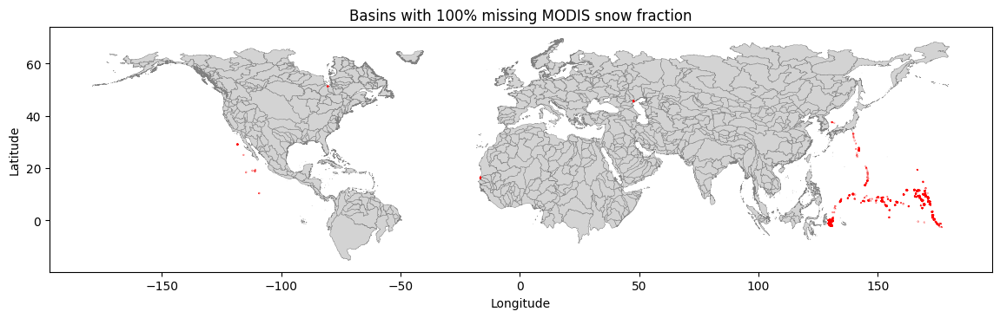

In [45]:
fig, ax = plt.subplots(figsize=(14, 8))

hb_simple.plot(
    ax=ax,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.3
)

missing100_basins.plot(
    ax=ax,
    color="red",
    edgecolor="red",
    linewidth=1.5
)

ax.set_title("Basins with 100% missing MODIS snow fraction")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [46]:
# number of valid ERA5 cells per basin
cells_per_region = mask3d_era5_land.sum(dim=["lat", "lon"])

print(cells_per_region.to_series().describe())

# regions with zero ERA5 cells
zero_cell_regions = cells_per_region.where(
    cells_per_region == 0,
    drop=True
)

print("Regions with zero ERA5 cells:", zero_cell_regions.size)
print(zero_cell_regions)

count      602.000000
mean      1570.222591
std       3886.061013
min          0.000000
25%        208.500000
50%        588.500000
75%       1353.000000
max      39982.000000
Name: mask, dtype: float64
Regions with zero ERA5 cells: 11
<xarray.DataArray 'mask' (region: 11)> Size: 88B
array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])
Coordinates:
  * region   (region) int64 88B 169 219 296 322 357 419 424 426 428 548 574
    abbrevs  (region) <U10 440B '2040056060' '2040078740' ... '7040065050'
    names    (region) <U16 704B 'basin_2040056060' ... 'basin_7040065050'


In [47]:
# ============================================================
# Area-weighted basin snow fraction
# ERA5-Land grid
# ============================================================

# Basin-area weights on ERA5-Land grid
basin_weights_snow = (
    mask3d_era5_land
    * w2d_era5_land
)

# Valid MODIS snow-data weights only
snow_valid_weights = basin_weights_snow.where(
    snow_on_era5_land.notnull()
)

# Area-weighted basin snow fraction
basin_snow_frac = (
    (snow_on_era5_land * snow_valid_weights).sum(dim=["lat", "lon"], skipna=True)
    /
    snow_valid_weights.sum(dim=["lat", "lon"])
)

# ============================================================
# Area-weighted basin cropland fraction
# ERA5 grid
# ============================================================

# Basin-area weights on ERA5 grid
basin_weights_crop = (
    mask3d_era5
    * w2d_era5
)

# Crop has no NaNs, so standard basin weights are fine
basin_crop_frac = (
    (crop_on_era5 * basin_weights_crop).sum(dim=["lat", "lon"])
    /
    basin_weights_crop.sum(dim=["lat", "lon"])
)

In [48]:
print(
    "Valid basin snow fractions:",
    int(basin_snow_frac.notnull().sum())
)

print(
    "Valid basin crop fractions:",
    int(basin_crop_frac.notnull().sum())
)

print(
    "Basins with no valid snow data:",
    int(basin_snow_frac.isnull().sum())
)

# 602 total regions
# - 11 with zero ERA5-Land cells
# = 591 basins with any ERA5-Land coverage
# And then among those 591:
# 11 have ERA5-Land cells but no valid MODIS snow values
# So: 591 - 11 = 580 valid snow basins

Valid basin snow fractions: 580
Valid basin crop fractions: 587
Basins with no valid snow data: 22


In [49]:
# inspect the distributions

print("Snow fraction:")
print(basin_snow_frac.to_series().describe())

print("\nCropland fraction:")
print(basin_crop_frac.to_series().describe())

Snow fraction:
count    580.000000
mean       0.260380
std        0.369426
min        0.000000
25%        0.000002
50%        0.017394
75%        0.443727
max        1.000000
dtype: float64

Cropland fraction:
count    587.000000
mean       0.091108
std        0.145277
min        0.000000
25%        0.000098
50%        0.014723
75%        0.127037
max        0.728911
dtype: float64


In [50]:
# Basins with no ERA5-Land cells
no_era5_land = (basin_weights_snow.sum(dim=["lat", "lon"]) == 0)

# Basins that have ERA5-Land cells but no valid MODIS snow data
no_snow = (
    (basin_weights_snow.sum(dim=["lat", "lon"]) > 0)
    &
    (snow_valid_weights.sum(dim=["lat", "lon"]) == 0)
)

print("Total regions:", mask3d_era5_land.sizes["region"])
print("No ERA5-Land cells:", int(no_era5_land.sum()))
print("ERA5-Land coverage but no MODIS snow:", int(no_snow.sum()))
print("Valid snow basins:", int(basin_snow_frac.notnull().sum()))

Total regions: 602
No ERA5-Land cells: 11
ERA5-Land coverage but no MODIS snow: 11
Valid snow basins: 580


In [51]:
thresholds = [0, 0.01, 0.025, 0.05, 0.10]

for t in thresholds:
    eligible_t = (
        basin_snow_frac.notnull()
        & (basin_snow_frac >= t)
        & (basin_crop_frac >= t)
    )

    print(
        f"{t*100:>4.1f}% threshold:",
        int(eligible_t.sum()),
        "basins"
    )

 0.0% threshold: 579 basins
 1.0% threshold: 169 basins
 2.5% threshold: 139 basins
 5.0% threshold: 114 basins
10.0% threshold: 78 basins


In [52]:
valid = basin_snow_frac.notnull() & basin_crop_frac.notnull()

print("Valid snow/crop basins:", int(valid.sum()))

print(
    "Snow >= 1%:",
    int((valid & (basin_snow_frac >= 0.01)).sum())
)

print(
    "Crop >= 1%:",
    int((valid & (basin_crop_frac >= 0.01)).sum())
)

print(
    "Both >= 1%:",
    int(
        (
            valid
            & (basin_snow_frac >= 0.01)
            & (basin_crop_frac >= 0.01)
        ).sum()
    )
)

Valid snow/crop basins: 579
Snow >= 1%: 298
Crop >= 1%: 313
Both >= 1%: 169


Eligible at 1%: 169
Eligible at 5%: 114
Added at 1% but not 5%: 55
Number of 5% eligible polygons: 114
Number of extra 1% polygons: 55
Matched 5% eligible basins: 244
Matched extra 1% basins: 101


/tmp/ipykernel_1915107/3132330992.py:100: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
/tmp/ipykernel_1915107/3132330992.py:100: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


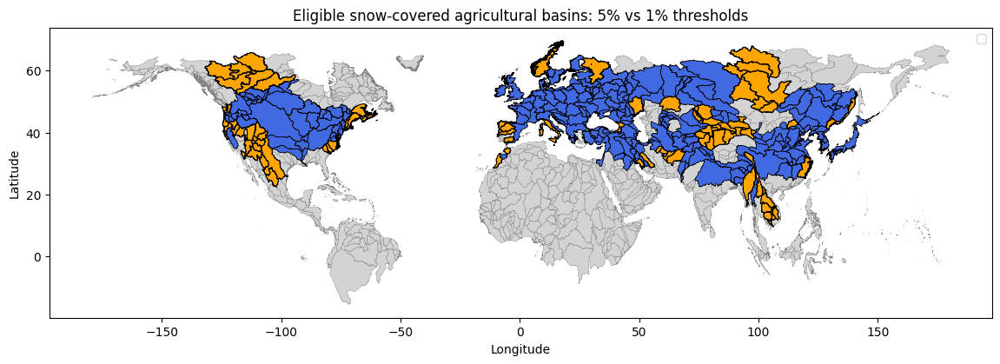

In [53]:
# 1. Define eligible basins at 1% and 5%

eligible_1 = (
    basin_snow_frac.notnull()
    & (basin_snow_frac >= 0.01)
    & (basin_crop_frac >= 0.01)
)

eligible_5 = (
    basin_snow_frac.notnull()
    & (basin_snow_frac >= 0.05)
    & (basin_crop_frac >= 0.05)
)

# Basins included at 1% but not at 5%
added_1pct = eligible_1 & (~eligible_5)

print("Eligible at 1%:", int(eligible_1.sum()))
print("Eligible at 5%:", int(eligible_5.sum()))
print("Added at 1% but not 5%:", int(added_1pct.sum()))


# 2. Build a table linking region index -> MAIN_BAS

region_summary = pd.DataFrame({
    "region": basin_snow_frac["region"].values,
    "MAIN_BAS": pd.to_numeric(regions.abbrevs, errors="coerce"),
    "eligible_1": eligible_1.values,
    "eligible_5": eligible_5.values,
    "added_1pct": added_1pct.values
})

# keep only rows with valid MAIN_BAS
region_summary = region_summary.dropna(subset=["MAIN_BAS"]).copy()
region_summary["MAIN_BAS"] = region_summary["MAIN_BAS"].astype("int64")


# 3. Extract MAIN_BAS lists for plotting

eligible5_ids = region_summary.loc[
    region_summary["eligible_5"], "MAIN_BAS"
].tolist()

added1_ids = region_summary.loc[
    region_summary["added_1pct"], "MAIN_BAS"
].tolist()

print("Number of 5% eligible polygons:", len(eligible5_ids))
print("Number of extra 1% polygons:", len(added1_ids))


# 4. Match these IDs back to the basin polygons

eligible5_basins = hb_simple[
    hb_simple["MAIN_BAS"].isin(eligible5_ids)
].copy()

added1_basins = hb_simple[
    hb_simple["MAIN_BAS"].isin(added1_ids)
].copy()

print("Matched 5% eligible basins:", len(eligible5_basins))
print("Matched extra 1% basins:", len(added1_basins))


# 5. Plot map

fig, ax = plt.subplots(figsize=(14, 8))

# all basins
hb_simple.plot(
    ax=ax,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.25,
    label="All basins"
)

# 5% eligible
eligible5_basins.plot(
    ax=ax,
    color="royalblue",
    edgecolor="black",
    linewidth=0.5,
    label="Eligible at 5%"
)

# extra basins added at 1%
added1_basins.plot(
    ax=ax,
    color="orange",
    edgecolor="black",
    linewidth=0.8,
    label="Included at 1% but excluded at 5%"
)

ax.set_title("Eligible snow-covered agricultural basins: 5% vs 1% thresholds")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
plt.show()

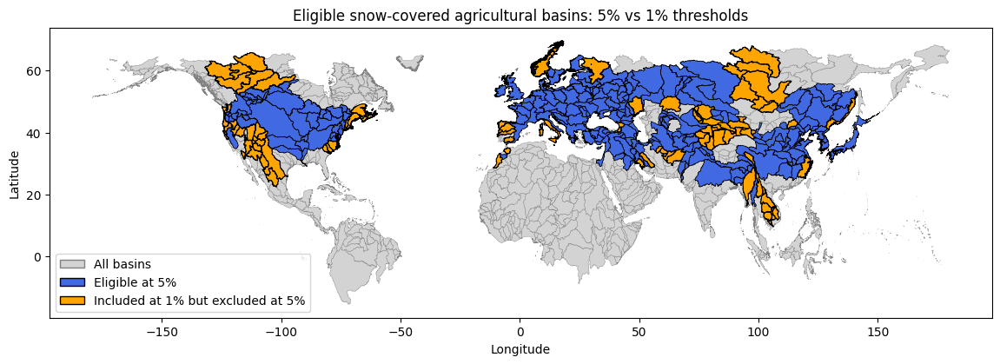

In [54]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(14, 8))

hb_simple.plot(
    ax=ax,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.25
)

eligible5_basins.plot(
    ax=ax,
    color="royalblue",
    edgecolor="black",
    linewidth=0.5
)

added1_basins.plot(
    ax=ax,
    color="orange",
    edgecolor="black",
    linewidth=0.8
)

legend_elements = [
    Patch(facecolor="lightgray", edgecolor="gray", label="All basins"),
    Patch(facecolor="royalblue", edgecolor="black", label="Eligible at 5%"),
    Patch(facecolor="orange", edgecolor="black",
          label="Included at 1% but excluded at 5%")
]

ax.legend(handles=legend_elements, loc="lower left")

ax.set_title(
    "Eligible snow-covered agricultural basins: 5% vs 1% thresholds"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [55]:
# isolate the 52 “orange” basins and inspect their actual snow and cropland fractions.
    
    # Basins eligible at 1% but not at 5%
added_1pct = eligible_1 & (~eligible_5)

# Create table
added_df = pd.DataFrame({
    "region": basin_snow_frac["region"].values,
    "snow_frac": basin_snow_frac.values,
    "crop_frac": basin_crop_frac.values,
    "added_1pct": added_1pct.values
})

# Keep only the 1%-but-not-5% basins
added_df = added_df[added_df["added_1pct"]].copy()

# Convert fractions to percentages for easier interpretation
added_df["snow_pct"] = added_df["snow_frac"] * 100
added_df["crop_pct"] = added_df["crop_frac"] * 100

print("Number of added basins:", len(added_df))

print("\nSnow %:")
print(
    added_df["snow_pct"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

print("\nCropland %:")
print(
    added_df["crop_pct"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

Number of added basins: 55

Snow %:
count    55.000000
mean     31.311357
std      33.294954
min       1.121851
10%       1.406994
25%       2.900942
50%      17.759561
75%      53.210814
90%      87.723483
max      99.455836
Name: snow_pct, dtype: float64

Cropland %:
count    55.000000
mean      7.547537
std       9.084480
min       1.093626
10%       1.274630
25%       1.806553
50%       3.947218
75%       7.380340
90%      18.610769
max      43.196256
Name: crop_pct, dtype: float64


In [56]:
# check which variable caused each basin to fail the 5% criterion:

added_df["reason"] = np.select(
    [
        (added_df["snow_pct"] < 5) & (added_df["crop_pct"] < 5),
        added_df["snow_pct"] < 5,
        added_df["crop_pct"] < 5
    ],
    [
        "Both snow and crop <5%",
        "Snow <5%",
        "Crop <5%"
    ],
    default="Other"
)

print("\nWhy excluded at 5%:")
print(added_df["reason"].value_counts())


Why excluded at 5%:
reason
Crop <5%                  34
Snow <5%                  16
Both snow and crop <5%     5
Name: count, dtype: int64


In [57]:
print(
    added_df[
        ["snow_pct", "crop_pct", "reason"]
    ]
    .sort_values(["snow_pct", "crop_pct"])
    .to_string(index=False)
)

 snow_pct  crop_pct                 reason
 1.121851  5.941276               Snow <5%
 1.148576  5.818692               Snow <5%
 1.167373 26.515236               Snow <5%
 1.175690 18.656026               Snow <5%
 1.196620 18.542884               Snow <5%
 1.334051  4.186346 Both snow and crop <5%
 1.516409 21.749151               Snow <5%
 1.645196 43.196256               Snow <5%
 1.827499 17.521045               Snow <5%
 2.027977 16.706399               Snow <5%
 2.090049 18.373555               Snow <5%
 2.395433 18.475220               Snow <5%
 2.517136 10.946043               Snow <5%
 2.874081  8.819404               Snow <5%
 2.927804  1.825826 Both snow and crop <5%
 3.060015 23.342531               Snow <5%
 4.029453  3.494657 Both snow and crop <5%
 4.060035 15.820163               Snow <5%
 4.197618  2.484697 Both snow and crop <5%
 4.454145 33.875927               Snow <5%
 4.481014  4.156500 Both snow and crop <5%
 6.512995  3.606272               Crop <5%
 7.689876  

In [58]:
print(
    "Cropland 1–2%:",
    ((added_df["crop_pct"] >= 1) &
     (added_df["crop_pct"] < 2)).sum()
)

print(
    "Cropland 2–5%:",
    ((added_df["crop_pct"] >= 2) &
     (added_df["crop_pct"] < 5)).sum()
)

print(
    "Snow 1–2%:",
    ((added_df["snow_pct"] >= 1) &
     (added_df["snow_pct"] < 2)).sum()
)

print(
    "Snow 2–5%:",
    ((added_df["snow_pct"] >= 2) &
     (added_df["snow_pct"] < 5)).sum()
)

print(
    "Both snow and crop between 1–2%:",
    (
        (added_df["snow_pct"] < 2)
        & (added_df["crop_pct"] < 2)
    ).sum()
)

Cropland 1–2%: 16
Cropland 2–5%: 23
Snow 1–2%: 9
Snow 2–5%: 12
Both snow and crop between 1–2%: 0


In [59]:
valid = basin_snow_frac.notnull() & basin_crop_frac.notnull()

screen_class = xr.full_like(
    basin_snow_frac,
    fill_value=0,
    dtype=int
)

# 1 = eligible
screen_class = xr.where(
    valid
    & (basin_snow_frac >= 0.01)
    & (basin_crop_frac >= 0.01),
    1,
    screen_class
)

# 2 = snow <1% only
screen_class = xr.where(
    valid
    & (basin_snow_frac < 0.01)
    & (basin_crop_frac >= 0.01),
    2,
    screen_class
)

# 3 = crop <1% only
screen_class = xr.where(
    valid
    & (basin_snow_frac >= 0.01)
    & (basin_crop_frac < 0.01),
    3,
    screen_class
)

# 4 = both <1%
screen_class = xr.where(
    valid
    & (basin_snow_frac < 0.01)
    & (basin_crop_frac < 0.01),
    4,
    screen_class
)

In [60]:
# Build a DataFrame linking region -> MAIN_BAS -> screening class

screen_df = pd.DataFrame({
    "region": basin_snow_frac["region"].values,
    "MAIN_BAS": pd.to_numeric(regions.abbrevs, errors="coerce"),
    "screen_class": screen_class.values
})

screen_df = screen_df.dropna(subset=["MAIN_BAS"]).copy()
screen_df["MAIN_BAS"] = screen_df["MAIN_BAS"].astype("int64")


# Join screening class to basin polygons
hb_screen = hb_simple.merge(
    screen_df[["MAIN_BAS", "screen_class"]],
    on="MAIN_BAS",
    how="left"
)

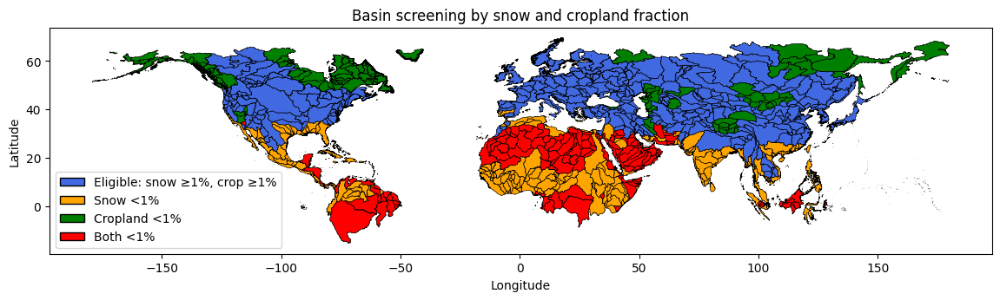

In [61]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(14, 8))

# base
hb_screen.plot(
    ax=ax,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.25
)

# eligible
hb_screen[hb_screen["screen_class"] == 1].plot(
    ax=ax,
    color="royalblue",
    edgecolor="black",
    linewidth=0.4
)

# snow <1%
hb_screen[hb_screen["screen_class"] == 2].plot(
    ax=ax,
    color="orange",
    edgecolor="black",
    linewidth=0.4
)

# crop <1%
hb_screen[hb_screen["screen_class"] == 3].plot(
    ax=ax,
    color="green",
    edgecolor="black",
    linewidth=0.4
)

# both <1%
hb_screen[hb_screen["screen_class"] == 4].plot(
    ax=ax,
    color="red",
    edgecolor="black",
    linewidth=0.4
)

legend_elements = [
    Patch(facecolor="royalblue", edgecolor="black", label="Eligible: snow ≥1%, crop ≥1%"),
    Patch(facecolor="orange", edgecolor="black", label="Snow <1%"),
    Patch(facecolor="green", edgecolor="black", label="Cropland <1%"),
    Patch(facecolor="red", edgecolor="black", label="Both <1%"),
]

ax.legend(handles=legend_elements, loc="lower left")

ax.set_title("Basin screening by snow and cropland fraction")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

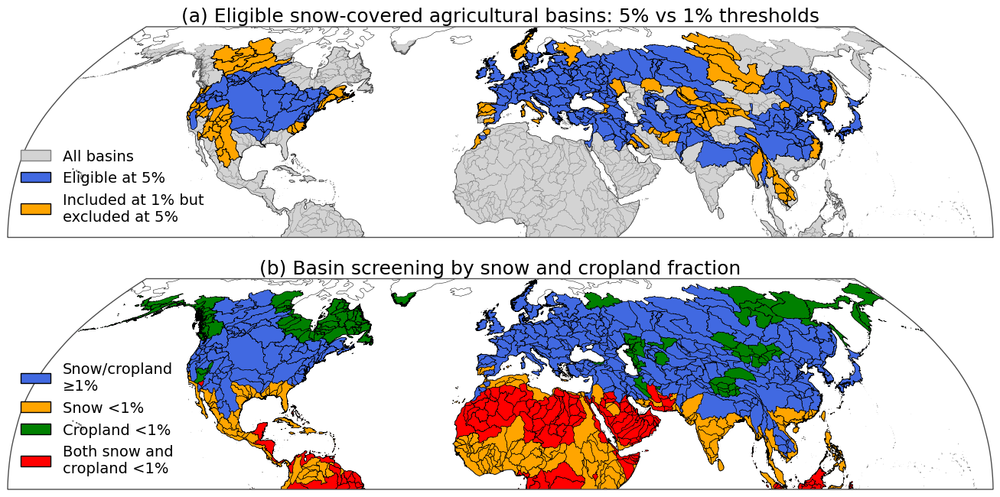

In [62]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Patch


# ============================================================
# Figure layout
# ============================================================
fig = plt.figure(figsize=(14, 9))

# Equal-sized axes with less space between them
ax1 = fig.add_axes(
    [0.04, 0.54, 0.92, 0.36],
    projection=ccrs.Robinson()
)

ax2 = fig.add_axes(
    [0.04, 0.12, 0.92, 0.36],
    projection=ccrs.Robinson()
)


# ============================================================
# Common map styling
# ============================================================
def style_map(ax, title):

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    # Ensure that both panels use the same map aspect ratio
    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.coastlines(linewidth=0.35)

    # Keep the Robinson projection boundary visible
    if "geo" in ax.spines:
        ax.spines["geo"].set_visible(True)
        ax.spines["geo"].set_linewidth(1.0)
        ax.spines["geo"].set_edgecolor("0.3")

    # Remove longitude and latitude ticks
    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_title(
        title,
        fontsize=18,
        pad=5
    )


# ============================================================
# (a) 5% vs 1% threshold
# ============================================================
hb_simple.plot(
    ax=ax1,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.25,
    transform=ccrs.PlateCarree()
)

eligible5_basins.plot(
    ax=ax1,
    color="royalblue",
    edgecolor="black",
    linewidth=0.45,
    transform=ccrs.PlateCarree()
)

added1_basins.plot(
    ax=ax1,
    color="orange",
    edgecolor="black",
    linewidth=0.55,
    transform=ccrs.PlateCarree()
)

style_map(
    ax1,
    "(a) Eligible snow-covered agricultural basins: "
    "5% vs 1% thresholds"
)

legend_elements_a = [
    Patch(
        facecolor="lightgray",
        edgecolor="gray",
        label="All basins"
    ),
    Patch(
        facecolor="royalblue",
        edgecolor="black",
        label="Eligible at 5%"
    ),
    Patch(
        facecolor="orange",
        edgecolor="black",
        label="Included at 1% but\nexcluded at 5%"
    )
]

ax1.legend(
    handles=legend_elements_a,
    loc="lower left",
    frameon=False,
    fontsize=14
)


# ============================================================
# (b) Basin screening classes
# ============================================================
hb_screen.plot(
    ax=ax2,
    color="lightgray",
    edgecolor="gray",
    linewidth=0.25,
    transform=ccrs.PlateCarree()
)

hb_screen[
    hb_screen["screen_class"] == 1
].plot(
    ax=ax2,
    color="royalblue",
    edgecolor="black",
    linewidth=0.40,
    transform=ccrs.PlateCarree()
)

hb_screen[
    hb_screen["screen_class"] == 2
].plot(
    ax=ax2,
    color="orange",
    edgecolor="black",
    linewidth=0.40,
    transform=ccrs.PlateCarree()
)

hb_screen[
    hb_screen["screen_class"] == 3
].plot(
    ax=ax2,
    color="green",
    edgecolor="black",
    linewidth=0.40,
    transform=ccrs.PlateCarree()
)

hb_screen[
    hb_screen["screen_class"] == 4
].plot(
    ax=ax2,
    color="red",
    edgecolor="black",
    linewidth=0.40,
    transform=ccrs.PlateCarree()
)

style_map(
    ax2,
    "(b) Basin screening by snow and cropland fraction"
)

legend_elements_b = [
    Patch(
        facecolor="royalblue",
        edgecolor="black",
        label="Snow/cropland\n≥1%"
    ),
    Patch(
        facecolor="orange",
        edgecolor="black",
        label="Snow <1%"
    ),
    Patch(
        facecolor="green",
        edgecolor="black",
        label="Cropland <1%"
    ),
    Patch(
        facecolor="red",
        edgecolor="black",
        label="Both snow and\ncropland <1%"
    )
]

ax2.legend(
    handles=legend_elements_b,
    loc="lower left",
    frameon=False,
    fontsize=14
)


# ============================================================
# Match panel dimensions and reduce internal white space
# ============================================================

# Anchor the maps toward each other
ax1.set_anchor("S")
ax2.set_anchor("N")


# ============================================================
# Save
# ============================================================
plt.savefig(
    "Fig_S1.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.04
)

plt.show()

In [63]:
# apply the 1% screening only where snow is valid:

eligible = (
    basin_snow_frac.notnull()
    & (basin_snow_frac >= 0.01)
    & (basin_crop_frac >= 0.01)
)

print("Eligible basins:", int(eligible.sum()))

eligible_df = pd.DataFrame({
    "region": basin_snow_frac["region"].values,
    "MAIN_BAS": [int(regions.abbrevs[i]) for i in basin_snow_frac["region"].values],
    "snow_frac": basin_snow_frac.values,
    "crop_frac": basin_crop_frac.values,
    "eligible": eligible.values,
    "eligible_1pct": eligible_1.values,
    "eligible_5pct": eligible_5.values,
    "missing_snow_frac": missing_snow_frac.values
})

eligible_df = eligible_df[eligible_df["eligible"]].copy()

eligible_main_bas = eligible_df["MAIN_BAS"].tolist()

print("Final eligible basins:", len(eligible_main_bas))

Eligible basins: 169
Final eligible basins: 169


In [64]:
eligible_df.to_csv(
    "/home/mgurazada/snowdroughts_thirst/data/eligible_main_bas.csv",
    index=False
)

In [65]:
# Snow-weighted basin weights -- fractional snow weights for SWE aggregation
snow_weights = (
    basin_weights_snow * snow_on_era5_land
).where(snow_on_era5_land.notnull())

# Cropland-weighted basin weights -- fractional cropland weights for ETo aggregation
crop_weights = basin_weights_crop * crop_on_era5

In [66]:
# compute basin-level monthly SWE and ETo

# Stack spatial dimensions once
SPATIAL_DIM = "z"

# ============================================================
# SWE side: ERA5-Land grid
# ============================================================

swe_s = era5_land_data["swe"].stack(
    {SPATIAL_DIM: ("lat", "lon")}
)

w_s_snow = w2d_era5_land.stack(
    {SPATIAL_DIM: ("lat", "lon")}
)

snow_s = snow_on_era5_land.stack(
    {SPATIAL_DIM: ("lat", "lon")}
)


# ============================================================
# ETo side: ERA5 grid
# ============================================================

eto_s = era5_data["eto"].stack(
    {SPATIAL_DIM: ("lat", "lon")}
)

w_s_crop = w2d_era5.stack(
    {SPATIAL_DIM: ("lat", "lon")}
)

crop_s = crop_on_era5.stack(
    {SPATIAL_DIM: ("lat", "lon")}
)

In [67]:
eligible_regions = eligible["region"].where(
    eligible,
    drop=True
).values

print("Eligible regions:", len(eligible_regions))

Eligible regions: 169


In [68]:
# calculate SWE basin-by-basin

swe_list = []

for r in eligible_regions:

    # cells belonging to this MAIN_BAS
    basin_mask_s = mask3d_era5_land.sel(region=r).stack(
        {SPATIAL_DIM: ("lat", "lon")}
    )

    # only cells inside basin with valid snow fraction
    valid_cells = (
        basin_mask_s
        & snow_s.notnull()
        & (snow_s > 0)
    )

    idx = np.where(valid_cells.values)[0]

    # fractional snow × latitude-area weight
    weights_r = (
        w_s_snow.isel(z=idx)
        * snow_s.isel(z=idx)
    )

    swe_r = swe_s.isel(z=idx)

    basin_mean = (
        (swe_r * weights_r).sum(dim="z")
        /
        weights_r.sum(dim="z")
    )

    basin_mean = basin_mean.expand_dims(region=[r])

    swe_list.append(basin_mean)

swe_all = xr.concat(swe_list, dim="region")

In [69]:
# calculate ETo basin-by-basin

eto_list = []

for r in eligible_regions:

    basin_mask_s = mask3d_era5.sel(region=r).stack(
        {SPATIAL_DIM: ("lat", "lon")}
    )

    valid_cells = (
        basin_mask_s
        & crop_s.notnull()
        & (crop_s > 0)
    )

    idx = np.where(valid_cells.values)[0]

    # fractional cropland × latitude-area weight
    weights_r = (
        w_s_crop.isel(z=idx)
        * crop_s.isel(z=idx)
    )

    eto_r = eto_s.isel(z=idx)

    basin_mean = (
        (eto_r * weights_r).sum(dim="z")
        /
        weights_r.sum(dim="z")
    )

    basin_mean = basin_mean.expand_dims(region=[r])

    eto_list.append(basin_mean)

eto_all = xr.concat(eto_list, dim="region")

In [70]:
print("swe_all:", swe_all.dims, swe_all.shape)
print("eto_all:", eto_all.dims, eto_all.shape)

swe_all: ('region', 'time') (169, 900)
eto_all: ('region', 'time') (169, 900)


In [71]:
print("SWE basins with all NaN:", int(swe_all.isnull().all("time").sum()))
print("ETo basins with all NaN:", int(eto_all.isnull().all("time").sum()))

print("SWE range:", float(swe_all.min(skipna=True)), float(swe_all.max(skipna=True)))
print("ETo range:", float(eto_all.min(skipna=True)), float(eto_all.max(skipna=True)))

SWE basins with all NaN: 0
ETo basins with all NaN: 0
SWE range: -7.3453648492129225e-22 1604.0046580138523
ETo range: 0.29580272968070015 388.5807576093678


In [72]:
# ============================================================
# Reindex back to the complete 602-region coordinate
# ============================================================

full_region = mask3d_era5_land["region"]

# ERA5 and ERA5-Land masks should represent the same basin regions
assert np.array_equal(
    mask3d_era5_land["region"].values,
    mask3d_era5["region"].values
)

swe_all = swe_all.reindex(
    region=full_region
)

eto_all = eto_all.reindex(
    region=full_region
)

eligible = eligible.reindex(
    region=full_region
)

basin_snow_frac = basin_snow_frac.reindex(
    region=full_region
)

basin_crop_frac = basin_crop_frac.reindex(
    region=full_region
)

In [73]:
print("SWE shape:", swe_all.shape)
print("ETo shape:", eto_all.shape)

print("SWE regions:", swe_all.sizes["region"])
print("ETo regions:", eto_all.sizes["region"])

print("SWE all-NaN basins:", int(swe_all.isnull().all("time").sum()))
print("ETo all-NaN basins:", int(eto_all.isnull().all("time").sum()))

SWE shape: (602, 900)
ETo shape: (602, 900)
SWE regions: 602
ETo regions: 602
SWE all-NaN basins: 433
ETo all-NaN basins: 433


In [74]:
basin_snow_frac = basin_snow_frac.reindex(region=full_region)
basin_crop_frac = basin_crop_frac.reindex(region=full_region)

In [75]:
def water_year_from_time(da_time):
    # Water year Oct–Sep, labeled by ending year
    t = pd.to_datetime(da_time.values)
    wy = t.year + (t.month >= 10).astype(int)
    return xr.DataArray(wy, dims=("time",), coords={"time": da_time}, name="wy")

# WY coordinate
wy = water_year_from_time(swe_all["time"])

# Choose seasons
SWE_MONTHS = [12, 1, 2, 3]      # Dec–Mar
ETO_MONTHS = [4, 5, 6, 7, 8, 9]    # Apr–Sep

# Subset months + attach WY
swe_season = swe_all.where(swe_all["time"].dt.month.isin(SWE_MONTHS), drop=True)
eto_season = eto_all.where(eto_all["time"].dt.month.isin(ETO_MONTHS), drop=True)

swe_season = swe_season.assign_coords(wy=wy.sel(time=swe_season.time))
eto_season = eto_season.assign_coords(wy=wy.sel(time=eto_season.time))

# WY metrics: SWE peak (winter), ETo summer mean
swe_peak = swe_season.groupby("wy").max("time")      # dims: (wy, region)
eto_summer = eto_season.groupby("wy").mean("time")   # dims: (wy, region)

print("swe_peak:", swe_peak.dims, swe_peak.shape)
print("eto_summer:", eto_summer.dims, eto_summer.shape)

# For each water year and basin, computes maximum winter SWE and mean warm-season ETo.

swe_peak: ('region', 'wy') (602, 76)
eto_summer: ('region', 'wy') (602, 75)


In [76]:
# water-year alignment check between your seasonal SWE and ETo datasets.
# WYs present in each dataset
wy_swe = set(swe_peak.wy.values)
wy_eto = set(eto_summer.wy.values)

print("First SWE WY:", min(wy_swe), " Last SWE WY:", max(wy_swe))
print("First ETo WY:", min(wy_eto), " Last ETo WY:", max(wy_eto))

# Which WYs exist in SWE but not ETo?
only_in_swe = sorted(wy_swe - wy_eto)

# Which WYs exist in ETo but not SWE?
only_in_eto = sorted(wy_eto - wy_swe)

print("\nWY only in SWE:", only_in_swe)
print("WY only in ETo:", only_in_eto)

First SWE WY: 1950  Last SWE WY: 2025
First ETo WY: 1950  Last ETo WY: 2024

WY only in SWE: [np.int64(2025)]
WY only in ETo: []


In [77]:
# Keep only complete paired water years
swe_peak = swe_peak.sel(wy=slice(1951, 2024))
eto_summer = eto_summer.sel(wy=slice(1951, 2024))

In [78]:
q_lo, q_hi = 0.40, 0.60

# Ensure same WYs
swe_peak, eto_summer = xr.align(swe_peak, eto_summer, join="inner")

# Valid basin-years (both metrics exist)
valid_wy = np.isfinite(swe_peak) & np.isfinite(eto_summer)

# thresholds per basin (computed only from valid years)
swe_tlow  = swe_peak.where(valid_wy).quantile(q_lo, dim="wy", skipna=True)
eto_thigh = eto_summer.where(valid_wy).quantile(q_hi, dim="wy", skipna=True)

low_swe  = (swe_peak <= swe_tlow) & valid_wy
high_eto = (eto_summer >= eto_thigh) & valid_wy

normal        = (~low_swe) & (~high_eto) & valid_wy
low_swe_only  = (low_swe) & (~high_eto) & valid_wy
high_eto_only = (~low_swe) & (high_eto) & valid_wy
compound      = (low_swe) & (high_eto) & valid_wy

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


In [79]:
print("swe_peak:", swe_peak.dims, swe_peak.shape)
print("eto_summer:", eto_summer.dims, eto_summer.shape)

swe_peak: ('region', 'wy') (602, 74)
eto_summer: ('region', 'wy') (602, 74)


In [80]:
print("WY range:", int(swe_peak.wy.min()), "-", int(swe_peak.wy.max()))
print("Number of WYs:", swe_peak.sizes["wy"])

WY range: 1951 - 2024
Number of WYs: 74


In [81]:
bid = 7040007830
r = main_ids_valid.index(bid)
wy_vals = swe_peak.wy.values.astype(int)

print("Basin", bid, "region", r)

# How many valid WYs exist?
valid_r = valid_wy.sel(region=r)
print("Valid WY count:", int(valid_r.sum()))

# Show if the basin has any data at all
print("Any SWE data:", bool(np.isfinite(swe_peak.isel(region=r)).any()))
print("Any ETo data:", bool(np.isfinite(eto_summer.isel(region=r)).any()))

# If no valid years, show why (SWE missing vs ETo missing)
if int(valid_r.sum()) == 0:
    n_swe = int(np.isfinite(swe_peak.isel(region=r)).sum())
    n_eto = int(np.isfinite(eto_summer.isel(region=r)).sum())
    print("Finite SWE years:", n_swe)
    print("Finite ETo years:", n_eto)

# Only print years for classes where valid
def years_where(mask_da):
    m = mask_da.isel(region=r).values
    return wy_vals[m]

print("normal WYs:", years_where(normal))
print("low SWE only WYs:", years_where(low_swe_only))
print("high ETo only WYs:", years_where(high_eto_only))
print("compound WYs:", years_where(compound))

Basin 7040007830 region 455
Valid WY count: 0
Any SWE data: False
Any ETo data: False
Finite SWE years: 0
Finite ETo years: 0
normal WYs: []
low SWE only WYs: []
high ETo only WYs: []
compound WYs: []


In [82]:
good_bids = []

for r, bid in enumerate(main_ids_valid):
    n_valid = int(valid_wy.isel(region=r).sum())
    n_compound = int(compound.isel(region=r).sum())
    n_low_swe = int(low_swe_only.isel(region=r).sum())
    n_high_eto = int(high_eto_only.isel(region=r).sum())
    n_normal = int(normal.isel(region=r).sum())

    if (n_valid > 0 and (n_compound > 0 or n_low_swe > 0 or n_high_eto > 0)):
        good_bids.append({
            "region": r,
            "MAIN_BAS": bid,
            "valid_years": n_valid,
            "low_swe_only": n_low_swe,
            "high_eto_only": n_high_eto,
            "compound": n_compound,
            "normal": n_normal
        })

good_df = pd.DataFrame(good_bids)
good_df

,region,MAIN_BAS,valid_years,low_swe_only,high_eto_only,compound,normal
0,39,1040028970,74,15,15,15,29
1,40,1040029430,74,14,14,16,30
2,42,1040029700,74,15,15,15,29
3,105,2040000010,74,16,16,14,28
4,106,2040003440,74,16,16,14,28
...,...,...,...,...,...,...,...
164,580,7040073620,74,15,15,15,29
165,581,7040073630,74,16,16,14,28
166,583,7040073720,74,15,15,15,29
167,584,7040073780,74,13,13,17,31


In [83]:
good_df["valid_years"].value_counts()

valid_years
74    169
Name: count, dtype: int64

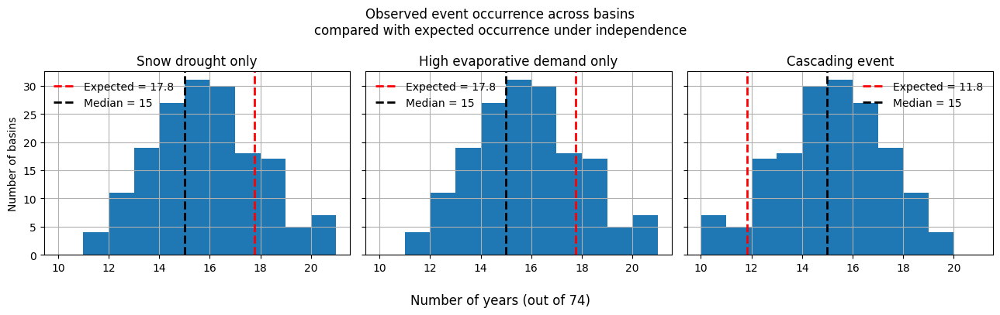

In [84]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    sharex=True,
    sharey=True
)

vars_to_plot = [
    ("low_swe_only", "Snow drought only", 74 * 0.4 * 0.6),
    ("high_eto_only", "High evaporative demand only", 74 * 0.6 * 0.4),
    ("compound", "Cascading event", 74 * 0.4 * 0.4)
]

for i, (ax, (col, title, expected)) in enumerate(zip(axes, vars_to_plot)):

    good_df[col].hist(
        bins=np.arange(
            good_df[col].min(),
            good_df[col].max() + 2
        ),
        ax=ax
    )

    # expected under independence
    ax.axvline(
        expected,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Expected = {expected:.1f}"
    )

    # observed median
    median = good_df[col].median()

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median:.0f}"
    )

    ax.set_title(title)

    # only left panel gets y label
    if i == 0:
        ax.set_ylabel("Number of basins")

    # remove repeated y labels/ticks
    if i > 0:
        ax.set_ylabel("")
        ax.tick_params(labelleft=False)

    ax.legend(frameon=False)

# common x label
fig.supxlabel("Number of years (out of 74)")

plt.suptitle(
    "Observed event occurrence across basins\n"
    "compared with expected occurrence under independence"
)

plt.tight_layout()
plt.show()

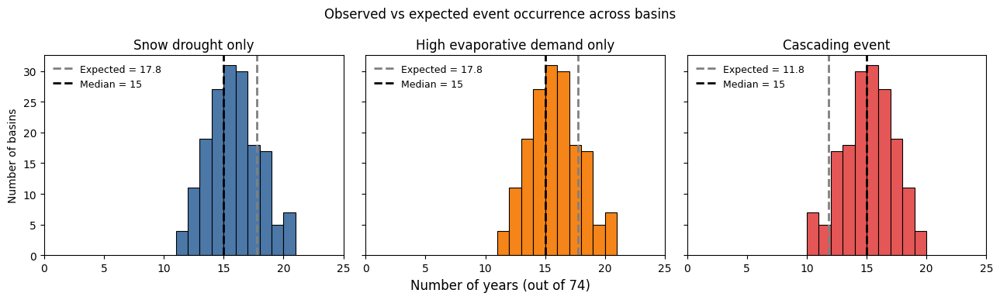

In [85]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    sharex=True,
    sharey=True
)

vars_to_plot = [
    ("low_swe_only", "Snow drought only", 74 * 0.4 * 0.6, "#4C78A8"),   # blue
    ("high_eto_only", "High evaporative demand only", 74 * 0.6 * 0.4, "#F58518"), # orange
    ("compound", "Cascading event", 74 * 0.4 * 0.4, "#E45756")          # red
]

for i, (ax, (col, title, expected, color)) in enumerate(zip(axes, vars_to_plot)):

    ax.hist(
        good_df[col],
        bins=np.arange(
            good_df[col].min(),
            good_df[col].max() + 2
        ),
        color=color,
        edgecolor="black",
        linewidth=0.8
    )

    # expected under independence
    ax.axvline(
        expected,
        color="0.5",      # gray
        linestyle="--",
        linewidth=2,
        label=f"Expected = {expected:.1f}"
    )

    # observed median
    median = good_df[col].median()

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median:.0f}"
    )

    ax.set_title(title)

    if i == 0:
        ax.set_ylabel("Number of basins")
    else:
        ax.tick_params(labelleft=False)

    ax.legend(
        frameon=False,
        fontsize=9
    )

fig.supxlabel("Number of years (out of 74)", y=0.06)

plt.suptitle(
    "Observed vs expected event occurrence across basins"
)

for ax in axes:
    ax.set_xlim(0, 25)
    
plt.tight_layout()
plt.show()

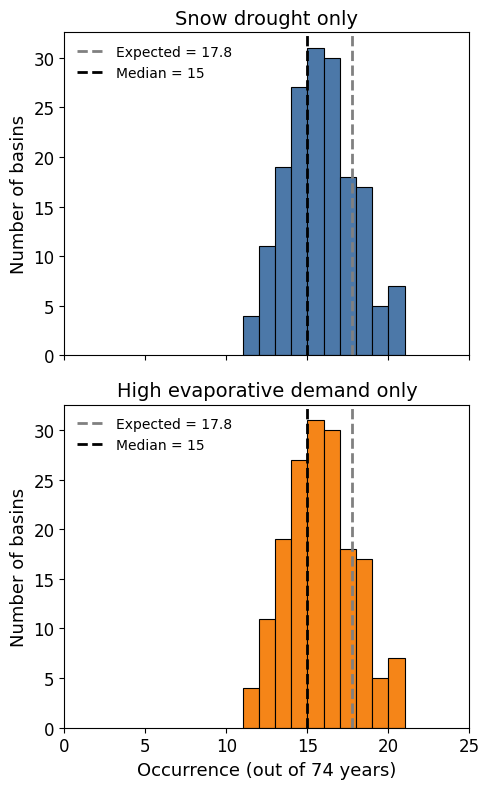

In [86]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(5, 8),
    sharex=True,
    sharey=True
)

vars_to_plot = [
    ("low_swe_only", "Snow drought only", 74 * 0.4 * 0.6, "#4C78A8"),
    ("high_eto_only", "High evaporative demand only", 74 * 0.6 * 0.4, "#F58518")
]

for i, (ax, (col, title, expected, color)) in enumerate(zip(axes, vars_to_plot)):

    ax.hist(
        good_df[col],
        bins=np.arange(
            good_df[col].min(),
            good_df[col].max() + 2
        ),
        color=color,
        edgecolor="black",
        linewidth=0.8
    )

    ax.axvline(
        expected,
        color="0.5",
        linestyle="--",
        linewidth=2,
        label=f"Expected = {expected:.1f}"
    )

    median = good_df[col].median()

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median:.0f}"
    )

    ax.set_title(
        title,
        fontsize=14
    )

    ax.set_ylabel(
        "Number of basins",
        fontsize=13
    )

    ax.tick_params(
        axis="both",
        labelsize=12
    )

    ax.legend(
    loc="upper left",
    frameon=False,
    fontsize=10,
    handlelength=2
    )

    ax.set_xlim(0, 25)

axes[-1].set_xlabel(
    "Occurrence (out of 74 years)",
    fontsize=13
)

plt.tight_layout()

plt.show()

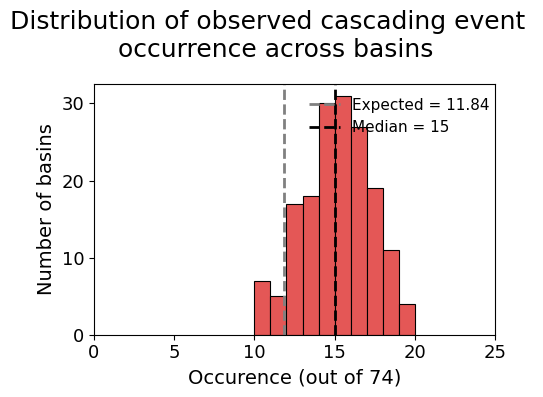

In [87]:
fig, ax = plt.subplots(
    figsize=(5, 4)
)

expected = 74 * 0.4 * 0.4  

ax.hist(
    good_df["compound"],
    bins=np.arange(
        good_df["compound"].min(),
        good_df["compound"].max() + 2
    ),
    color="#E45756",
    edgecolor="black",
    linewidth=0.8
)

# expected under independence
ax.axvline(
    expected,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected:.2f}"
)

# observed median
median = good_df["compound"].median()

ax.axvline(
    median,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median:.0f}"
)

ax.set_xlim(0, 25)

ax.set_xlabel("Occurence (out of 74)", fontsize=14)
ax.set_ylabel("Number of basins", fontsize=14)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.02, 1.0),  # move right + slightly down
    frameon=False,
    fontsize=11,
    handlelength=2
)

ax.tick_params(
    axis="both",
    labelsize=13
)


plt.suptitle(
    "Distribution of observed cascading event \n occurrence across basins", fontsize=18
)

plt.tight_layout()
plt.show()

In [88]:
# hb.columns

In [89]:
# bid = 7040007830

# ax = hb_simple.loc[hb_simple["MAIN_BAS"] == bid].plot(figsize=(8, 8))

# ax.set_title(f"MAIN_BAS {bid}")

In [90]:
# ------------------------------------------------------------
# Basin-level counts + frequencies of each class (robust)
#  - keeps ALL basins (0..len(main_ids_valid)-1)
#  - basins with no valid WYs stay NaN (so they plot as missing/gray)
#  - freq_sum is only computed when all 4 components exist
# ------------------------------------------------------------

# 1) Denominator: WYs with both metrics (per basin)
valid_wy = np.isfinite(swe_peak) & np.isfinite(eto_summer)   # dims: (wy, region)

# Make a FULL region axis so everything lines up (important!)
full_region = xr.DataArray(np.arange(len(main_ids_valid)), dims="region", name="region")

# Ensure all event arrays use the full 602-region axis
valid_wy = valid_wy.reindex(region=full_region)

compound      = compound.reindex(region=full_region)
low_swe_only  = low_swe_only.reindex(region=full_region)
high_eto_only = high_eto_only.reindex(region=full_region)
normal        = normal.reindex(region=full_region)

n_years = valid_wy.sum("wy")  # dims: (region)

# 2) Counts (restrict to valid WYs)
n_compound = (compound & valid_wy).sum("wy")
n_low      = (low_swe_only & valid_wy).sum("wy")
n_high     = (high_eto_only & valid_wy).sum("wy")
n_normal   = (normal & valid_wy).sum("wy")

# 3) Frequencies (NaN where n_years == 0)
freq_compound = xr.where(n_years > 0, n_compound / n_years, np.nan)
freq_low      = xr.where(n_years > 0, n_low      / n_years, np.nan)
freq_high     = xr.where(n_years > 0, n_high     / n_years, np.nan)
freq_normal   = xr.where(n_years > 0, n_normal   / n_years, np.nan)

# 4) xarray sanity check (only meaningful where n_years > 0)
freq_sum = freq_compound + freq_low + freq_high + freq_normal
print(freq_sum.where(n_years > 0).to_series().describe())

# ------------------------------------------------------------
# Convert to dataframe (ALL basins, by MAIN_BAS)
# ------------------------------------------------------------

freq_df = pd.DataFrame({
    "region": full_region.values.astype(int),
    "MAIN_BAS": main_ids_valid,

    "n_years": n_years.values,
    "n_compound": n_compound.values,
    "n_low_swe_only": n_low.values,
    "n_high_eto_only": n_high.values,
    "n_normal": n_normal.values,

    "freq_compound": freq_compound.values,
    "freq_low_swe_only": freq_low.values,
    "freq_high_eto_only": freq_high.values,
    "freq_normal": freq_normal.values,
})

# Strict freq_sum: only compute if all 4 frequencies exist (otherwise NaN)
cols = ["freq_compound", "freq_low_swe_only", "freq_high_eto_only", "freq_normal"]
freq_df["freq_sum"] = freq_df[cols].sum(axis=1, min_count=4)

print(freq_df.loc[freq_df["n_years"] > 0, "freq_sum"].describe())
print("Basins with data (n_years>0):", int((freq_df["n_years"] > 0).sum()))
print("Basins with no data (n_years==0):", int((freq_df["n_years"] == 0).sum()))

# ------------------------------------------------------------
# Attach to basin polygons for mapping
# ------------------------------------------------------------

basins_diss = hb_simple.dissolve(by="MAIN_BAS").reset_index()

basins_diss = basins_diss.merge(
    freq_df.drop(columns=["region"]),
    on="MAIN_BAS",
    how="left"
)

count    1.690000e+02
mean     1.000000e+00
std      1.915317e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64
count    1.690000e+02
mean     1.000000e+00
std      1.915317e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: freq_sum, dtype: float64
Basins with data (n_years>0): 169
Basins with no data (n_years==0): 433


In [91]:
print(freq_df.columns)

Index(['region', 'MAIN_BAS', 'n_years', 'n_compound', 'n_low_swe_only',
       'n_high_eto_only', 'n_normal', 'freq_compound', 'freq_low_swe_only',
       'freq_high_eto_only', 'freq_normal', 'freq_sum'],
      dtype='object')


In [92]:
freq_df["n_years"].describe()

count    602.000000
mean      20.774086
std       33.280017
min        0.000000
25%        0.000000
50%        0.000000
75%       74.000000
max       74.000000
Name: n_years, dtype: float64

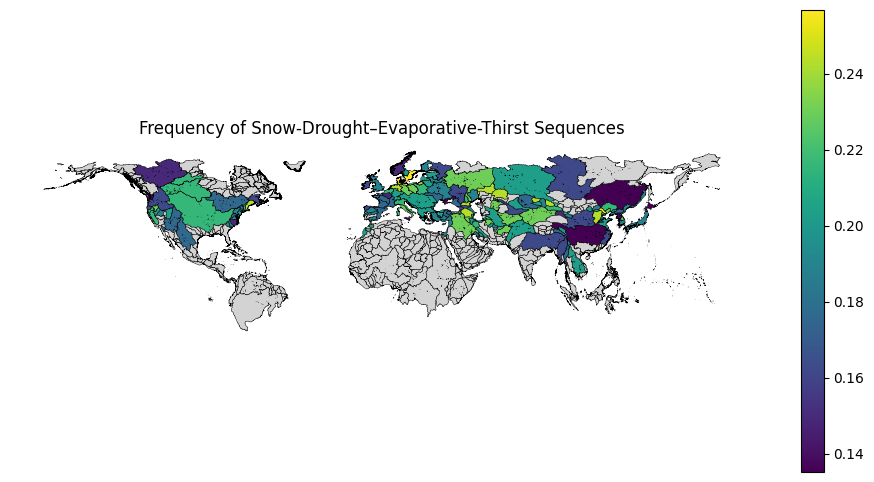

In [93]:
fig, ax = plt.subplots(figsize=(12,6))

basins_diss.plot(
    column="freq_compound",
    cmap="viridis",
    linewidth=0.3,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgray",
        "label": "No data"
    },
    ax=ax
)

ax.set_title("Frequency of Snow-Drought–Evaporative-Thirst Sequences")
ax.set_axis_off()

plt.show()

In [94]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

def plot_frequency_map(gdf, column, title, cmap="Reds"):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # bins in FRACTION units
    bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "label": "No data"
        },
        ax=ax
    )

    sm = cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        fraction=0.04,
        boundaries=bounds,
        ticks=bounds
    )

    # show percent labels
    cbar.set_ticklabels(
        ["0", "5", "10", "15", "20", "25"]
    )

    cbar.set_label(
        "Frequency (%)",
        fontsize=16
    )

    cbar.ax.tick_params(
        labelsize=16
    )

    ax.set_title(
        title,
        fontsize=20
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

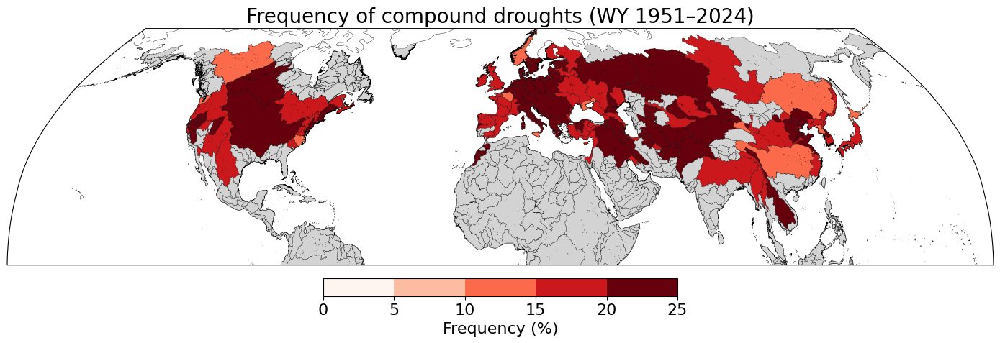

In [95]:
plot_frequency_map(
    basins_diss,
    column="freq_compound",
    title="Frequency of compound droughts (WY 1951–2024)"
)

In [96]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

def plot_frequency_map(gdf, column, title, cmap="Blues"):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # bins in FRACTION units
    bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "label": "No data"
        },
        ax=ax
    )

    sm = cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        fraction=0.04,
        boundaries=bounds,
        ticks=bounds
    )

    # show percent labels
    cbar.set_ticklabels(
        ["0", "5", "10", "15", "20", "25"]
    )

    cbar.set_label(
        "Frequency (%)",
        fontsize=16
    )

    cbar.ax.tick_params(
        labelsize=16
    )

    ax.set_title(
        title,
        fontsize=20
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

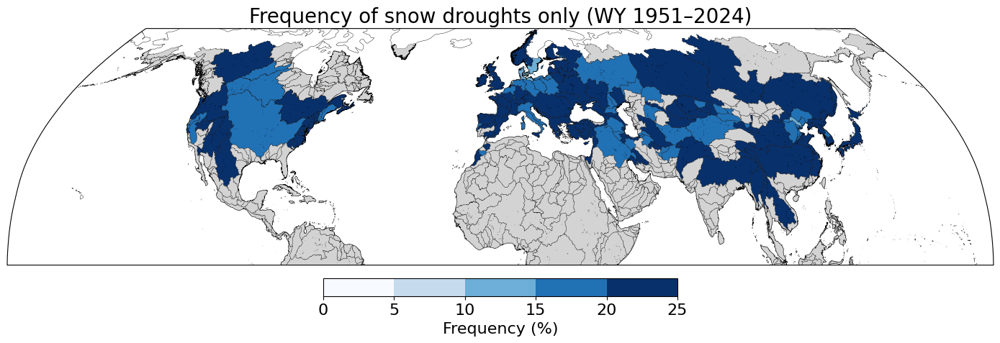

In [97]:
plot_frequency_map(
    basins_diss,
    column="freq_low_swe_only",
    title="Frequency of snow droughts only (WY 1951–2024)"
)

In [98]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

def plot_frequency_map(gdf, column, title, cmap="Oranges"):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # bins in FRACTION units
    bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "label": "No data"
        },
        ax=ax
    )

    sm = cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        fraction=0.04,
        boundaries=bounds,
        ticks=bounds
    )

    # show percent labels
    cbar.set_ticklabels(
        ["0", "5", "10", "15", "20", "25"]
    )

    cbar.set_label(
        "Frequency (%)",
        fontsize=16
    )

    cbar.ax.tick_params(
        labelsize=16
    )

    ax.set_title(
        title,
        fontsize=20
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

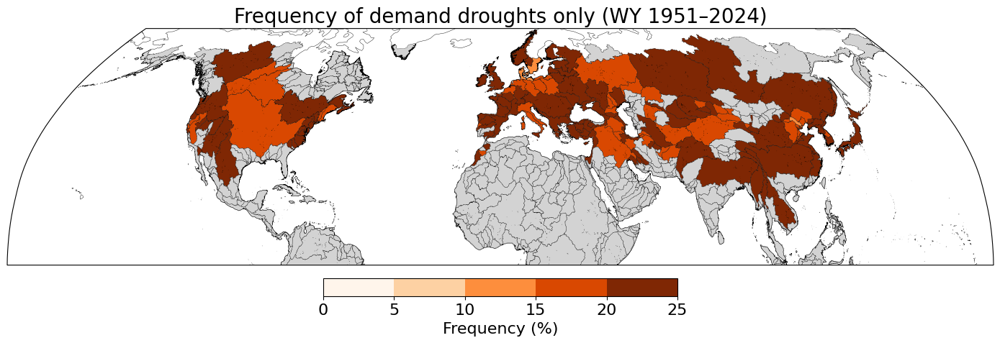

In [99]:
plot_frequency_map(
    basins_diss,
    column="freq_high_eto_only",
    title="Frequency of demand droughts only (WY 1951–2024)"
)

In [100]:
# ------------------------------------------------------------
# Expected frequencies under independence
# Keep these for descriptive comparisons
# ------------------------------------------------------------
expected = {
    "compound": 0.4 * 0.4,        # 0.16
    "snow":     0.4 * 0.6,        # 0.24
    "demand":   0.6 * 0.4,        # 0.24
    "normal":   0.6 * 0.6         # 0.36
}

# ------------------------------------------------------------
# Fisher's exact test
# Tests association between low winter SWE and
# subsequent high warm-season ETo
# ------------------------------------------------------------

fisher_pvals = []
odds_ratios = []

for _, row in freq_df.iterrows():

    n = row["n_years"]

    if n > 0:

        table = [
            [
                int(row["n_compound"]),
                int(row["n_low_swe_only"])
            ],
            [
                int(row["n_high_eto_only"]),
                int(row["n_normal"])
            ]
        ]

        odds_ratio, pval = fisher_exact(
            table,
            alternative="two-sided"
        )

        odds_ratios.append(
            odds_ratio
        )

        fisher_pvals.append(
            pval
        )

    else:

        odds_ratios.append(
            np.nan
        )

        fisher_pvals.append(
            np.nan
        )


freq_df["odds_ratio"] = odds_ratios
freq_df["p_fisher"] = fisher_pvals

# ------------------------------------------------------------
# Merge Fisher results into basin polygons
# ------------------------------------------------------------

fisher_cols = [
    "odds_ratio",
    "p_fisher"
]

basins_diss = basins_diss.drop(
    columns=[
        c for c in fisher_cols
        if c in basins_diss.columns
    ],
    errors="ignore"
)

basins_diss = basins_diss.merge(
    freq_df[
        ["MAIN_BAS"] + fisher_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Significance mask
# ------------------------------------------------------------

alpha = 0.05

basins_diss["sig_fisher"] = (
    basins_diss["p_fisher"] < alpha
)


# ------------------------------------------------------------
# Frequency anomalies: observed - expected
# These can remain exactly as before
# ------------------------------------------------------------

basins_diss["compound_anom"] = (
    basins_diss["freq_compound"]
    - expected["compound"]
)

basins_diss["snow_drought_anom"] = (
    basins_diss["freq_low_swe_only"]
    - expected["snow"]
)

basins_diss["demand_drought_anom"] = (
    basins_diss["freq_high_eto_only"]
    - expected["demand"]
)

basins_diss["non_drought_anom"] = (
    basins_diss["freq_normal"]
    - expected["normal"]
)


# ------------------------------------------------------------
# Percent difference from expected
# These can also remain
# ------------------------------------------------------------

basins_diss["compound_pct_diff"] = (
    basins_diss["compound_anom"]
    / expected["compound"]
) * 100

basins_diss["snow_drought_pct_diff"] = (
    basins_diss["snow_drought_anom"]
    / expected["snow"]
) * 100

basins_diss["demand_drought_pct_diff"] = (
    basins_diss["demand_drought_anom"]
    / expected["demand"]
) * 100

basins_diss["non_drought_pct_diff"] = (
    basins_diss["non_drought_anom"]
    / expected["normal"]
) * 100


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

n_total = basins_diss["p_fisher"].notna().sum()

n_sig = int(
    basins_diss["sig_fisher"].sum()
)

print(
    "Basins tested:",
    n_total
)

print(
    "Significant Fisher tests:",
    n_sig
)

print(
    "Percent significant:",
    100 * n_sig / n_total
)

print(
    "\nOdds ratio summary:"
)

print(
    basins_diss.loc[
        basins_diss["p_fisher"].notna(),
        "odds_ratio"
    ].describe()
)

# You now have 34 of 169 basins (20.1%) showing a statistically significant association between low winter SWE and subsequent high warm-season ETo using a two-sided Fisher test.
# The odds ratios are also informative:
# median OR = 1.55 → in the median basin, the odds of high ETo following a low-SWE winter are about 1.55× the odds following a non-low-SWE winter.
# 75th percentile = 2.78
# maximum = 6.90
# minimum = 0.42, so some basins show the opposite relationship.
# mean = 2.22, but I would emphasize the median because the distribution is right-skewed.

Basins tested: 169
Significant Fisher tests: 34
Percent significant: 20.118343195266274

Odds ratio summary:
count    169.000000
mean       2.024911
std        1.009185
min        0.600000
25%        1.214533
50%        1.933333
75%        2.448980
max        5.181818
Name: odds_ratio, dtype: float64


In [101]:
n_total = basins_diss["p_fisher"].notna().sum()

sig = (
    basins_diss["p_fisher"] < 0.05
)

n_sig_positive = int(
    (
        sig
        & (basins_diss["odds_ratio"] > 1)
    ).sum()
)

n_sig_negative = int(
    (
        sig
        & (basins_diss["odds_ratio"] < 1)
    ).sum()
)

summary_fisher = pd.DataFrame({
    "association": [
        "Positive (OR > 1)",
        "Negative (OR < 1)"
    ],
    "n_significant": [
        n_sig_positive,
        n_sig_negative
    ],
    "pct_of_tested_basins": [
        100 * n_sig_positive / n_total,
        100 * n_sig_negative / n_total
    ]
})

print(summary_fisher)

         association  n_significant  pct_of_tested_basins
0  Positive (OR > 1)             34             20.118343
1  Negative (OR < 1)              0              0.000000


In [102]:
check = pd.DataFrame({
    "cascading": n_compound.values,
    "snow_only": n_low.values,
    "demand_only": n_high.values,
    "normal": n_normal.values,

    "low_swe_total": (
        (low_swe & valid_wy)
        .sum("wy")
        .values
    ),

    "high_eto_total": (
        (high_eto & valid_wy)
        .sum("wy")
        .values
    )
})

check_valid = check.loc[
    n_years.values > 0
]

print(
    check_valid.describe()
)

# Across all 169 valid basins:
# every basin has exactly 22 low-SWE winters,
# every basin has exactly 22 high-ETo warm seasons,
# only the amount of overlap between those two sets varies,
# cascading events range from 4 to 13 years.

        cascading   snow_only  demand_only      normal  low_swe_total  \
count  169.000000  169.000000   169.000000  169.000000          169.0   
mean    14.656805   15.343195    15.343195   28.656805           30.0   
std      2.121453    2.121453     2.121453    2.121453            0.0   
min     10.000000   11.000000    11.000000   24.000000           30.0   
25%     13.000000   14.000000    14.000000   27.000000           30.0   
50%     15.000000   15.000000    15.000000   29.000000           30.0   
75%     16.000000   17.000000    17.000000   30.000000           30.0   
max     19.000000   20.000000    20.000000   33.000000           30.0   

       high_eto_total  
count           169.0  
mean             30.0  
std               0.0  
min              30.0  
25%              30.0  
50%              30.0  
75%              30.0  
max              30.0  


In [103]:
# ------------------------------------------------------------
# Discrete coolwarm colormap with white center bin (-10 to 10)
# ------------------------------------------------------------

bounds = np.array(
    [-60, -50, -40, -30, -20, -10, 10, 20, 30, 40, 50, 60]
)

base = plt.get_cmap("coolwarm")

cmap_colors = base(
    np.linspace(
        0,
        1,
        len(bounds) - 1
    )
)

# bin index corresponding to -10 to +10
center_idx = list(
    bounds[:-1]
).index(-10)

cmap_colors[center_idx] = [
    1,
    1,
    1,
    1
]

disc_cmap = colors.ListedColormap(
    cmap_colors
)

disc_norm = colors.BoundaryNorm(
    boundaries=bounds,
    ncolors=disc_cmap.N,
    clip=True
)


# ------------------------------------------------------------
# Plot function
# ------------------------------------------------------------

def plot_with_hatching(
    gdf,
    column,
    title,
    hatch_significant=True
):

    fig = plt.figure(
        figsize=(14, 7)
    )

    ax = plt.axes(
        projection=ccrs.Robinson()
    )

    # Base map
    gdf.plot(
        column=column,
        cmap=disc_cmap,
        norm=disc_norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray"
        },
        ax=ax
    )

    # Hatching for significant positive Fisher association
    if hatch_significant:

        sig = (
            (gdf["p_fisher"] < 0.05)
            & (gdf["odds_ratio"] > 1)
        )

        gdf[sig].plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    # Colorbar
    sm = cm.ScalarMappable(
        norm=disc_norm,
        cmap=disc_cmap
    )

    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=np.arange(
            -60,
            61,
            20
        ),
        pad=0.03,
        fraction=0.04,
        spacing="proportional"
    )

    cbar.set_label(
        "% difference from expected frequency",
        fontsize=14
    )

    cbar.ax.tick_params(
        labelsize=14
    )

    # Fisher significance legend
    if hatch_significant:

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    ax.set_title(
        title,
        fontsize=18
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

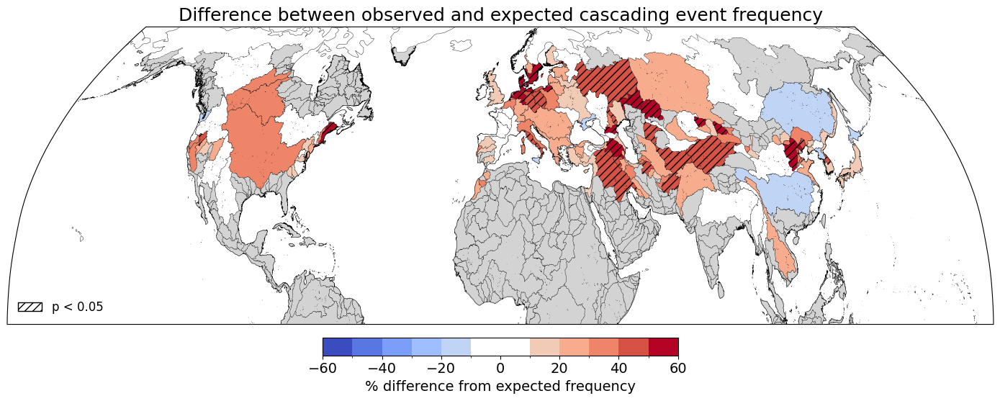

In [104]:
plot_with_hatching(
    basins_diss,
    "compound_pct_diff",
    "Difference between observed and expected cascading event frequency",
    hatch_significant=True
)

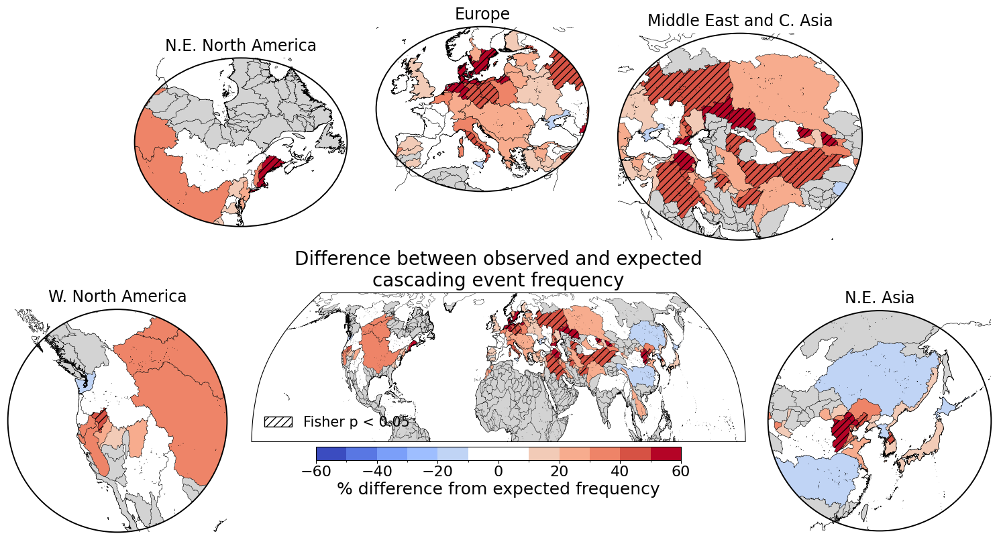

In [105]:
# ------------------------------------------------------------
# Fisher significance
# ------------------------------------------------------------
basins_diss["sig_fisher"] = (
    basins_diss["p_fisher"] < 0.05
)


# ------------------------------------------------------------
# Discrete coolwarm colormap with white center bin (-10 to 10)
# ------------------------------------------------------------
bounds = np.array(
    [-60, -50, -40, -30, -20, -10, 10, 20, 30, 40, 50, 60]
)

base = plt.get_cmap("coolwarm")

cmap_colors = base(
    np.linspace(0, 1, len(bounds) - 1)
)

# bin index corresponding to -10 to +10
center_idx = list(
    bounds[:-1]
).index(-10)

cmap_colors[center_idx] = [
    1, 1, 1, 1
]

disc_cmap = colors.ListedColormap(
    cmap_colors
)

disc_norm = colors.BoundaryNorm(
    boundaries=bounds,
    ncolors=disc_cmap.N,
    clip=True
)


# ------------------------------------------------------------
# Plot function
# ------------------------------------------------------------
def plot_with_hatching(gdf, column, sig_col, title):

    fig = plt.figure(figsize=(16, 11))

    # ============================================================
    # Main map — smaller and positioned at the bottom center
    # ============================================================
    ax = fig.add_axes(
        [0.27, 0.30, 0.46, 0.30],
        projection=ccrs.Robinson()
    )

    gdf.plot(
        column=column,
        cmap=disc_cmap,
        norm=disc_norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    gdf[gdf[sig_col].fillna(False)].plot(
        ax=ax,
        facecolor="none",
        edgecolor="black",
        hatch="///",
        linewidth=0,
        transform=ccrs.PlateCarree()
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(linewidth=0.3)

    ax.set_title(
        title,
        fontsize=20,
        pad=7
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # ============================================================
    # Significance legend
    # ============================================================
    hatch_patch = mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        hatch="///",
        label="Fisher p < 0.05"
    )

    ax.legend(
        handles=[hatch_patch],
        loc="lower left",
        frameon=False,
        fontsize=15
    )

    # ============================================================
    # Colorbar — close to the main map
    # ============================================================
    sm = cm.ScalarMappable(
        norm=disc_norm,
        cmap=disc_cmap
    )
    sm.set_array([])

    # Allow Cartopy to calculate the map's final position
    fig.canvas.draw()

    map_position = ax.get_position()

    colorbar_width = 0.34
    colorbar_height = 0.018

    cax = fig.add_axes([
        0.5 - colorbar_width / 2,
        map_position.y0 - 0.025,
        colorbar_width,
        colorbar_height
    ])

    cbar = plt.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=np.arange(-60, 61, 20),
        spacing="proportional"
    )

    cbar.set_label(
        "% difference from expected frequency",
        fontsize=18,
        labelpad=3
    )

    cbar.ax.tick_params(
        labelsize=16,
        pad=2
    )

    # ============================================================
    # Circular inset helper
    # ============================================================
    def add_inset(
        position,
        extent,
        inset_title,
        title_fontsize=17
    ):

        inset = fig.add_axes(
            position,
            projection=ccrs.PlateCarree()
        )

        gdf.plot(
            column=column,
            cmap=disc_cmap,
            norm=disc_norm,
            linewidth=0.3,
            edgecolor="black",
            transform=ccrs.PlateCarree(),
            missing_kwds={"color": "lightgray"},
            ax=inset
        )

        gdf[gdf[sig_col].fillna(False)].plot(
            ax=inset,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

        inset.set_extent(
            extent,
            crs=ccrs.PlateCarree()
        )

        inset.coastlines(linewidth=0.45)

        # --------------------------------------------------------
        # Circular clipping
        # --------------------------------------------------------
        radius = 0.495

        clip_circle = mpatches.Circle(
            (0.5, 0.5),
            radius,
            transform=inset.transAxes
        )

        for artist in inset.collections:
            artist.set_clip_path(
                clip_circle
            )

        # Hide the standard rectangular border
        if "geo" in inset.spines:
            inset.spines["geo"].set_visible(
                False
            )

        # --------------------------------------------------------
        # White masks outside the circle
        # --------------------------------------------------------

        # Left mask
        inset.add_patch(
            mpatches.Rectangle(
                (0, 0),
                0.5 - radius,
                1,
                transform=inset.transAxes,
                facecolor="white",
                edgecolor="none",
                zorder=90
            )
        )

        # Right mask
        inset.add_patch(
            mpatches.Rectangle(
                (0.5 + radius, 0),
                0.5 - radius,
                1,
                transform=inset.transAxes,
                facecolor="white",
                edgecolor="none",
                zorder=90
            )
        )

        # Bottom mask
        inset.add_patch(
            mpatches.Rectangle(
                (0, 0),
                1,
                0.5 - radius,
                transform=inset.transAxes,
                facecolor="white",
                edgecolor="none",
                zorder=90
            )
        )

        # Top mask
        inset.add_patch(
            mpatches.Rectangle(
                (0, 0.5 + radius),
                1,
                0.5 - radius,
                transform=inset.transAxes,
                facecolor="white",
                edgecolor="none",
                zorder=90
            )
        )

        # --------------------------------------------------------
        # Circle outline
        # --------------------------------------------------------
        circle_outline = mpatches.Circle(
            (0.5, 0.5),
            radius,
            transform=inset.transAxes,
            facecolor="none",
            edgecolor="black",
            linewidth=1.4,
            zorder=100
        )

        inset.add_patch(
            circle_outline
        )

        inset.set_xticks([])
        inset.set_yticks([])

        inset.set_title(
            inset_title,
            fontsize=title_fontsize,
            pad=7
        )

        return inset

    # ============================================================
    # Five evenly spaced circles around the main map
    # ============================================================

    # Left
    add_inset(
        [0.040, 0.225, 0.21, 0.305],
        [-138, -95, 27, 58],
        "W. North America"
    )

    # Upper left
    add_inset(
        [0.160, 0.610, 0.20, 0.290],
        [-100, -52, 35, 62],
        "N.E. North America"
    )

    # Upper center
    add_inset(
        [0.385, 0.655, 0.20, 0.290],
        [-15, 45, 32, 65],
        "Europe"
    )

    # Upper right
    add_inset(
        [0.610, 0.595, 0.23, 0.335],
        [25, 100, 23, 68],
        "Middle East and C. Asia"
    )

    # Right
    add_inset(
        [0.750, 0.225, 0.21, 0.305],
        [95, 155, 20, 62],
        "N.E. Asia"
    )

    # ============================================================
    # Save
    # ============================================================
    plt.savefig(
        "Fig_S15.png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.05
    )

    plt.show()


plot_with_hatching(
    basins_diss,
    column="compound_pct_diff",
    sig_col="sig_fisher",
    title=(
        "Difference between observed and expected\n"
        "cascading event frequency"
    )
)

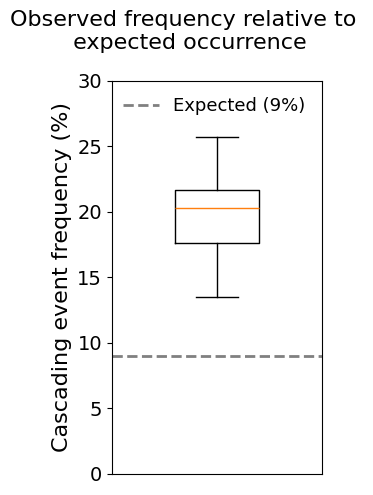

In [106]:
plt.figure(figsize=(3, 5))

vals = (
    freq_df["freq_compound"]
    .dropna()
    * 100
)

plt.boxplot(
    vals,
    widths=0.4
)

plt.axhline(
    y=9,
    color="gray",
    linestyle="--",
    linewidth=2,
    label="Expected (9%)"
)

plt.ylabel(
    "Cascading event frequency (%)",
    fontsize=16
)

# Set y axis
plt.ylim(0, 30)

plt.yticks(
    [0, 5, 10, 15, 20, 25, 30],
    fontsize=14
)

plt.xticks([])

plt.legend(
    frameon=False,
    fontsize=13
)

plt.suptitle(
    "Observed frequency relative to \n expected occurrence",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [107]:
median_freq = freq_df["freq_compound"].median()
print(median_freq)

0.20270270270270271


In [108]:
mean_freq = freq_df["freq_compound"].mean()
print(mean_freq)

0.19806492883415958


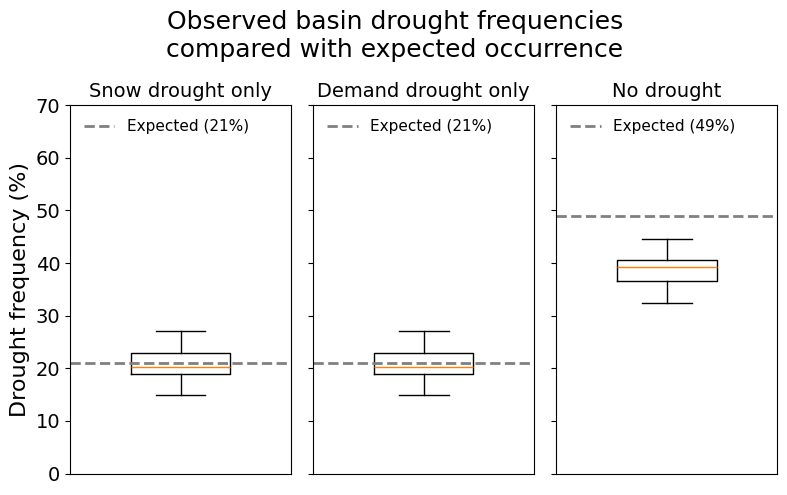

In [109]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(8, 5),
    sharey=True
)

vars_to_plot = [
    ("freq_low_swe_only", "Snow drought only", 21),
    ("freq_high_eto_only", "Demand drought only", 21),
    ("freq_normal", "No drought", 49)
]

for i, (ax, (col, title, expected)) in enumerate(
    zip(axes, vars_to_plot)
):

    vals = (
        freq_df[col]
        .dropna()
        * 100
    )

    ax.boxplot(
        vals,
        widths=0.45
    )

    ax.axhline(
        y=expected,
        color="gray",
        linestyle="--",
        linewidth=2,
        label=f"Expected ({expected}%)"
    )

    ax.set_title(
        title,
        fontsize=14
    )

    ax.set_xticks([])

    if i == 0:
        ax.set_ylabel(
            "Drought frequency (%)",
            fontsize=16
        )

    ax.tick_params(
        axis="y",
        labelsize=14
    )

    ax.legend(
        frameon=False,
        fontsize=11,
        loc="upper left"
    )

# shared y-axis
axes[0].set_ylim(0, 70)

axes[0].set_yticks(
    [0, 10, 20, 30, 40, 50, 60, 70]
)

plt.suptitle(
    "Observed basin drought frequencies\ncompared with expected occurrence",
    fontsize=18
)

plt.tight_layout()

plt.show()

In [110]:
compound.sum("region")
(compound.sum("wy") > 0).sum()

<xarray.DataArray ()> Size: 8B
array(169)

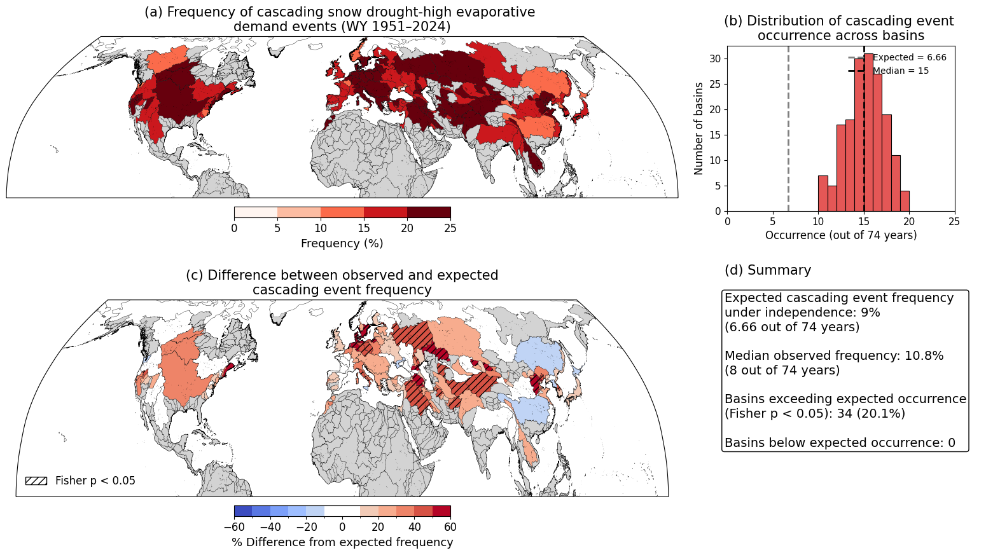

In [111]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import numpy as np

fig = plt.figure(figsize=(16, 10))

# -----------------------------
# Layout
# -----------------------------
ax_a = fig.add_axes([0.03, 0.57, 0.66, 0.34], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.73, 0.57, 0.24, 0.28])

ax_c = fig.add_axes([0.03, 0.10, 0.66, 0.34], projection=ccrs.Robinson())
ax_d = fig.add_axes([0.73, 0.28, 0.27, 0.22])
ax_d.axis("off")

# ============================================================
# (a) Frequency map
# ============================================================
freq_bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])
freq_cmap = "Reds"

freq_norm = colors.BoundaryNorm(
    freq_bounds,
    ncolors=plt.get_cmap(freq_cmap).N,
    clip=True
)

basins_diss.plot(
    column="freq_compound",
    cmap=freq_cmap,
    norm=freq_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={"color": "lightgray", "label": "No data"},
    ax=ax_a
)

sm_a = cm.ScalarMappable(norm=freq_norm, cmap=freq_cmap)
sm_a.set_array([])

cbar_a = plt.colorbar(
    sm_a,
    ax=ax_a,
    orientation="horizontal",
    pad=0.04,
    fraction=0.05,
    boundaries=freq_bounds,
    ticks=freq_bounds
)

cbar_a.set_ticklabels(["0", "5", "10", "15", "20", "25"])
cbar_a.set_label("Frequency (%)", fontsize=13)
cbar_a.ax.tick_params(labelsize=12)

ax_a.set_title("(a) Frequency of cascading snow drought-high evaporative \ndemand events (WY 1951–2024)", fontsize=15)
ax_a.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_a.coastlines(linewidth=0.3)

# ============================================================
# (b) Histogram
# ============================================================
expected = 74 * 0.3 * 0.3
median = good_df["compound"].median()

ax_b.hist(
    good_df["compound"],
    bins=np.arange(good_df["compound"].min(), good_df["compound"].max() + 2),
    color="#E45756",
    edgecolor="black",
    linewidth=0.8
)

ax_b.axvline(
    expected,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected:.2f}"
)

ax_b.axvline(
    median,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median:.0f}"
)

ax_b.set_xlim(0, 25)
ax_b.set_xlabel("Occurrence (out of 74 years)", fontsize=12)
ax_b.set_ylabel("Number of basins", fontsize=12)
ax_b.set_title("(b) Distribution of cascading event \noccurrence across basins", fontsize=15)

ax_b.legend(
    loc="upper right",
    frameon=False,
    fontsize=10,
    handlelength=2
)

ax_b.tick_params(axis="both", labelsize=11)

# ============================================================
# (c) Difference map with hatching
# ============================================================
diff_bounds = np.array([-60, -50, -40, -30, -20, -10, 10, 20, 30, 40, 50, 60])

base = plt.get_cmap("coolwarm")
cmap_colors = base(np.linspace(0, 1, len(diff_bounds) - 1))

center_idx = list(diff_bounds[:-1]).index(-10)
cmap_colors[center_idx] = [1, 1, 1, 1]

disc_cmap = colors.ListedColormap(cmap_colors)

disc_norm = colors.BoundaryNorm(
    boundaries=diff_bounds,
    ncolors=disc_cmap.N,
    clip=True
)

basins_diss.plot(
    column="compound_pct_diff",
    cmap=disc_cmap,
    norm=disc_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={"color": "lightgray"},
    ax=ax_c
)

basins_diss[
    basins_diss["sig_fisher"].fillna(False)
].plot(
    ax=ax_c,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm_c = cm.ScalarMappable(norm=disc_norm, cmap=disc_cmap)
sm_c.set_array([])

cbar_c = plt.colorbar(
    sm_c,
    ax=ax_c,
    orientation="horizontal",
    boundaries=diff_bounds,
    ticks=np.arange(-60, 61, 20),
    pad=0.04,
    fraction=0.05,
    spacing="proportional"
)

cbar_c.set_label("% Difference from expected frequency", fontsize=13)
cbar_c.ax.tick_params(labelsize=12)

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="Fisher p < 0.05"
)

ax_c.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax_c.set_title("(c) Difference between observed and expected\ncascading event frequency", fontsize=15)
ax_c.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_c.coastlines(linewidth=0.3)

# ============================================================
# (d) Summary box
# ============================================================
summary_text = (
    "Expected cascading event frequency\n"
    "under independence: 9%\n"
    "(6.66 out of 74 years)\n\n"
    "Median observed frequency: 10.8%\n"
    "(8 out of 74 years)\n\n"
    "Basins exceeding expected occurrence\n"
    "(Fisher p < 0.05): 34 (20.1%)\n\n"
    "Basins below expected occurrence: 0"
)



ax_d.text(
    0.02,
    0.98,
    "(d) Summary",
    fontsize=15,
    va="top"
)

ax_d.text(
    0.02,
    0.78,
    summary_text,
    fontsize=14,
    va="top",
    linespacing=1.25,
    bbox=dict(
        boxstyle="round,pad=0.2",
        facecolor="white",
        edgecolor="black",
        linewidth=1
    )
)
pos = ax_b.get_position()

scale = 0.93

new_w = pos.width * scale
new_h = pos.height * scale

new_x = pos.x0 + (pos.width - new_w)/2
new_y = pos.y0 + (pos.height - new_h)/2

ax_b.set_position([
    new_x,
    new_y,
    new_w,
    new_h
])

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

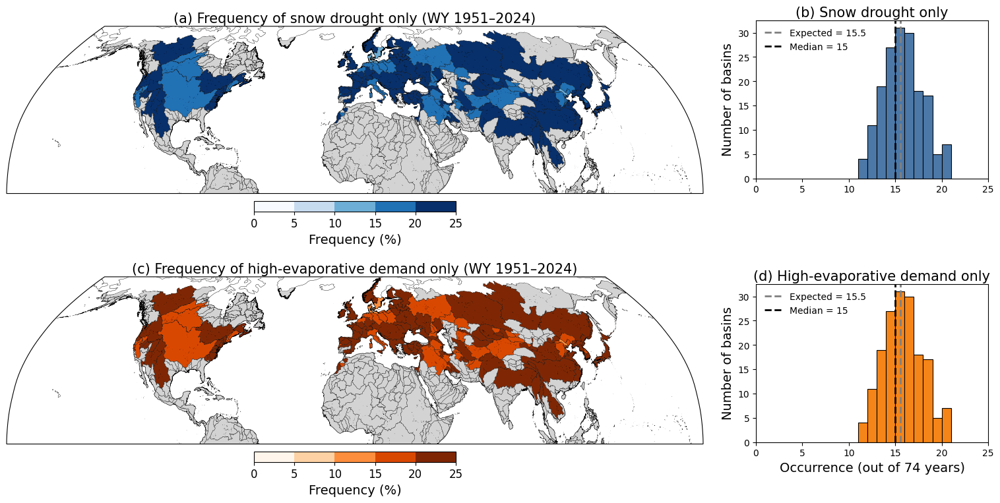

In [112]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

fig = plt.figure(figsize=(16, 10))

# -----------------------------
# Layout
# -----------------------------
ax_a = fig.add_axes([0.03, 0.57, 0.66, 0.34], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.74, 0.62, 0.22, 0.24])

ax_c = fig.add_axes([0.03, 0.19, 0.66, 0.34], projection=ccrs.Robinson())
ax_d = fig.add_axes([0.74, 0.22, 0.22, 0.24])

# -----------------------------
# Shared frequency settings
# -----------------------------
bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

def add_frequency_map(ax, gdf, column, title, cmap):
    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "No data"},
        ax=ax
    )

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.035,
        fraction=0.045,
        boundaries=bounds,
        ticks=bounds
    )

    cbar.set_ticklabels(["0", "5", "10", "15", "20", "25"])
    cbar.set_label("Frequency (%)", fontsize=14)
    cbar.ax.tick_params(labelsize=12)

    ax.set_title(title, fontsize=15, pad=4)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

# ============================================================
# (a) Snow drought frequency map
# ============================================================
add_frequency_map(
    ax_a,
    basins_diss,
    column="freq_low_swe_only",
    title="(a) Frequency of snow drought only (WY 1951–2024)",
    cmap="Blues"
)

# ============================================================
# (b) Snow drought histogram
# ============================================================
expected_snow = 74 * 0.3 * 0.7
median_snow = good_df["low_swe_only"].median()

ax_b.hist(
    good_df["low_swe_only"],
    bins=np.arange(good_df["low_swe_only"].min(), good_df["low_swe_only"].max() + 2),
    color="#4C78A8",
    edgecolor="black",
    linewidth=0.8
)

ax_b.axvline(
    expected_snow,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected_snow:.1f}"
)

ax_b.axvline(
    median_snow,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_snow:.0f}"
)

ax_b.set_xlim(0, 25)
ax_b.set_title("(b) Snow drought only", fontsize=15, pad=4)
ax_b.set_ylabel("Number of basins", fontsize=14)
ax_b.tick_params(axis="both", labelsize=10)
ax_b.legend(loc="upper left", frameon=False, fontsize=10, handlelength=2)

# ============================================================
# (c) Demand drought frequency map
# ============================================================
add_frequency_map(
    ax_c,
    basins_diss,
    column="freq_high_eto_only",
    title="(c) Frequency of high-evaporative demand only (WY 1951–2024)",
    cmap="Oranges"
)

# ============================================================
# (d) Demand drought histogram
# ============================================================
expected_demand = 74 * 0.7 * 0.3
median_demand = good_df["high_eto_only"].median()

ax_d.hist(
    good_df["high_eto_only"],
    bins=np.arange(good_df["high_eto_only"].min(), good_df["high_eto_only"].max() + 2),
    color="#F58518",
    edgecolor="black",
    linewidth=0.8
)

ax_d.axvline(
    expected_demand,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected_demand:.1f}"
)

ax_d.axvline(
    median_demand,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_demand:.0f}"
)

ax_d.set_xlim(0, 25)
ax_d.set_title("(d) High-evaporative demand only", fontsize=15, pad=4)
ax_d.set_xlabel("Occurrence (out of 74 years)", fontsize=14)
ax_d.set_ylabel("Number of basins", fontsize=14)
ax_d.tick_params(axis="both", labelsize=10)
ax_d.legend(loc="upper left", frameon=False, fontsize=10, handlelength=2)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_S3.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [113]:
expected = {
    "compound": 0.4 * 0.4,        # low SWE AND high ETo = 0.16
    "snow":     0.4 * 0.6,        # low SWE only = 0.24
    "demand":   0.6 * 0.4,        # high ETo only = 0.24
    "normal":   0.6 * 0.6         # neither = 0.36
}

In [114]:
valid_wy.any("wy")

<xarray.DataArray (region: 602)> Size: 602B
array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False,  True,  True, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True, False, False, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False, False,  True,  True, False,  True,  True, False,  True,
       False,  True,  True,  True,  True, False, False, False, False,
...
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True, False,
       False, False,  True,  True,  True, False,  True, False,  True,
        True,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False,  True,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False, False, False, False, False,  True,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False,  True,  True, False,  True,  True,
       False, False, False, False, False, False, False, False, False,
       False, False,  True, False, False, False, False, False])
Coordinates:
  * region   (region) int64 5kB 0 1 2 3 4 5 6 7 ... 595 596 597 598 599 600 601

In [115]:
# Basins with at least one valid GRACE water year
analysis_mask = valid_wy.any("wy")

print("Total regions:", analysis_mask.size)        # 602
print("Selected regions:", int(analysis_mask.sum()))  # should be 169

# Positions of the 174 selected basins
analysis_pos = np.flatnonzero(analysis_mask.values)

# Subset drought-category arrays
compound_169 = compound.isel(region=analysis_pos)
snow_169 = low_swe_only.isel(region=analysis_pos)
demand_169 = high_eto_only.isel(region=analysis_pos)
normal_169 = normal.isel(region=analysis_pos)

print(compound_169.sizes["region"])  # 174

Total regions: 602
Selected regions: 169
169


In [116]:
basins_diss_169 = basins_diss.iloc[analysis_pos].copy()

print(len(basins_diss_169))  

169


In [117]:
selected_ids = basins_diss_169["MAIN_BAS"].to_numpy()

compound_169 = compound_169.assign_coords(region=selected_ids)
snow_169 = snow_169.assign_coords(region=selected_ids)
demand_169 = demand_169.assign_coords(region=selected_ids)
normal_169 = normal_169.assign_coords(region=selected_ids)

In [118]:
print(compound_169.sizes["region"])
print(snow_169.sizes["region"])
print(demand_169.sizes["region"])
print(normal_169.sizes["region"])

169
169
169
169


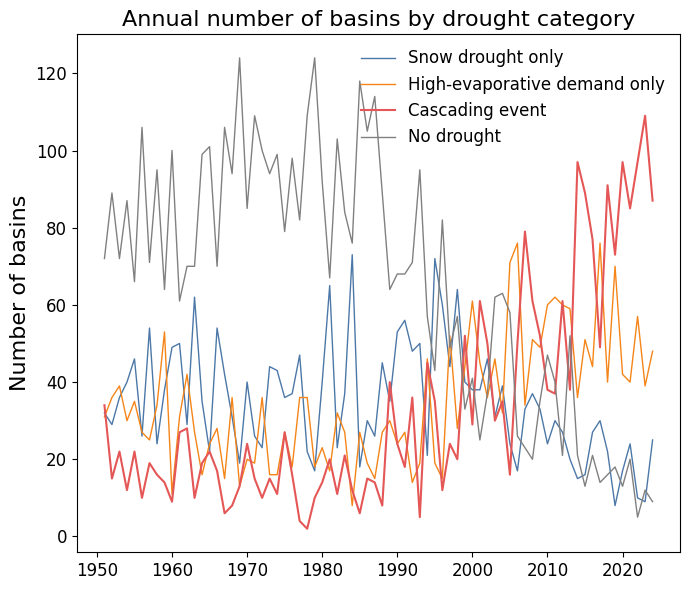

In [119]:
compound_ts  = compound_169.sum("region")
snow_ts      = snow_169.sum("region")
demand_ts    = demand_169.sum("region")
nodrought_ts = normal_169.sum("region")

plt.figure(figsize=(7, 6))

plt.plot(
    compound_169.wy,
    snow_ts,
    color="#4C78A8",
    linewidth=1,
    label="Snow drought only"
)

plt.plot(
    compound_169.wy,
    demand_ts,
    color="#F58518",
    linewidth=1,
    label="High-evaporative demand only"
)

plt.plot(
    compound_169.wy,
    compound_ts,
    color="#E45756",
    linewidth=1.5,
    label="Cascading event"
)

plt.plot(
    compound_169.wy,
    nodrought_ts,
    color="0.5",
    linewidth=1,
    label="No drought"
)

plt.ylabel("Number of basins", fontsize=16)
plt.title("Annual number of basins by drought category", fontsize=16)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(
    frameon=False,
    fontsize=12,
    ncol=1
)

plt.tight_layout()
plt.show()

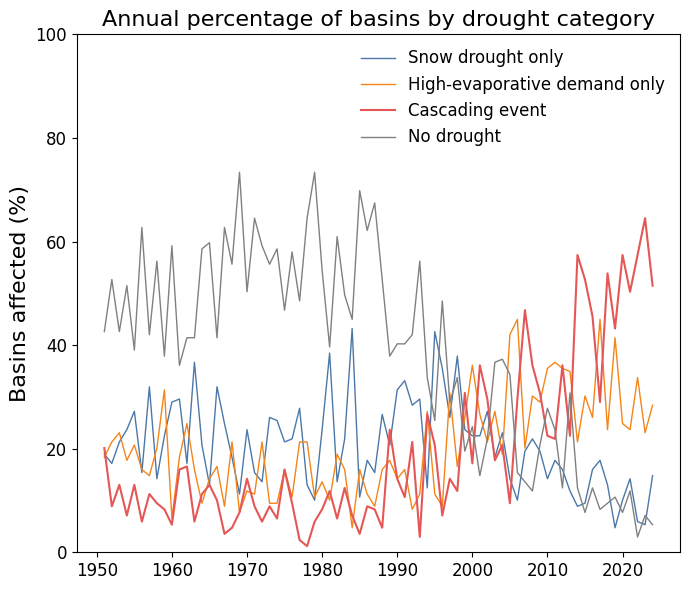

In [120]:
# Number of basins in the 169-basin subset
n_basins = compound_169.sizes["region"]

# Percentage of the 169 basins in each drought category
compound_pct = compound_169.sum("region") / n_basins * 100
snow_pct     = snow_169.sum("region") / n_basins * 100
demand_pct   = demand_169.sum("region") / n_basins * 100
normal_pct   = normal_169.sum("region") / n_basins * 100

plt.figure(figsize=(7, 6))

plt.plot(
    compound_169.wy,
    snow_pct,
    label="Snow drought only",
    color="#4C78A8",
    linewidth=1
)

plt.plot(
    compound_169.wy,
    demand_pct,
    label="High-evaporative demand only",
    color="#F58518",
    linewidth=1
)

plt.plot(
    compound_169.wy,
    compound_pct,
    label="Cascading event",
    color="#E45756",
    linewidth=1.5
)

plt.plot(
    compound_169.wy,
    normal_pct,
    label="No drought",
    color="0.5",
    linewidth=1
)

plt.ylabel("Basins affected (%)", fontsize=16)
plt.title("Annual percentage of basins by drought category", fontsize=16)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(0, 100)

plt.legend(
    frameon=False,
    fontsize=12,
    ncol=1
)

plt.tight_layout()
plt.show()

In [121]:
WINDOW = 5

rolling_compound = compound_ts.rolling(wy=WINDOW, center=True).mean() #smoothed time series of compound drought frequency
rolling_snow     = snow_ts.rolling(wy=WINDOW, center=True).mean()
rolling_demand   = demand_ts.rolling(wy=WINDOW, center=True).mean()
rolling_normal   = nodrought_ts.rolling(wy=WINDOW, center=True).mean()

# 5-year centered rolling mean of the annual number of basins in each drought category

In [122]:
print("Minimum number of basins:", compound_ts.min().item())
print(
    "Year of minimum:",
    compound_169.wy[compound_ts.argmin()].item()
)

print("Maximum number of basins:", compound_ts.max().item())
print(
    "Year of maximum:",
    compound_169.wy[compound_ts.argmax()].item()
)

Minimum number of basins: 2
Year of minimum: 1978
Maximum number of basins: 109
Year of maximum: 2023


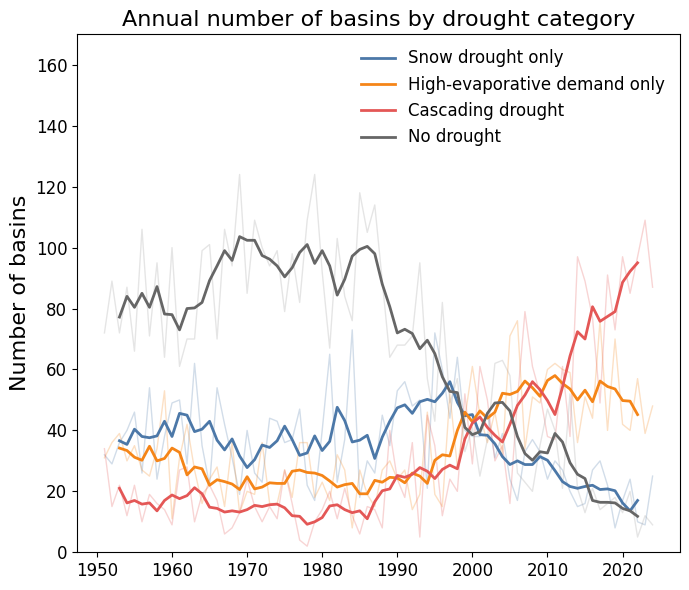

In [123]:
plt.figure(figsize=(7, 6))

# ------------------------------------------------------------
# Annual basin counts
# Thin transparent lines show year-to-year variability
# ------------------------------------------------------------
plt.plot(
    compound_169.wy,
    snow_ts,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    demand_ts,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    compound_ts,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    nodrought_ts,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# ------------------------------------------------------------
# 5-year centered rolling mean of annual basin counts
# ------------------------------------------------------------
plt.plot(
    rolling_snow.wy,
    rolling_snow,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand.wy,
    rolling_demand,
    color="#F58518",
    linewidth=2,
    label="High-evaporative demand only"
)

plt.plot(
    rolling_compound.wy,
    rolling_compound,
    color="#E45756",
    linewidth=2,
    label="Cascading drought"
)

plt.plot(
    rolling_normal.wy,
    rolling_normal,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel("Number of basins", fontsize=16)

plt.title(
    "Annual number of basins by drought category",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.ylim(0, 170)

plt.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [124]:
from scipy.stats import theilslopes, kendalltau
import numpy as np

# ------------------------------------------------------------
# Annual cascading-drought basin-count series
# ------------------------------------------------------------
x = compound_ts.wy.values
y = compound_ts.values

# Number of basins in the analysis
n_basins = compound_169.sizes["region"]   # 169

# ------------------------------------------------------------
# Sen's slope and 95% confidence interval
# Units here: basins per year
# ------------------------------------------------------------
sen_slope, intercept, lower, upper = theilslopes(
    y,
    x,
    alpha=0.95
)

# ------------------------------------------------------------
# Mann-Kendall trend significance
# Kendall tau between time and annual basin count
# ------------------------------------------------------------
tau, p = kendalltau(x, y)

# ------------------------------------------------------------
# Convert slope from basins/year to
# percentage of the 169 basins per decade
# ------------------------------------------------------------
trend_decade = sen_slope * 10 / n_basins * 100
lower_decade = lower * 10 / n_basins * 100
upper_decade = upper * 10 / n_basins * 100

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------
print(
    "Sen slope:",
    round(trend_decade, 2),
    "% of basins per decade"
)

print(
    "95% CI:",
    round(lower_decade, 2),
    "to",
    round(upper_decade, 2),
    "% of basins per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.0001" if p < 0.0001 else round(p, 4)
)

Sen slope: 4.93 % of basins per decade
95% CI: 3.36 to 6.43 % of basins per decade
Kendall tau: 0.506
p-value: <0.0001


In [125]:
WINDOW = 5
# 5-year centered rolling mean of the annual percentage of basins
# in each drought category
rolling_compound = compound_pct.rolling(wy=WINDOW, center=True).mean() #smoothed time series of compound drought frequency
rolling_snow     = snow_pct.rolling(wy=WINDOW, center=True).mean()
rolling_demand   = demand_pct.rolling(wy=WINDOW, center=True).mean()
rolling_normal   = normal_pct.rolling(wy=WINDOW, center=True).mean()

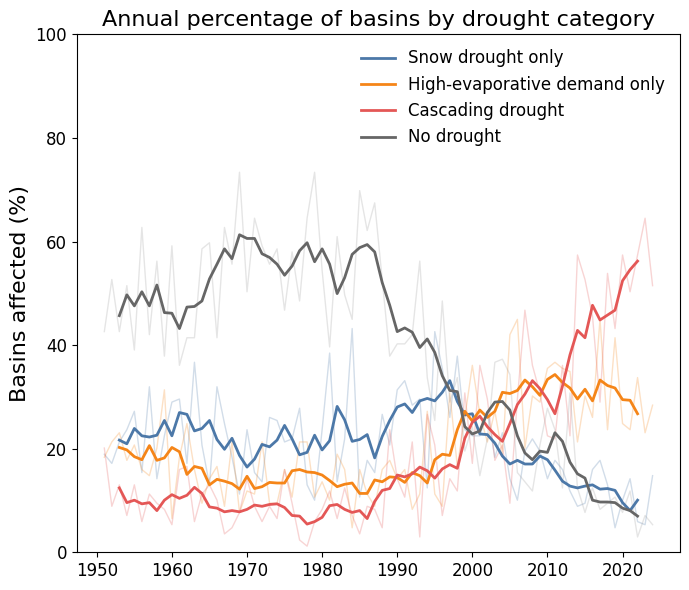

In [126]:
plt.figure(figsize=(7, 6))

# ------------------------------------------------------------
# Annual percentage of the 169 basins in each drought category
# Thin transparent lines show year-to-year variability
# ------------------------------------------------------------
plt.plot(
    compound_169.wy,
    snow_pct,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    demand_pct,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    compound_pct,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    normal_pct,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# ------------------------------------------------------------
# 5-year centered rolling mean of annual percentages
# ------------------------------------------------------------
plt.plot(
    rolling_snow.wy,
    rolling_snow,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand.wy,
    rolling_demand,
    color="#F58518",
    linewidth=2,
    label="High-evaporative demand only"
)

plt.plot(
    rolling_compound.wy,
    rolling_compound,
    color="#E45756",
    linewidth=2,
    label="Cascading drought"
)

plt.plot(
    rolling_normal.wy,
    rolling_normal,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel("Basins affected (%)", fontsize=16)

plt.title(
    "Annual percentage of basins by drought category",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(0, 100)

plt.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [127]:
# Annual percentage series
x = compound_pct.wy.values
y = compound_pct.values

# Sen's slope
# Units: percentage points per year
sen_slope, intercept, lower, upper = theilslopes(
    y,
    x,
    alpha=0.95
)

# Kendall tau trend significance
tau, p = kendalltau(
    x,
    y
)

# Convert Sen's slope to percentage points per decade
trend_decade = sen_slope * 10
lower_decade = lower * 10
upper_decade = upper * 10

print(
    "Sen slope:",
    round(trend_decade, 2),
    "percentage points per decade"
)

print(
    "95% CI:",
    round(lower_decade, 2),
    "to",
    round(upper_decade, 2),
    "percentage points per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.0001" if p < 0.0001 else round(p, 4)
)

Sen slope: 4.93 percentage points per decade
95% CI: 3.36 to 6.43 percentage points per decade
Kendall tau: 0.506
p-value: <0.0001


In [128]:
# ============================================================
# Cropland area within each basin
# Uses the fractionally regridded GLAD cropland field
# already on the ERA5 grid
# ============================================================

# crop_on_era5 should already:
#   - be on the ERA5 grid
#   - contain fractional cropland cover (0–1)
#   - come from conservative_normed regridding

print(
    "Cropland fraction range:",
    float(crop_on_era5.min()),
    float(crop_on_era5.max())
)

# ============================================================
# Compute ERA5 grid-cell area in km²
# ============================================================

def gridcell_area_km2(lat, lon):
    """
    Area of regular latitude-longitude grid cells on a spherical Earth.
    lat/lon are 1D cell-center coordinates.
    """
    R = 6371.0088  # km

    lat_vals = lat.values
    lon_vals = lon.values

    # Grid spacing in degrees
    dlat_deg = np.abs(np.median(np.diff(lat_vals)))
    dlon_deg = np.abs(np.median(np.diff(lon_vals)))

    dlon = np.deg2rad(dlon_deg)

    lat1 = np.deg2rad(lat_vals - dlat_deg / 2)
    lat2 = np.deg2rad(lat_vals + dlat_deg / 2)

    # Exact spherical area for each latitude band
    area_lat = (
        R**2
        * dlon
        * (np.sin(lat2) - np.sin(lat1))
    )

    area = np.broadcast_to(
        area_lat[:, None],
        (len(lat_vals), len(lon_vals))
    ).copy()

    return xr.DataArray(
        area,
        dims=("lat", "lon"),
        coords={
            "lat": lat,
            "lon": lon
        },
        name="cell_area_km2"
    )


cell_area_km2 = gridcell_area_km2(
    era5_data["lat"],
    era5_data["lon"]
).load()


# ============================================================
# Cropland area in each ERA5 grid cell
#
# cell area × fractional cropland cover
# ============================================================

crop_area_km2 = (
    cell_area_km2 * crop_on_era5
).load()


# ============================================================
# Basin cropland area
#
# mask3d dimensions:
#   region × lat × lon
#
# This preserves your MAIN_BAS basin definitions and
# accommodates overlapping region masks.
# ============================================================

basin_crop_area_km2 = (
    crop_area_km2 * mask3d_era5
).sum(
    dim=["lat", "lon"],
    skipna=True
)

# Put onto complete 602-region axis
basin_crop_area_km2 = basin_crop_area_km2.reindex(
    region=full_region
)


# ============================================================
# Select the same 169 basins used in drought analysis
# ============================================================

basin_crop_area_169 = basin_crop_area_km2.isel(
    region=analysis_pos
)

# Assign MAIN_BAS IDs exactly as in compound_169
basin_crop_area_169 = basin_crop_area_169.assign_coords(
    region=compound_169.region.values
)

print(
    "Selected basins:",
    basin_crop_area_169.sizes["region"]
)  # should be 169

assert basin_crop_area_169.sizes["region"] == compound_169.sizes["region"]

assert np.array_equal(
    basin_crop_area_169.region.values,
    compound_169.region.values
)


# ============================================================
# Annual cropland area affected by each drought category
# ============================================================

compound_crop_area_km2 = (
    compound_169 * basin_crop_area_169
).sum("region")

snow_crop_area_km2 = (
    snow_169 * basin_crop_area_169
).sum("region")

demand_crop_area_km2 = (
    demand_169 * basin_crop_area_169
).sum("region")

normal_crop_area_km2 = (
    normal_169 * basin_crop_area_169
).sum("region")


# ============================================================
# Convert km² to million hectares (Mha)
#
# 1 km² = 100 ha
# 1 Mha = 1,000,000 ha
# therefore 1 km² = 0.0001 Mha
# ============================================================

compound_crop_area_mha = compound_crop_area_km2 * 100 / 1e6
snow_crop_area_mha     = snow_crop_area_km2 * 100 / 1e6
demand_crop_area_mha   = demand_crop_area_km2 * 100 / 1e6
normal_crop_area_mha   = normal_crop_area_km2 * 100 / 1e6

Cropland fraction range: 0.0 0.99829847620751
Selected basins: 169


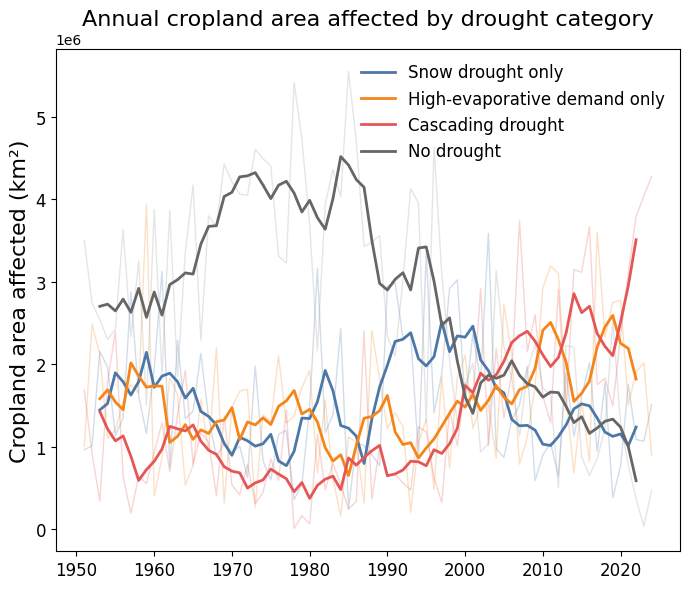

In [129]:
# ============================================================
# Plot absolute cropland area affected (km²)
# ============================================================

WINDOW = 5

# 5-year centered rolling mean of annual cropland area affected
rolling_compound_area = compound_crop_area_km2.rolling(
    wy=WINDOW, center=True
).mean()

rolling_snow_area = snow_crop_area_km2.rolling(
    wy=WINDOW, center=True
).mean()

rolling_demand_area = demand_crop_area_km2.rolling(
    wy=WINDOW, center=True
).mean()

rolling_normal_area = normal_crop_area_km2.rolling(
    wy=WINDOW, center=True
).mean()

plt.figure(figsize=(7, 6))

# ------------------------------------------------------------
# Annual cropland area affected
# Thin transparent lines show year-to-year variability
# ------------------------------------------------------------
plt.plot(
    compound_169.wy,
    snow_crop_area_km2,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    demand_crop_area_km2,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    compound_crop_area_km2,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    normal_crop_area_km2,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# ------------------------------------------------------------
# 5-year centered rolling mean
# ------------------------------------------------------------
plt.plot(
    rolling_snow_area.wy,
    rolling_snow_area,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand_area.wy,
    rolling_demand_area,
    color="#F58518",
    linewidth=2,
    label="High-evaporative demand only"
)

plt.plot(
    rolling_compound_area.wy,
    rolling_compound_area,
    color="#E45756",
    linewidth=2,
    label="Cascading drought"
)

plt.plot(
    rolling_normal_area.wy,
    rolling_normal_area,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel("Cropland area affected (km²)", fontsize=16)

plt.title(
    "Annual cropland area affected by drought category",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [130]:
# ------------------------------------------------------------
# Trend in absolute cropland area affected by cascading drought
# ------------------------------------------------------------

x = compound_crop_area_km2.wy.values
y = compound_crop_area_km2.values

# Remove any missing values
mask = np.isfinite(x) & np.isfinite(y)

# Sen's slope
# Units: km² per year
sen_slope, intercept, lower, upper = theilslopes(
    y[mask],
    x[mask],
    alpha=0.95
)

# Kendall tau trend significance
tau, p = kendalltau(
    x[mask],
    y[mask]
)

# Convert to km² per decade
trend_decade = sen_slope * 10
lower_decade = lower * 10
upper_decade = upper * 10

print(
    "Cascading drought trend:",
    round(trend_decade, 2),
    "km² per decade"
)

print(
    "95% CI:",
    round(lower_decade, 2),
    "to",
    round(upper_decade, 2),
    "km² per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.0001" if p < 0.0001 else round(p, 4)
)

Cascading drought trend: 264238.05 km² per decade
95% CI: 166969.92 to 376063.1 km² per decade
Kendall tau: 0.396
p-value: <0.0001


In [131]:
def area_trend(da, label):
    # Water year and annual affected cropland area
    x = da.wy.values.astype(float)
    y = da.values.astype(float)

    # Remove missing values
    mask = np.isfinite(x) & np.isfinite(y)

    # Sen's slope
    # Units: km² per year
    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    # Kendall tau trend significance
    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    # Convert Sen's slope to km² per decade
    trend_decade_km2 = sen_slope * 10
    lower_decade_km2 = lower * 10
    upper_decade_km2 = upper * 10

    # Convert km² per decade to million hectares per decade
    # 1 million ha = 10,000 km²
    trend_decade_mha = trend_decade_km2 / 1e4
    lower_mha = lower_decade_km2 / 1e4
    upper_mha = upper_decade_km2 / 1e4

    print("\n" + label)

    print(
        "Sen slope:",
        round(trend_decade_mha, 2),
        "million ha per decade"
    )

    print(
        "95% CI:",
        round(lower_mha, 2),
        "to",
        round(upper_mha, 2),
        "million ha per decade"
    )

    print(
        "Kendall tau:",
        round(tau, 3)
    )

    print(
        "p-value:",
        "<0.0001" if p < 0.0001 else round(p, 4)
    )


area_trend(
    snow_crop_area_km2,
    "Snow drought only"
)

area_trend(
    demand_crop_area_km2,
    "High-evaporative demand only"
)

area_trend(
    compound_crop_area_km2,
    "Cascading drought"
)

area_trend(
    normal_crop_area_km2,
    "No drought"
)


Snow drought only
Sen slope: -1.37 million ha per decade
95% CI: -8.88 to 6.27 million ha per decade
Kendall tau: -0.026
p-value: 0.7474

High-evaporative demand only
Sen slope: 6.93 million ha per decade
95% CI: -2.2 to 16.13 million ha per decade
Kendall tau: 0.125
p-value: 0.1158

Cascading drought
Sen slope: 26.42 million ha per decade
95% CI: 16.7 to 37.61 million ha per decade
Kendall tau: 0.396
p-value: <0.0001

No drought
Sen slope: -37.75 million ha per decade
95% CI: -52.47 to -24.71 million ha per decade
Kendall tau: -0.398
p-value: <0.0001


In [132]:
# Percent cropland area affected

total_crop_area_km2 = basin_crop_area_169.sum("region")

compound_crop_pct = compound_crop_area_km2 / total_crop_area_km2 * 100
snow_crop_pct     = snow_crop_area_km2     / total_crop_area_km2 * 100
demand_crop_pct   = demand_crop_area_km2   / total_crop_area_km2 * 100
normal_crop_pct   = normal_crop_area_km2   / total_crop_area_km2 * 100

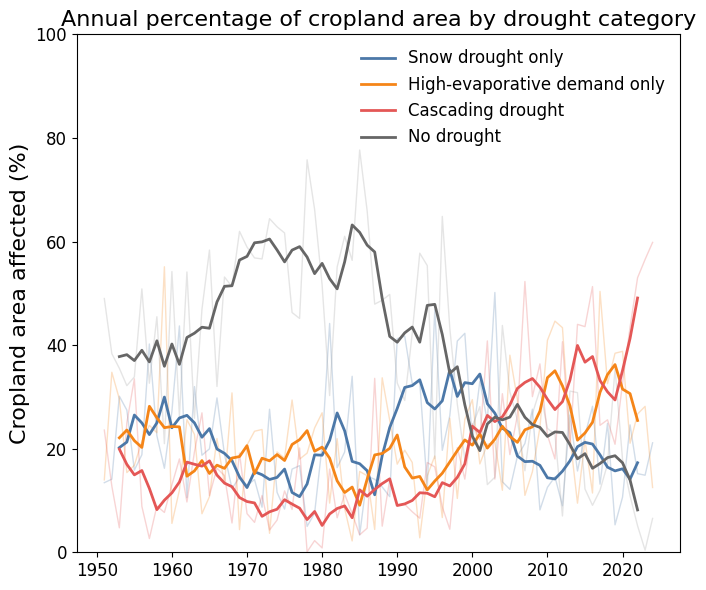

In [133]:
# ------------------------------------------------------------
# Plot percent cropland area affected
# ------------------------------------------------------------

WINDOW = 5

# 5-year centered rolling mean of annual cropland-area percentages
rolling_compound_crop_pct = compound_crop_pct.rolling(
    wy=WINDOW, center=True
).mean()

rolling_snow_crop_pct = snow_crop_pct.rolling(
    wy=WINDOW, center=True
).mean()

rolling_demand_crop_pct = demand_crop_pct.rolling(
    wy=WINDOW, center=True
).mean()

rolling_normal_crop_pct = normal_crop_pct.rolling(
    wy=WINDOW, center=True
).mean()

plt.figure(figsize=(7, 6))

# ------------------------------------------------------------
# Annual percentage of total cropland area affected
# ------------------------------------------------------------
plt.plot(
    compound_169.wy,
    snow_crop_pct,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    demand_crop_pct,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    compound_crop_pct,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_169.wy,
    normal_crop_pct,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# ------------------------------------------------------------
# 5-year centered rolling mean
# ------------------------------------------------------------
plt.plot(
    rolling_snow_crop_pct.wy,
    rolling_snow_crop_pct,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand_crop_pct.wy,
    rolling_demand_crop_pct,
    color="#F58518",
    linewidth=2,
    label="High-evaporative demand only"
)

plt.plot(
    rolling_compound_crop_pct.wy,
    rolling_compound_crop_pct,
    color="#E45756",
    linewidth=2,
    label="Cascading drought"
)

plt.plot(
    rolling_normal_crop_pct.wy,
    rolling_normal_crop_pct,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel(
    "Cropland area affected (%)",
    fontsize=16
)

plt.title(
    "Annual percentage of cropland area by drought category",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.ylim(0, 100)

plt.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [134]:
# ------------------------------------------------------------
# Trend in percentage of total cropland area affected
# by cascading drought
# ------------------------------------------------------------

x = compound_crop_pct.wy.values.astype(float)
y = compound_crop_pct.values.astype(float)

# Remove missing values
mask = np.isfinite(x) & np.isfinite(y)

# Sen's slope
# Units: percentage points per year
sen_slope, intercept, lower, upper = theilslopes(
    y[mask],
    x[mask],
    alpha=0.95
)

# Kendall tau trend significance
tau, p = kendalltau(
    x[mask],
    y[mask]
)

# Convert to percentage points per decade
trend_decade = sen_slope * 10
lower_decade = lower * 10
upper_decade = upper * 10

print(
    "Cascading drought trend:",
    round(trend_decade, 2),
    "percentage points per decade"
)

print(
    "95% CI:",
    round(lower_decade, 2),
    "to",
    round(upper_decade, 2),
    "percentage points per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.0001" if p < 0.0001 else round(p, 4)
)

Cascading drought trend: 3.69 percentage points per decade
95% CI: 2.33 to 5.26 percentage points per decade
Kendall tau: 0.396
p-value: <0.0001


In [135]:
def pct_area_trend(da, label):
    x = da.wy.values.astype(float)
    y = da.values.astype(float)

    # Remove missing values
    mask = np.isfinite(x) & np.isfinite(y)

    # Sen's slope
    # Units: percentage points per year
    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    # Kendall tau trend significance
    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    # Convert to percentage points per decade
    trend_decade = sen_slope * 10
    lower_decade = lower * 10
    upper_decade = upper * 10

    print("\n" + label)

    print(
        "Sen slope:",
        round(trend_decade, 2),
        "percentage points per decade"
    )

    print(
        "95% CI:",
        round(lower_decade, 2),
        "to",
        round(upper_decade, 2),
        "percentage points per decade"
    )

    print(
        "Kendall tau:",
        round(tau, 3)
    )

    print(
        "p-value:",
        "<0.0001" if p < 0.0001 else round(p, 4)
    )


pct_area_trend(
    snow_crop_pct,
    "Snow drought only"
)

pct_area_trend(
    demand_crop_pct,
    "High-evaporative demand only"
)

pct_area_trend(
    compound_crop_pct,
    "Cascading drought"
)

pct_area_trend(
    normal_crop_pct,
    "No drought"
)


Snow drought only
Sen slope: -0.19 percentage points per decade
95% CI: -1.24 to 0.88 percentage points per decade
Kendall tau: -0.026
p-value: 0.7474

High-evaporative demand only
Sen slope: 0.97 percentage points per decade
95% CI: -0.31 to 2.26 percentage points per decade
Kendall tau: 0.125
p-value: 0.1158

Cascading drought
Sen slope: 3.69 percentage points per decade
95% CI: 2.33 to 5.26 percentage points per decade
Kendall tau: 0.396
p-value: <0.0001

No drought
Sen slope: -5.28 percentage points per decade
95% CI: -7.33 to -3.45 percentage points per decade
Kendall tau: -0.398
p-value: <0.0001


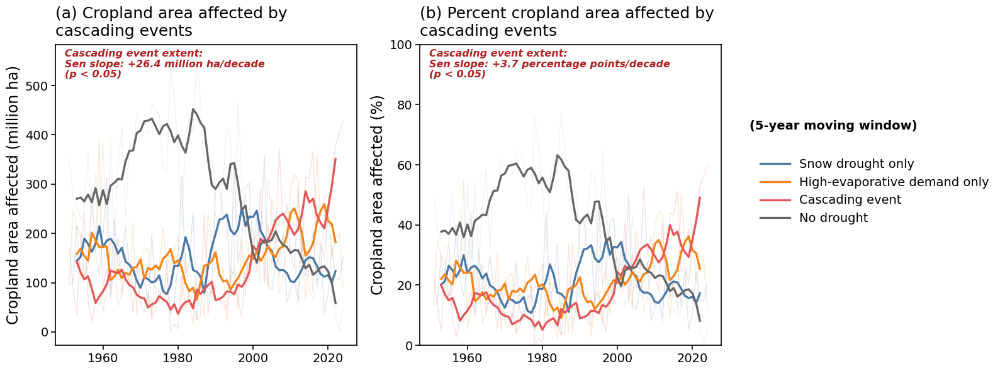

In [136]:
# ------------------------------------------------------------
# Panel plot: cropland area affected + percent cropland area affected
# ------------------------------------------------------------

from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def sen_trend_text(da, unit_label):
    x = da.wy.values
    y = da.values

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    trend_decade = sen_slope * 10
    sign = "+" if trend_decade > 0 else ""

    if p < 0.05:
        p_text = "p < 0.05"
    else:
        p_text = f"p = {p:.3f}"

    text = (
        "Cascading event extent:\n"
        f"Sen slope: {sign}{trend_decade:.1f} {unit_label}/decade\n"
        f"({p_text})"
    )

    return text, trend_decade, p


# ------------------------------------------------------------
# Convert absolute area from km² to million hectares
# ------------------------------------------------------------

compound_crop_area_mha = compound_crop_area_km2 / 1e4
snow_crop_area_mha     = snow_crop_area_km2 / 1e4
demand_crop_area_mha   = demand_crop_area_km2 / 1e4
normal_crop_area_mha   = normal_crop_area_km2 / 1e4


# ------------------------------------------------------------
# Rolling means
# ------------------------------------------------------------

WINDOW = 5

rolling_compound_area = compound_crop_area_mha.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_snow_area = snow_crop_area_mha.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_demand_area = demand_crop_area_mha.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_normal_area = normal_crop_area_mha.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_compound_pct = compound_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_snow_pct = snow_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_demand_pct = demand_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_normal_pct = normal_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()


# ------------------------------------------------------------
# Trend annotations
# ------------------------------------------------------------

area_text, area_trend, area_p = sen_trend_text(
    compound_crop_area_mha,
    "million ha"
)

pct_text, pct_trend, pct_p = sen_trend_text(
    compound_crop_pct,
    "percentage points"
)


# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------

colors = {
    "snow": "#4C78A8",
    "demand": "#F58518",
    "compound": "#E45756",
    "normal": "0.4"
}

annual_alpha = 0.18
annual_lw = 1.0
rolling_lw = 2.4

title_fs = 18
label_fs = 17
tick_fs = 14
legend_fs = 14
annotation_fs = 11.5


# ------------------------------------------------------------
# Figure with separate legend column
# ------------------------------------------------------------

fig = plt.figure(figsize=(17, 7))

gs = fig.add_gridspec(
    nrows=1,
    ncols=3,
    width_ratios=[1.35, 1.35, 0.45],
    wspace=0.27
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
leg_ax = fig.add_subplot(gs[0, 2])

leg_ax.axis("off")

# Square panels
ax1.set_box_aspect(1)
ax2.set_box_aspect(1)


# ============================================================
# Panel (a): Absolute cropland area affected
# ============================================================

# Annual thin lines
ax1.plot(
    compound_crop_area_mha.wy,
    snow_crop_area_mha,
    color=colors["snow"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax1.plot(
    compound_crop_area_mha.wy,
    demand_crop_area_mha,
    color=colors["demand"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax1.plot(
    compound_crop_area_mha.wy,
    compound_crop_area_mha,
    color=colors["compound"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax1.plot(
    compound_crop_area_mha.wy,
    normal_crop_area_mha,
    color="0.75",
    alpha=annual_alpha,
    linewidth=annual_lw
)

# 5-year rolling means
ax1.plot(
    rolling_snow_area.wy,
    rolling_snow_area,
    color=colors["snow"],
    linewidth=rolling_lw,
    label="Snow drought only"
)

ax1.plot(
    rolling_demand_area.wy,
    rolling_demand_area,
    color=colors["demand"],
    linewidth=rolling_lw,
    label="High-evaporative demand only"
)

ax1.plot(
    rolling_compound_area.wy,
    rolling_compound_area,
    color=colors["compound"],
    linewidth=rolling_lw,
    label="Cascading event"
)

ax1.plot(
    rolling_normal_area.wy,
    rolling_normal_area,
    color=colors["normal"],
    linewidth=rolling_lw,
    label="No drought"
)

ax1.set_title(
    "(a) Cropland area affected by \ncascading events",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax1.set_ylabel(
    "Cropland area affected (million ha)",
    fontsize=label_fs
)

ax1.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)

# Trend annotation
ax1.text(
    0.03,
    0.985,
    area_text,
    transform=ax1.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)


# ============================================================
# Panel (b): Percent cropland area affected
# ============================================================

# Annual thin lines
ax2.plot(
    compound_crop_pct.wy,
    snow_crop_pct,
    color=colors["snow"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax2.plot(
    compound_crop_pct.wy,
    demand_crop_pct,
    color=colors["demand"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax2.plot(
    compound_crop_pct.wy,
    compound_crop_pct,
    color=colors["compound"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax2.plot(
    compound_crop_pct.wy,
    normal_crop_pct,
    color="0.75",
    alpha=annual_alpha,
    linewidth=annual_lw
)

# 5-year rolling means
ax2.plot(
    rolling_snow_pct.wy,
    rolling_snow_pct,
    color=colors["snow"],
    linewidth=rolling_lw
)

ax2.plot(
    rolling_demand_pct.wy,
    rolling_demand_pct,
    color=colors["demand"],
    linewidth=rolling_lw
)

ax2.plot(
    rolling_compound_pct.wy,
    rolling_compound_pct,
    color=colors["compound"],
    linewidth=rolling_lw
)

ax2.plot(
    rolling_normal_pct.wy,
    rolling_normal_pct,
    color=colors["normal"],
    linewidth=rolling_lw
)

ax2.set_title(
    "(b) Percent cropland area affected by \ncascading events",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax2.set_ylabel(
    "Cropland area affected (%)",
    fontsize=label_fs
)

ax2.set_ylim(0, 100)

ax2.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)

# Trend annotation
ax2.text(
    0.03,
    0.985,
    pct_text,
    transform=ax2.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)


# ============================================================
# Shared legend on the right
# ============================================================

legend_handles = [
    Line2D(
        [0], [0],
        color=colors["snow"],
        linewidth=rolling_lw,
        label="Snow drought only"
    ),
    Line2D(
        [0], [0],
        color=colors["demand"],
        linewidth=rolling_lw,
        label="High-evaporative demand only"
    ),
    Line2D(
        [0], [0],
        color=colors["compound"],
        linewidth=rolling_lw,
        label="Cascading event"
    ),
    Line2D(
        [0], [0],
        color=colors["normal"],
        linewidth=rolling_lw,
        label="No drought"
    ),
]

leg_ax.text(
    -0.35,
    0.72,
    f"({WINDOW}-year moving window)",
    fontsize=legend_fs,
    fontweight="bold",
    ha="left",
    va="top"
)

leg_ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(-0.35, 0.64),
    frameon=False,
    fontsize=legend_fs,
    handlelength=2.4
)


# ============================================================
# Final formatting: full black outline around panels
# ============================================================

for ax in [ax1, ax2]:
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.2)


# ============================================================
# Save
# ============================================================

plt.savefig(
    "Fig_S5.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [137]:
check_regions = [0, 25, 40]

yrs = compound_169.wy.values

for rr in check_regions:

    # Select one basin across all water years
    y = compound_169.isel(region=rr).astype(int).values

    print("\nRegion position:", rr)
    print("MAIN_BAS:", compound_169.region.values[rr])

    print(
        "Number of cascading-event years:",
        int(y.sum())
    )

    print(
        "Years with cascading events:",
        yrs[y == 1]
    )

    print("Full 0/1 series:")
    print(y)


Region position: 0
MAIN_BAS: 1040028970
Number of cascading-event years: 15
Years with cascading events: [1957 1964 2001 2003 2008 2010 2012 2013 2014 2017 2019 2020 2021 2022
 2024]
Full 0/1 series:
[0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 1 0 1 1 1 0 0 1 0 1 1 1 1 0 1]

Region position: 25
MAIN_BAS: 2040018850
Number of cascading-event years: 16
Years with cascading events: [1957 1961 1962 1989 1990 1995 1996 2001 2003 2004 2005 2012 2016 2017
 2022 2023]
Full 0/1 series:
[0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 1 1 0 0 0 0 1 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 1 0]

Region position: 40
MAIN_BAS: 2040026070
Number of cascading-event years: 17
Years with cascading events: [1951 1975 1989 1992 1994 2007 2008 2009 2014 2015 2016 2018 2019 2020
 2022 2023 2024]
Full 0/1 series:
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 

In [138]:
# GeoDataFrame aligned with compound_169
analysis_ids = compound_169.region.values

basins_diss_169 = (
    basins_diss[
        basins_diss["MAIN_BAS"].isin(analysis_ids)
    ]
    .set_index("MAIN_BAS")
    .reindex(analysis_ids)
    .reset_index()
)

print(len(basins_diss_169))  # should be 169

assert np.array_equal(
    basins_diss_169["MAIN_BAS"].values,
    compound_169.region.values
)

169


In [139]:
# ------------------------------------------------------------
# Basin-level logistic trends in cascading-event occurrence
# ------------------------------------------------------------

trend_per_basin = []
pvals = []

beta0_per_basin = []
beta1_per_basin = []

# Water years
x = compound_169["wy"].values.astype(float)


for r in range(compound_169.sizes["region"]):

    # Annual 0/1 cascading-event series
    y = (
        compound_169
        .isel(region=r)
        .values
        .astype(float)
    )

    # Valid basin-years
    valid = np.isfinite(x) & np.isfinite(y)

    x_valid = x[valid]
    y_valid = y[valid]

    # Too few valid years
    if len(y_valid) < 2:

        trend_per_basin.append(np.nan)
        pvals.append(np.nan)

        beta0_per_basin.append(np.nan)
        beta1_per_basin.append(np.nan)

        continue

    # Constant 0/1 series
    if np.std(y_valid) == 0:

        trend_per_basin.append(0.0)
        pvals.append(1.0)

        beta0_per_basin.append(np.nan)
        beta1_per_basin.append(0.0)

        continue

    # Center time
    x_centered = x_valid - x_valid.mean()

    # Add intercept
    X = sm_stats.add_constant(
        x_centered
    )

    try:

        # Binomial logistic regression
        model = sm_stats.GLM(
            y_valid,
            X,
            family=sm_stats.families.Binomial()
        ).fit()

        # Logistic coefficients
        beta0 = model.params[0]
        beta1 = model.params[1]

        # p-value for temporal coefficient beta1
        p = model.pvalues[1]

        # Predicted annual probabilities
        p_hat = model.predict(X)

        # Year-specific marginal probability trends
        marginal_effect_yearly = (
            beta1
            * p_hat
            * (1 - p_hat)
        )

        # Average marginal effect across all years
        mean_marginal_effect = np.mean(
            marginal_effect_yearly
        )

        # Convert probability/year → Δ%/decade
        trend_pct_decade = (
            mean_marginal_effect
            * 100
            * 10
        )

        # Store
        trend_per_basin.append(
            trend_pct_decade
        )

        pvals.append(
            p
        )

        beta0_per_basin.append(
            beta0
        )

        beta1_per_basin.append(
            beta1
        )

    except Exception as e:

        print(
            f"Region {r} failed:",
            repr(e)
        )

        trend_per_basin.append(np.nan)
        pvals.append(np.nan)

        beta0_per_basin.append(np.nan)
        beta1_per_basin.append(np.nan)


# Convert to arrays
trend_per_basin = np.asarray(trend_per_basin)
pvals = np.asarray(pvals)

beta0_per_basin = np.asarray(beta0_per_basin)
beta1_per_basin = np.asarray(beta1_per_basin)


# Diagnostics
print(
    "Number of basins:",
    len(trend_per_basin)
)

print(
    "Successful logistic models:",
    np.sum(np.isfinite(beta1_per_basin))
)

print(
    "Trend range (Δ%/decade):",
    np.nanmin(trend_per_basin),
    np.nanmax(trend_per_basin)
)

print(
    "Beta1 range (log-odds/year):",
    np.nanmin(beta1_per_basin),
    np.nanmax(beta1_per_basin)
)

print(
    "p < 0.05:",
    np.sum(pvals < 0.05)
)

Number of basins: 169
Successful logistic models: 169
Trend range (Δ%/decade): -5.43104124577027 11.755542074704977
Beta1 range (log-odds/year): -0.0367618815852203 0.11618349906045115
p < 0.05: 121


In [140]:
# ------------------------------------------------------------
# Add basin-level cascading-event trends to GeoDataFrame
# ------------------------------------------------------------

basins_diss_169["compound_trend_pct_decade"] = trend_per_basin
basins_diss_169["p_trend"] = pvals

basins_diss_169["compound_logit_beta0"] = beta0_per_basin
basins_diss_169["compound_logit_beta1"] = beta1_per_basin

# Significant trend at p < 0.05
basins_diss_169["sig_trend"] = (
    basins_diss_169["p_trend"] < 0.05
)

# Significant increasing trends
pos_sig = (
    basins_diss_169["sig_trend"] &
    (basins_diss_169["compound_trend_pct_decade"] > 0)
)

# Significant decreasing trends
neg_sig = (
    basins_diss_169["sig_trend"] &
    (basins_diss_169["compound_trend_pct_decade"] < 0)
)

# Counts
n_sig = int(basins_diss_169["sig_trend"].sum())
n_pos_sig = int(pos_sig.sum())
n_neg_sig = int(neg_sig.sum())

n_total = len(basins_diss_169)   # should be 169

print("Total basins:", n_total)
print("Significant trends:", n_sig)
print("Significantly increasing:", n_pos_sig)
print("Significantly decreasing:", n_neg_sig)

print(
    "% significantly increasing:",
    round(n_pos_sig / n_total * 100, 1)
)

print(
    "% significantly decreasing:",
    round(n_neg_sig / n_total * 100, 1)
)

Total basins: 169
Significant trends: 121
Significantly increasing: 120
Significantly decreasing: 1
% significantly increasing: 71.0
% significantly decreasing: 0.6


/tmp/ipykernel_1915107/1016713823.py:89: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


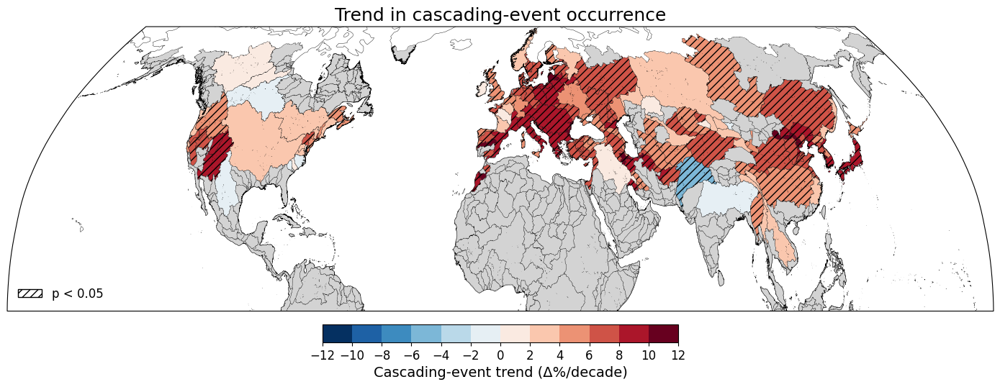

In [141]:
# ------------------------------------------------------------
# Prepare full basin GeoDataFrame for plotting
# ------------------------------------------------------------

# Start with all basins so excluded basins can remain gray
basins_diss_plot = basins_diss.copy()

# Trend results from the 169 analysis basins
cols = [
    "MAIN_BAS",
    "compound_trend_pct_decade",
    "p_trend",
    "sig_trend"
]

# Remove old versions of these columns if they already exist
basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "compound_trend_pct_decade",
        "p_trend",
        "sig_trend"
    ],
    errors="ignore"
)

# Join the 169-basin trend results back to all basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_169[cols],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Discrete diverging bins
# Units = percentage points per decade
# ------------------------------------------------------------

bins = np.array([
    -12, -10, -8, -6, -4, -2,
     0,
     2, 4, 6, 8, 10, 12
])

cmap = plt.get_cmap(
    "RdBu_r",
    len(bins) - 1
)

norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig = plt.figure(figsize=(14, 7))

ax = plt.axes(
    projection=ccrs.Robinson()
)

# ------------------------------------------------------------
# Base trend map
# ------------------------------------------------------------

basins_diss_plot.plot(
    column="compound_trend_pct_decade",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax
)

# ------------------------------------------------------------
# Hatching for significant basin-level trends
# ------------------------------------------------------------

sig_mask = (
    basins_diss_plot["sig_trend"]
    .fillna(False)
    .astype(bool)
)

basins_diss_plot.loc[sig_mask].plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

sm = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar.set_label(
    "Cascading-event trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=12
)

# ------------------------------------------------------------
# Significance legend
# ------------------------------------------------------------

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

# ------------------------------------------------------------
# Map formatting
# ------------------------------------------------------------

ax.set_title(
    "Trend in cascading-event occurrence",
    fontsize=18
)

ax.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)

ax.coastlines(
    linewidth=0.3
)

plt.tight_layout()
plt.show()

In [142]:
# Basin with largest positive logistic coefficient
r_max = np.nanargmax(beta1_per_basin)

print("Region position:", r_max)
print("MAIN_BAS:", compound_169.region.values[r_max])
print("Beta1:", beta1_per_basin[r_max])
print("Trend Δ%/decade:", trend_per_basin[r_max])
print("p-value:", pvals[r_max])

y = compound_169.isel(region=r_max).values.astype(int)
yrs = compound_169.wy.values

print("Number of cascading events:", y.sum())
print("Event years:")
print(yrs[y == 1])

print("Full series:")
print(y)

Region position: 1
MAIN_BAS: 1040029430
Beta1: 0.11618349906045115
Trend Δ%/decade: 11.397032527077965
p-value: 0.00017008475157587684
Number of cascading events: 16
Event years:
[1964 2000 2003 2005 2010 2011 2012 2013 2014 2017 2019 2020 2021 2022
 2023 2024]
Full series:
[0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 1 1 1 1 1 0 0 1 0 1 1 1 1 1 1]


In [143]:
r = 0

y = compound_169.isel(region=r).values.astype(float)
x = compound_169.wy.values.astype(float)

valid = np.isfinite(x) & np.isfinite(y)

xv = x[valid]
yv = y[valid]

# Center time
xc = xv - xv.mean()

# Add intercept
X = sm_stats.add_constant(xc)

# Logistic regression
model = sm_stats.GLM(
    yv,
    X,
    family=sm_stats.families.Binomial()
).fit()

# Predicted annual probabilities
p_hat = model.predict(X)

beta0 = model.params[0]
beta1 = model.params[1]
p_value = model.pvalues[1]

# Year-specific marginal effects
marginal_effect = (
    beta1
    * p_hat
    * (1 - p_hat)
)

# Average marginal effect
mean_marginal_effect = np.mean(marginal_effect)

# Convert to Δ%/decade
trend_pct_decade = (
    mean_marginal_effect
    * 100
    * 10
)

print("MAIN_BAS =", compound_169.region.values[r])
print("beta0 =", beta0)
print("beta1 =", beta1)
print("p-value =", p_value)
print("Mean marginal effect =", mean_marginal_effect)
print("Trend Δ%/decade =", trend_pct_decade)

print("\nYear  Observed  Predicted_p  Marginal_effect")

for yr, obs, prob, me in zip(
    xv,
    yv,
    p_hat,
    marginal_effect
):
    print(
        int(yr),
        "observed =", int(obs),
        "predicted p =", round(prob, 3),
        "marginal effect =", round(me, 5)
    )

MAIN_BAS = 1040028970
beta0 = -1.9856173384031668
beta1 = 0.07207797935968493
p-value = 0.000665110227936975
Mean marginal effect = 0.008845835932662036
Trend Δ%/decade = 8.845835932662036

Year  Observed  Predicted_p  Marginal_effect
1951 observed = 0 predicted p = 0.01 marginal effect = 0.0007
1952 observed = 0 predicted p = 0.011 marginal effect = 0.00075
1953 observed = 0 predicted p = 0.011 marginal effect = 0.0008
1954 observed = 0 predicted p = 0.012 marginal effect = 0.00086
1955 observed = 0 predicted p = 0.013 marginal effect = 0.00093
1956 observed = 0 predicted p = 0.014 marginal effect = 0.00099
1957 observed = 1 predicted p = 0.015 marginal effect = 0.00107
1958 observed = 0 predicted p = 0.016 marginal effect = 0.00114
1959 observed = 0 predicted p = 0.017 marginal effect = 0.00123
1960 observed = 0 predicted p = 0.019 marginal effect = 0.00131
1961 observed = 0 predicted p = 0.02 marginal effect = 0.00141
1962 observed = 0 predicted p = 0.021 marginal effect = 0.00151
1

In [144]:
# ============================================================
# Separation and sparsity diagnostics for all 169 basins
# ============================================================

diagnostics = []

x = compound_169["wy"].values.astype(float)

for r in range(compound_169.sizes["region"]):

    y = (
        compound_169
        .isel(region=r)
        .values
        .astype(float)
    )

    valid = np.isfinite(x) & np.isfinite(y)

    xv = x[valid]
    yv = y[valid]

    n = len(yv)
    n_events = int(np.sum(yv == 1))
    n_nonevents = int(np.sum(yv == 0))

    # --------------------------------------------------------
    # Sparsity
    # --------------------------------------------------------

    # You can inspect both <=5 and <=10;
    # these are diagnostic flags, not formal cutoffs.
    sparse_events_5 = n_events <= 5
    sparse_events_10 = n_events <= 10

    sparse_nonevents_5 = n_nonevents <= 5

    # --------------------------------------------------------
    # Complete separation in time
    # --------------------------------------------------------

    complete_sep_positive = False
    complete_sep_negative = False

    if n_events > 0 and n_nonevents > 0:

        event_years = xv[yv == 1]
        nonevent_years = xv[yv == 0]

        # All 0s before all 1s
        complete_sep_positive = (
            nonevent_years.max() < event_years.min()
        )

        # All 1s before all 0s
        complete_sep_negative = (
            event_years.max() < nonevent_years.min()
        )

    complete_separation = (
        complete_sep_positive
        or complete_sep_negative
    )

    # --------------------------------------------------------
    # Fit logistic model
    # --------------------------------------------------------

    if n_events > 0 and n_nonevents > 0:

        xc = xv - xv.mean()
        X = sm_stats.add_constant(xc)

        try:

            model = sm_stats.GLM(
                yv,
                X,
                family=sm_stats.families.Binomial()
            ).fit()

            beta0 = model.params[0]
            beta1 = model.params[1]

            beta1_se = model.bse[1]
            p_value = model.pvalues[1]

            p_hat = model.predict(X)

            min_p_hat = np.min(p_hat)
            max_p_hat = np.max(p_hat)

            # Diagnostic for probabilities very close to 0/1
            extreme_prob = (
                (min_p_hat < 0.001)
                or (max_p_hat > 0.999)
            )

        except Exception:

            beta0 = np.nan
            beta1 = np.nan
            beta1_se = np.nan
            p_value = np.nan
            min_p_hat = np.nan
            max_p_hat = np.nan
            extreme_prob = False

    else:

        beta0 = np.nan
        beta1 = np.nan
        beta1_se = np.nan
        p_value = np.nan
        min_p_hat = np.nan
        max_p_hat = np.nan
        extreme_prob = False

    diagnostics.append({
        "region_position": r,
        "MAIN_BAS": compound_169.region.values[r],
        "n_years": n,
        "n_events": n_events,
        "n_nonevents": n_nonevents,
        "sparse_events_5": sparse_events_5,
        "sparse_events_10": sparse_events_10,
        "complete_separation": complete_separation,
        "complete_sep_positive": complete_sep_positive,
        "complete_sep_negative": complete_sep_negative,
        "beta1": beta1,
        "beta1_se": beta1_se,
        "p_value": p_value,
        "min_p_hat": min_p_hat,
        "max_p_hat": max_p_hat,
        "extreme_probability": extreme_prob
    })


diagnostics = pd.DataFrame(diagnostics)

In [145]:
print("Total basins:", len(diagnostics))

print(
    "Basins with <= 5 cascading events:",
    diagnostics["sparse_events_5"].sum()
)

print(
    "Basins with <= 10 cascading events:",
    diagnostics["sparse_events_10"].sum()
)

print(
    "Basins with complete separation:",
    diagnostics["complete_separation"].sum()
)

print(
    "Basins with extreme fitted probabilities:",
    diagnostics["extreme_probability"].sum()
)

Total basins: 169
Basins with <= 5 cascading events: 0
Basins with <= 10 cascading events: 7
Basins with complete separation: 0
Basins with extreme fitted probabilities: 0


In [146]:
# ============================================================
# More useful logistic-fit stability diagnostics
# ============================================================

# Wald z statistic
diagnostics["z_beta1"] = (
    diagnostics["beta1"]
    / diagnostics["beta1_se"]
)

# Relative uncertainty in beta1
diagnostics["relative_se"] = (
    np.abs(
        diagnostics["beta1_se"]
        / diagnostics["beta1"]
    )
)

print(
    "Median beta1 SE:",
    diagnostics["beta1_se"].median()
)

print(
    "Maximum beta1 SE:",
    diagnostics["beta1_se"].max()
)

print(
    "Basins with beta1 SE > 0.1:",
    (diagnostics["beta1_se"] > 0.1).sum()
)

print(
    "Basins with beta1 SE > 0.2:",
    (diagnostics["beta1_se"] > 0.2).sum()
)

print("\nLargest coefficient uncertainties:")

display(
    diagnostics[
        [
            "MAIN_BAS",
            "n_events",
            "beta1",
            "beta1_se",
            "p_value",
            "min_p_hat",
            "max_p_hat"
        ]
    ]
    .sort_values(
        "beta1_se",
        ascending=False
    )
    .head(15)
)

Median beta1 SE: 0.016812462213233934
Maximum beta1 SE: 0.030901939726058716
Basins with beta1 SE > 0.1: 0
Basins with beta1 SE > 0.2: 0

Largest coefficient uncertainties:


,MAIN_BAS,n_events,beta1,beta1_se,p_value,min_p_hat,max_p_hat
1,1040029430,16,0.116183,0.030902,0.000170,0.001060,0.836540
44,2040026930,15,0.109536,0.029943,0.000254,0.001330,0.798189
136,4040051530,16,0.109858,0.029248,0.000173,0.001495,0.819850
24,2040018840,14,0.101052,0.028582,0.000407,0.001854,0.748053
18,2040008500,14,0.099442,0.028169,0.000415,0.002026,0.742577
61,2040065960,16,0.104167,0.027805,0.000179,0.002032,0.803406
73,2040070510,15,0.101215,0.027803,0.000272,0.002096,0.772584
134,4040050830,15,0.100447,0.027610,0.000275,0.002185,0.770067
22,2040016230,13,0.092590,0.027317,0.000700,0.002586,0.690875
94,4040005060,10,0.079571,0.027196,0.003436,0.003517,0.540431


In [147]:
diagnostics.loc[
    diagnostics["n_events"] <= 5,
    [
        "MAIN_BAS",
        "n_events",
        "beta1",
        "beta1_se",
        "p_value",
        "min_p_hat",
        "max_p_hat"
    ]
]

,MAIN_BAS,n_events,beta1,beta1_se,p_value,min_p_hat,max_p_hat


In [148]:
def basin_logistic_trend(mask_da):
    """
    Calculate basin-level logistic trends in annual 0/1 event occurrence.

    Parameters
    ----------
    mask_da : xarray.DataArray
        Boolean or 0/1 array with dimensions including:
        - region
        - wy

    Returns
    -------
    trends_pct_decade : np.ndarray
        Mean marginal change in event probability, expressed as
        Δ%/decade for each basin.

    pvals : np.ndarray
        Two-sided p-value for the logistic time coefficient beta1.

    beta1s : np.ndarray
        Logistic time coefficient in log-odds/year.
    """

    # Water years
    x = mask_da["wy"].values.astype(float)

    n_regions = mask_da.sizes["region"]

    trends_pct_decade = np.full(
        n_regions,
        np.nan
    )

    pvals = np.full(
        n_regions,
        np.nan
    )

    beta1s = np.full(
        n_regions,
        np.nan
    )

    # Loop through basins
    for r in range(n_regions):

        # Annual 0/1 event-occurrence series
        y = (
            mask_da
            .isel(region=r)
            .values
            .astype(float)
        )

        # Valid basin-years
        valid = np.isfinite(x) & np.isfinite(y)

        if valid.sum() < 2:
            continue

        x_valid = x[valid]
        y_valid = y[valid]

        # Constant series: no temporal trend
        if np.all(y_valid == y_valid[0]):

            trends_pct_decade[r] = 0.0
            pvals[r] = 1.0
            beta1s[r] = 0.0

            continue

        # Center time for numerical stability
        x_centered = (
            x_valid - x_valid.mean()
        )

        # Add intercept
        X = sm_stats.add_constant(
            x_centered
        )

        try:

            # Binomial logistic regression
            model = sm_stats.GLM(
                y_valid,
                X,
                family=sm_stats.families.Binomial()
            ).fit()

            # Logistic time coefficient
            beta1 = model.params[1]

            # p-value for beta1
            pval = model.pvalues[1]

            # Predicted probability in each year
            p_hat = model.predict(X)

            # Year-specific marginal probability change
            #
            # dp_t/dt = beta1 * p_t * (1 - p_t)
            marginal_effects = (
                beta1
                * p_hat
                * (1 - p_hat)
            )

            # Mean marginal effect across all years
            mean_marginal_effect = np.mean(
                marginal_effects
            )

            # Convert probability/year to Δ%/decade
            trends_pct_decade[r] = (
                mean_marginal_effect
                * 100
                * 10
            )

            pvals[r] = pval
            beta1s[r] = beta1

        except Exception as e:

            print(
                f"Region {r} failed:",
                repr(e)
            )

    return (
        trends_pct_decade,
        pvals,
        beta1s
    )

In [149]:
compound_slope, compound_p, compound_beta1 = basin_logistic_trend(compound_169)
snow_slope, snow_p, snow_beta1 = basin_logistic_trend(snow_169)
demand_slope, demand_p, demand_beta1 = basin_logistic_trend(demand_169)
normal_slope, normal_p, normal_beta1 = basin_logistic_trend(normal_169)

In [150]:
basins_diss_169["compound_trend"] = compound_slope
basins_diss_169["compound_p"] = compound_p
basins_diss_169["compound_beta1"] = compound_beta1

basins_diss_169["snow_trend"] = snow_slope
basins_diss_169["snow_p"] = snow_p
basins_diss_169["snow_beta1"] = snow_beta1

basins_diss_169["demand_trend"] = demand_slope
basins_diss_169["demand_p"] = demand_p
basins_diss_169["demand_beta1"] = demand_beta1

basins_diss_169["normal_trend"] = normal_slope
basins_diss_169["normal_p"] = normal_p
basins_diss_169["normal_beta1"] = normal_beta1

In [151]:
n_total = len(basins_diss_169)

for label, trend_col, p_col in [
    ("Cascading event", "compound_trend", "compound_p"),
    ("Snow drought only", "snow_trend", "snow_p"),
    ("High-evaporative demand only", "demand_trend", "demand_p"),
    ("No drought", "normal_trend", "normal_p")
]:

    valid = (
        basins_diss_169[trend_col].notna()
        &
        basins_diss_169[p_col].notna()
    )

    sig = (
        valid
        &
        (basins_diss_169[p_col] < 0.05)
    )

    pos = (
        sig
        &
        (basins_diss_169[trend_col] > 0)
    )

    neg = (
        sig
        &
        (basins_diss_169[trend_col] < 0)
    )

    n_valid = int(valid.sum())
    n_sig = int(sig.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_sig = 100 * n_sig / n_valid
    pct_pos = 100 * n_pos / n_valid
    pct_neg = 100 * n_neg / n_valid

    print(f"\n{label}")
    print("Valid basins:", n_valid)
    print(f"Significant: {n_sig} ({pct_sig:.1f}%)")
    print(f"Increasing: {n_pos} ({pct_pos:.1f}%)")
    print(f"Decreasing: {n_neg} ({pct_neg:.1f}%)")


Cascading event
Valid basins: 169
Significant: 121 (71.6%)
Increasing: 120 (71.0%)
Decreasing: 1 (0.6%)

Snow drought only
Valid basins: 169
Significant: 26 (15.4%)
Increasing: 4 (2.4%)
Decreasing: 22 (13.0%)

High-evaporative demand only
Valid basins: 169
Significant: 43 (25.4%)
Increasing: 38 (22.5%)
Decreasing: 5 (3.0%)

No drought
Valid basins: 169
Significant: 121 (71.6%)
Increasing: 1 (0.6%)
Decreasing: 120 (71.0%)


In [152]:
print("Regions in compound (full):", compound.sizes["region"])
print("Regions in compound_169:", compound_169.sizes["region"])

print("Rows in basins_diss (full):", len(basins_diss))
print("Rows in basins_diss_169:", len(basins_diss_169))

Regions in compound (full): 602
Regions in compound_169: 169
Rows in basins_diss (full): 602
Rows in basins_diss_169: 169


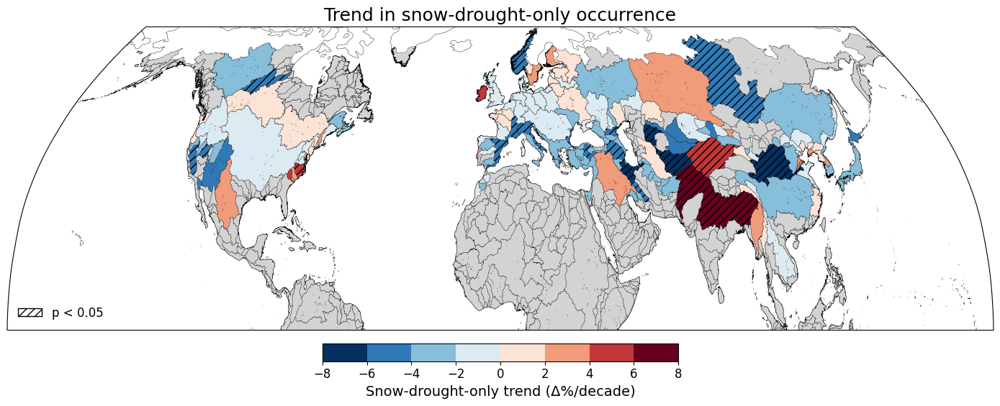

In [153]:
# ============================================================
# Keep all basins; missing/NaN trends will plot as gray
# ============================================================

basins_diss_plot = basins_diss.copy()

# Remove old snow trend columns if rerunning
basins_diss_plot = basins_diss_plot.drop(
    columns=["snow_trend", "snow_p"],
    errors="ignore"
)

# Join the correctly aligned 169-basin logistic trend results
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_169[
        ["MAIN_BAS", "snow_trend", "snow_p"]
    ],
    on="MAIN_BAS",
    how="left"
)


# ============================================================
# Significance mask
# p-value is for the logistic time coefficient beta1
# ============================================================

basins_diss_plot["sig_snow_trend"] = (
    basins_diss_plot["snow_p"].fillna(1.0) < 0.05
)


# ============================================================
# Discrete bins
# snow_trend = mean marginal probability trend in Δ%/decade
# ============================================================

bins = [-8, -6, -4, -2, 0, 2, 4, 6, 8]

cmap = plt.get_cmap(
    "RdBu_r",
    len(bins) - 1
)

norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)


# ============================================================
# Plot
# ============================================================

fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=ccrs.Robinson())


# Base map
basins_diss_plot.plot(
    column="snow_trend",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax
)


# Hatching for significant logistic trends
basins_diss_plot.loc[
    basins_diss_plot["sig_snow_trend"]
].plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)


# ============================================================
# Colorbar
# ============================================================

scalar_map = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

scalar_map.set_array([])

cbar = plt.colorbar(
    scalar_map,
    ax=ax,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar.set_label(
    "Snow-drought-only trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=12
)


# ============================================================
# Hatch legend
# ============================================================

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)


# ============================================================
# Map formatting
# ============================================================

ax.set_title(
    "Trend in snow-drought-only occurrence",
    fontsize=18
)

ax.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)

ax.coastlines(
    linewidth=0.3
)

plt.tight_layout()
plt.show()

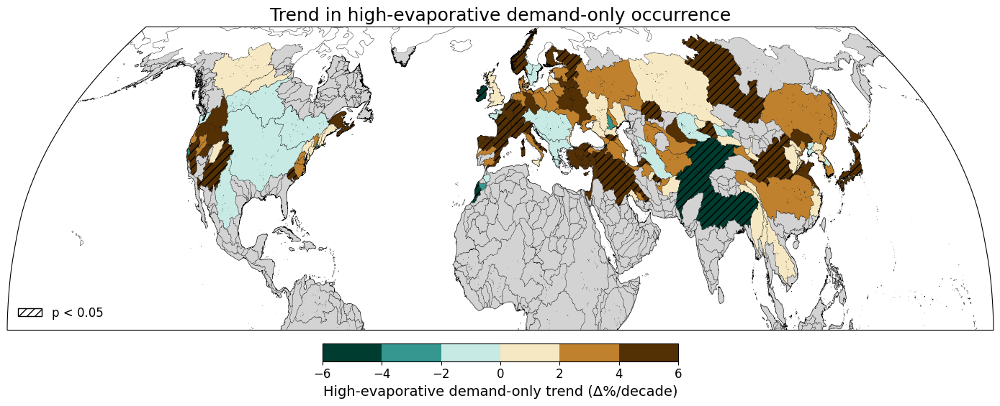

In [154]:
# Keep all basins; missing/NaN trends will plot as gray
basins_diss_plot = basins_diss.copy()

# Remove any old or misaligned demand-trend columns
basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "demand_trend",
        "demand_p",
        "sig_demand_trend"
    ],
    errors="ignore"
)

# Join the correctly aligned 169-basin logistic trend results
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_169[
        ["MAIN_BAS", "demand_trend", "demand_p"]
    ],
    on="MAIN_BAS",
    how="left"
)

# Significance mask
# demand_p is the p-value for the logistic time coefficient beta1
basins_diss_plot["sig_demand_trend"] = (
    basins_diss_plot["demand_p"].fillna(1.0) < 0.05
)

# Discrete bins
bins = [-6, -4, -2, 0, 2, 4, 6]

cmap = plt.get_cmap(
    "BrBG_r",
    len(bins) - 1
)

norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=ccrs.Robinson())

# Base map
# demand_trend = mean marginal probability trend in Δ%/decade
basins_diss_plot.plot(
    column="demand_trend",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax
)

# Hatching for significant logistic trends
basins_diss_plot.loc[
    basins_diss_plot["sig_demand_trend"]
].plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

# Colorbar
scalar_map = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

scalar_map.set_array([])

cbar = plt.colorbar(
    scalar_map,
    ax=ax,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar.set_label(
    "High-evaporative demand-only trend "
    "(Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=12
)

# Hatch legend
hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax.set_title(
    "Trend in high-evaporative demand-only occurrence",
    fontsize=18
)

ax.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)

ax.coastlines(
    linewidth=0.3
)

plt.tight_layout()
plt.show()

Valid basins: 169
Significantly increasing basins: 120
% significantly increasing: 71.0

Cascading-event basin trend: 4.93 Δ%/decade
95% CI: 3.36 to 6.43 Δ%/decade
Kendall tau: 0.506
p-value: p < 0.0001


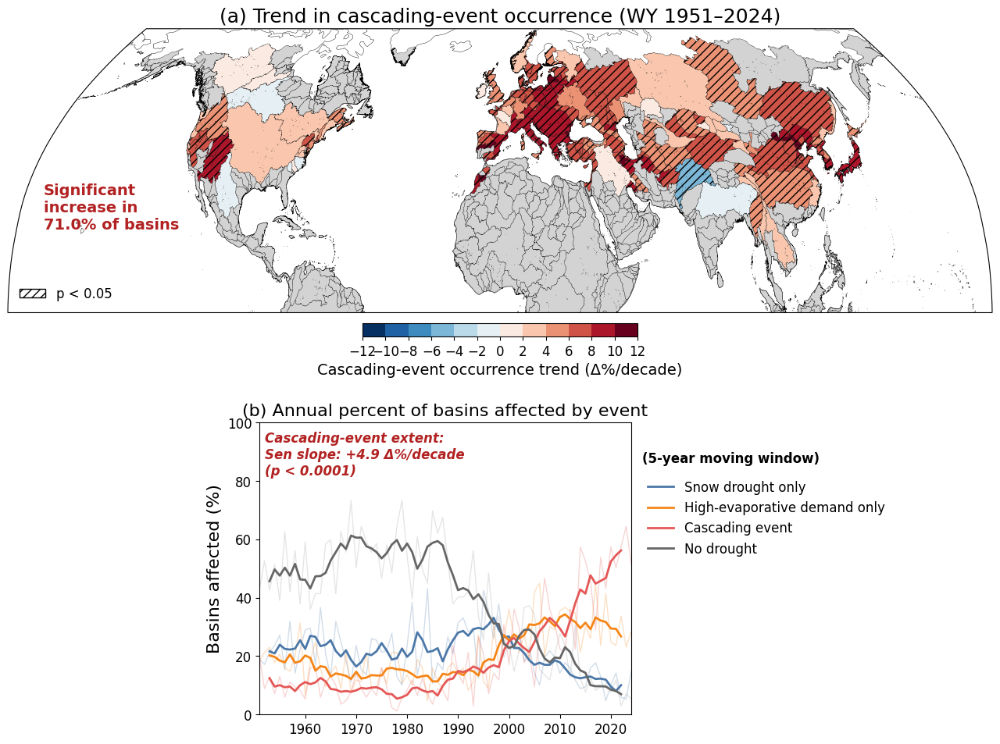

In [155]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs

from scipy.stats import theilslopes, kendalltau


# ============================================================
# (a) Prepare basin-level logistic trend results for mapping
# ============================================================

# Start with the full basin GeoDataFrame so that basins that
# were excluded from the 169-basin analysis can still be shown
# in gray on the map.
basins_diss_plot = basins_diss.copy()


# Remove any old versions of the trend columns before merging
# the current logistic-regression results.
basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "compound_trend_pct_decade",
        "p_trend",
        "sig_trend"
    ],
    errors="ignore"
)


# Join the 169-basin logistic trend results back to the
# full basin GeoDataFrame.
#
# compound_trend_pct_decade:
#   Mean marginal probability trend derived from the
#   basin-level logistic regression, expressed as Δ%/decade.
#
# p_trend:
#   p-value for the logistic time coefficient beta1.
#
# sig_trend:
#   True when p_trend < 0.05.
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_169[
        [
            "MAIN_BAS",
            "compound_trend_pct_decade",
            "p_trend",
            "sig_trend"
        ]
    ],
    on="MAIN_BAS",
    how="left"
)


# ============================================================
# Calculate percentage of basins with significant increases
# ============================================================

# Only include basins with valid logistic trend estimates
# and valid p-values.
valid_trend = (
    basins_diss_169["compound_trend_pct_decade"].notna()
    &
    basins_diss_169["p_trend"].notna()
)


# Significant positive logistic trends
sig_increase = (
    valid_trend
    &
    (basins_diss_169["p_trend"] < 0.05)
    &
    (basins_diss_169["compound_trend_pct_decade"] > 0)
)


n_valid = int(
    valid_trend.sum()
)

n_sig_increase = int(
    sig_increase.sum()
)


pct_sig_increase = (
    100 * n_sig_increase / n_valid
    if n_valid > 0
    else np.nan
)


print(
    "Valid basins:",
    n_valid
)

print(
    "Significantly increasing basins:",
    n_sig_increase
)

print(
    "% significantly increasing:",
    round(pct_sig_increase, 1)
)


# ============================================================
# (b) Trend in annual percentage of basins affected
# ============================================================

# Panel (b) is different from panel (a).
#
# Here the response variable is already an annual aggregate:
# percentage of the 169 basins experiencing a cascading event.
#
# Therefore, we continue to use:
#   - Theil-Sen slope for trend magnitude
#   - Kendall tau for trend significance


# Water years
x_basin = np.asarray(
    compound_169.wy.values,
    dtype=float
)


# Annual percentage of basins experiencing cascading events
y_basin = np.asarray(
    compound_pct,
    dtype=float
)


# Keep only valid years
valid_basin = (
    np.isfinite(x_basin)
    &
    np.isfinite(y_basin)
)


# ------------------------------------------------------------
# Theil-Sen slope
#
# Returned slope units:
# Δ% per year
# ------------------------------------------------------------

basin_slope, basin_intercept, basin_lower, basin_upper = (
    theilslopes(
        y_basin[valid_basin],
        x_basin[valid_basin],
        alpha=0.95
    )
)


# ------------------------------------------------------------
# Kendall trend test
# ------------------------------------------------------------

basin_tau, basin_p = kendalltau(
    x_basin[valid_basin],
    y_basin[valid_basin]
)


# ------------------------------------------------------------
# Convert annual slope to Δ%/decade
# ------------------------------------------------------------

basin_trend_decade = (
    basin_slope * 10
)

basin_lower_decade = (
    basin_lower * 10
)

basin_upper_decade = (
    basin_upper * 10
)


# ------------------------------------------------------------
# Format p-value for annotation
# ------------------------------------------------------------

if basin_p < 0.0001:

    basin_p_text = "p < 0.0001"

elif basin_p < 0.05:

    basin_p_text = "p < 0.05"

else:

    basin_p_text = (
        f"p = {basin_p:.3f}"
    )


# Print trend information
print(
    "\nCascading-event basin trend:",
    round(basin_trend_decade, 2),
    "Δ%/decade"
)

print(
    "95% CI:",
    round(basin_lower_decade, 2),
    "to",
    round(basin_upper_decade, 2),
    "Δ%/decade"
)

print(
    "Kendall tau:",
    round(basin_tau, 3)
)

print(
    "p-value:",
    basin_p_text
)


# ============================================================
# Figure layout
# ============================================================

fig = plt.figure(
    figsize=(14, 11)
)


# ------------------------------------------------------------
# Panel (a): map
# ------------------------------------------------------------

ax_a = fig.add_axes(
    [0.05, 0.52, 0.90, 0.40],
    projection=ccrs.Robinson()
)


# ------------------------------------------------------------
# Panel (b): annual percentage line plot
# ------------------------------------------------------------

ax_b = fig.add_axes(
    [0.28, 0.08, 0.34, 0.34]
)


# ============================================================
# Panel (a): Trend-map color scale
# ============================================================

# Keep current bins unchanged.
#
# compound_trend_pct_decade contains the mean marginal
# probability trend from the logistic model in Δ%/decade.
bins = [
    -12, -10, -8, -6, -4, -2,
    0,
    2, 4, 6, 8, 10, 12
]


# Keep current diverging color scheme unchanged.
cmap = plt.get_cmap(
    "RdBu_r",
    len(bins) - 1
)


norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)


# ============================================================
# Panel (a): Plot logistic marginal trends
# ============================================================

basins_diss_plot.plot(
    column="compound_trend_pct_decade",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),

    # Basins outside the 169-basin analysis subset remain gray.
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },

    ax=ax_a
)


# ============================================================
# Panel (a): Hatching for significant logistic trends
# ============================================================

# sig_trend is based on the p-value of the logistic
# time coefficient beta1.
#
# Using map() avoids the pandas FutureWarning associated
# with fillna(False) on object columns.
sig_mask = basins_diss_plot[
    "sig_trend"
].map(
    lambda value:
        bool(value)
        if pd.notna(value)
        else False
)


# Overlay hatching on significant basins
basins_diss_plot.loc[
    sig_mask
].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)


# ============================================================
# Panel (a): Map formatting
# ============================================================

ax_a.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)


ax_a.coastlines(
    linewidth=0.3
)


ax_a.set_title(
    "(a) Trend in cascading-event occurrence "
    "(WY 1951–2024)",
    fontsize=18
)


# ============================================================
# Panel (a): Colorbar
# ============================================================

# Use a name other than "sm" so it does not conflict with
# statsmodels aliases used elsewhere.
scalar_map = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

scalar_map.set_array([])


cbar = plt.colorbar(
    scalar_map,
    ax=ax_a,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)


cbar.set_label(
    "Cascading-event occurrence trend "
    "(Δ%/decade)",
    fontsize=14
)


cbar.ax.tick_params(
    labelsize=12
)


# ============================================================
# Panel (a): Significance legend
# ============================================================

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)


ax_a.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)


# ============================================================
# Panel (a): Significant-increase annotation
# ============================================================

ax_a.text(
    -170,
    20,
    f"Significant\n"
    f"increase in\n"
    f"{pct_sig_increase:.1f}% of basins",
    color="#B22222",
    fontsize=14,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


# ============================================================
# Panel (b): Annual percentage of basins by event category
# ============================================================

# ------------------------------------------------------------
# Annual values
#
# Thin lines show the actual annual percentage of the
# 169 basins in each event category.
# ------------------------------------------------------------

ax_b.plot(
    compound_169.wy,
    snow_pct,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)


ax_b.plot(
    compound_169.wy,
    demand_pct,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)


ax_b.plot(
    compound_169.wy,
    compound_pct,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)


ax_b.plot(
    compound_169.wy,
    normal_pct,
    color="0.6",
    alpha=0.25,
    linewidth=1
)


# ============================================================
# Panel (b): 5-year centered moving averages
# ============================================================

ax_b.plot(
    rolling_snow.wy,
    rolling_snow,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)


ax_b.plot(
    rolling_demand.wy,
    rolling_demand,
    color="#F58518",
    linewidth=2,
    label="High-evaporative demand only"
)


ax_b.plot(
    rolling_compound.wy,
    rolling_compound,
    color="#E45756",
    linewidth=2,
    label="Cascading event"
)


ax_b.plot(
    rolling_normal.wy,
    rolling_normal,
    color="0.4",
    linewidth=2,
    label="No drought"
)


# ============================================================
# Panel (b): Axis formatting
# ============================================================

ax_b.set_ylabel(
    "Basins affected (%)",
    fontsize=16
)


ax_b.set_title(
    "(b) Annual percent of basins affected by event",
    fontsize=16
)


ax_b.tick_params(
    axis="both",
    labelsize=12
)


ax_b.set_xlim(
    1951,
    2024
)


ax_b.set_ylim(
    0,
    100
)


# ============================================================
# Panel (b): Trend annotation
# ============================================================

# The annotation here comes from:
#   - Theil-Sen slope
#   - Kendall trend test
#
# It does NOT come from the basin-level logistic regressions.
trend_text = (
    "Cascading-event extent:\n"
    f"Sen slope: "
    f"{basin_trend_decade:+.1f} "
    f"Δ%/decade\n"
    f"({basin_p_text})"
)


ax_b.text(
    1952,
    97,
    trend_text,
    color="#B22222",
    fontsize=12,
    fontweight="bold",
    fontstyle="italic",
    va="top"
)


# ============================================================
# Panel (b): Moving-window label
# ============================================================

ax_b.text(
    1.03,
    0.90,
    "(5-year moving window)",
    transform=ax_b.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top",
    ha="left"
)


# ============================================================
# Panel (b): Legend
# ============================================================

ax_b.legend(
    frameon=False,
    fontsize=12,
    loc="upper left",
    bbox_to_anchor=(1.03, 0.82),
    borderaxespad=0
)


# ============================================================
# Save figure
# ============================================================

plt.savefig(
    "Fig_2_i.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)


plt.show()

Valid basins: 169
Significantly increasing basins: 120
% significantly increasing: 71.0


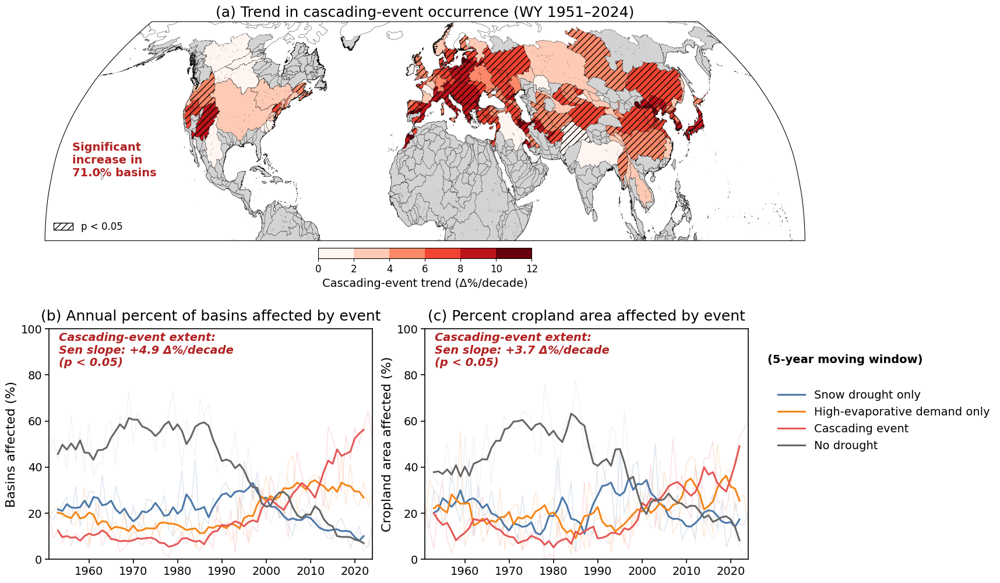

In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import cartopy.crs as ccrs

from scipy.stats import theilslopes, kendalltau


# ============================================================
# Helper function for Sen trend annotation
# Used for panels (b) and (c), NOT the basin-level map
# ============================================================

def sen_trend_text(da, unit_label):

    x = da.wy.values.astype(float)
    y = da.values.astype(float)

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    # Convert annual slope to decadal slope
    trend_decade = sen_slope * 10

    sign = "+" if trend_decade > 0 else ""

    if p < 0.05:
        p_text = "p < 0.05"
    else:
        p_text = f"p = {p:.3f}"

    text = (
        "Cascading-event extent:\n"
        f"Sen slope: {sign}{trend_decade:.1f} "
        f"{unit_label}/decade\n"
        f"({p_text})"
    )

    return text, trend_decade, p


# ============================================================
# Rolling means
# ============================================================

WINDOW = 5


# ------------------------------------------------------------
# Basin percentages
# ------------------------------------------------------------

rolling_compound = compound_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_snow = snow_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_demand = demand_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_normal = normal_pct.rolling(
    wy=WINDOW,
    center=True
).mean()


# ------------------------------------------------------------
# Cropland percentages
# ------------------------------------------------------------

rolling_compound_crop_pct = compound_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_snow_crop_pct = snow_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_demand_crop_pct = demand_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()

rolling_normal_crop_pct = normal_crop_pct.rolling(
    wy=WINDOW,
    center=True
).mean()


# ============================================================
# Trend annotations for panels (b) and (c)
#
# These are trends in annual aggregate percentages.
# They are calculated using Theil-Sen + Kendall tau.
# ============================================================

basin_pct_text, basin_pct_trend, basin_pct_p = sen_trend_text(
    compound_pct,
    "Δ%"
)

crop_pct_text, crop_pct_trend, crop_pct_p = sen_trend_text(
    compound_crop_pct,
    "Δ%"
)


# ============================================================
# Prepare full 602-basin map with aligned 169-basin
# LOGISTIC trend results
# ============================================================

basins_diss_plot = basins_diss.copy()


# Remove any old or misaligned trend columns
basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "compound_trend_pct_decade",
        "p_trend",
        "sig_trend"
    ],
    errors="ignore"
)


# ------------------------------------------------------------
# Join trend results from the 169 analysis basins
#
# compound_trend_pct_decade:
#   Mean marginal probability trend derived from the
#   basin-level logistic model, expressed as Δ%/decade.
#
# p_trend:
#   p-value for the logistic time coefficient beta1.
#
# sig_trend:
#   True when p_trend < 0.05.
# ------------------------------------------------------------

basins_diss_plot = basins_diss_plot.merge(
    basins_diss_169[
        [
            "MAIN_BAS",
            "compound_trend_pct_decade",
            "p_trend",
            "sig_trend"
        ]
    ],
    on="MAIN_BAS",
    how="left"
)


# ============================================================
# Significant increasing basins
# ============================================================

valid_map_trend = (
    basins_diss_169["compound_trend_pct_decade"].notna()
    &
    basins_diss_169["p_trend"].notna()
)


sig_increase = (
    valid_map_trend
    &
    (basins_diss_169["p_trend"] < 0.05)
    &
    (basins_diss_169["compound_trend_pct_decade"] > 0)
)


n_valid = int(
    valid_map_trend.sum()
)

n_sig_increase = int(
    sig_increase.sum()
)


pct_sig_increase = (
    100 * n_sig_increase / n_valid
    if n_valid > 0
    else np.nan
)


print(
    "Valid basins:",
    n_valid
)

print(
    "Significantly increasing basins:",
    n_sig_increase
)

print(
    "% significantly increasing:",
    round(pct_sig_increase, 1)
)


# ============================================================
# Plot settings
# ============================================================

colors = {
    "snow": "#4C78A8",
    "demand": "#F58518",
    "compound": "#E45756",
    "normal": "0.4"
}

annual_alpha = 0.20
annual_lw = 1.0
rolling_lw = 2.2

title_fs = 18
label_fs = 16
tick_fs = 14
legend_fs = 14
annotation_fs = 14


# ============================================================
# Figure layout
# ============================================================

fig = plt.figure(
    figsize=(15, 11)
)


# Top map
ax_a = fig.add_axes(
    [0.04, 0.55, 0.92, 0.37],
    projection=ccrs.Robinson()
)


# Bottom panels
ax_b = fig.add_axes(
    [0.07, 0.08, 0.37, 0.36]
)

ax_c = fig.add_axes(
    [0.50, 0.08, 0.37, 0.36]
)


# Shared legend axis
leg_ax = fig.add_axes(
    [0.88, 0.18, 0.12, 0.22]
)

leg_ax.axis("off")


# ============================================================
# (a) Trend map
# ============================================================

# Keep your current bins unchanged.
#
# These values represent the mean marginal probability
# trend from the logistic model in Δ%/decade.
bins = [
    0, 2, 4, 6, 8, 10, 12
]


# Keep your current color scheme unchanged
cmap = plt.get_cmap(
    "Reds",
    len(bins) - 1
)


norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)


# ------------------------------------------------------------
# Plot basin-level logistic marginal trends
# ------------------------------------------------------------

basins_diss_plot.plot(
    column="compound_trend_pct_decade",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),

    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },

    ax=ax_a
)


# ============================================================
# Hatching for significant logistic trends
# ============================================================

# sig_trend is based on the p-value for beta1
# from the basin-level logistic regression.

sig_mask = basins_diss_plot[
    "sig_trend"
].map(
    lambda value:
        bool(value)
        if pd.notna(value)
        else False
)


basins_diss_plot.loc[
    sig_mask
].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)


# ============================================================
# Colorbar
# ============================================================

# Use scalar_map instead of sm so it does not conflict
# with statsmodels aliases used elsewhere.
scalar_map = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

scalar_map.set_array([])


cbar = plt.colorbar(
    scalar_map,
    ax=ax_a,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.045,
    spacing="proportional"
)


cbar.set_label(
    "Cascading-event trend "
    "(Δ%/decade)",
    fontsize=14
)


cbar.ax.tick_params(
    labelsize=12
)


# ============================================================
# Significance legend
# ============================================================

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)


ax_a.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)


# ============================================================
# Significant increasing basin annotation
# ============================================================

ax_a.text(
    -170,
    20,

    f"Significant \n"
    f"increase in \n"
    f"{pct_sig_increase:.1f}% basins",

    color="#B22222",
    fontsize=14,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


# ============================================================
# Map title / extent / coastlines
# ============================================================

ax_a.set_title(
    "(a) Trend in cascading-event occurrence "
    "(WY 1951–2024)",
    fontsize=18,
    loc="center"
)


ax_a.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)


ax_a.coastlines(
    linewidth=0.3
)


# ============================================================
# (b) Annual extent across basins
#
# This panel uses annual aggregate percentages,
# NOT basin-level binary logistic regression.
# ============================================================


# ------------------------------------------------------------
# Annual thin lines
# ------------------------------------------------------------

ax_b.plot(
    compound_169.wy,
    snow_pct,
    color=colors["snow"],
    alpha=annual_alpha,
    linewidth=annual_lw
)


ax_b.plot(
    compound_169.wy,
    demand_pct,
    color=colors["demand"],
    alpha=annual_alpha,
    linewidth=annual_lw
)


ax_b.plot(
    compound_169.wy,
    compound_pct,
    color=colors["compound"],
    alpha=annual_alpha,
    linewidth=annual_lw
)


ax_b.plot(
    compound_169.wy,
    normal_pct,
    color="0.75",
    alpha=annual_alpha,
    linewidth=annual_lw
)


# ------------------------------------------------------------
# 5-year centered moving averages
# ------------------------------------------------------------

ax_b.plot(
    rolling_snow.wy,
    rolling_snow,
    color=colors["snow"],
    linewidth=rolling_lw
)


ax_b.plot(
    rolling_demand.wy,
    rolling_demand,
    color=colors["demand"],
    linewidth=rolling_lw
)


ax_b.plot(
    rolling_compound.wy,
    rolling_compound,
    color=colors["compound"],
    linewidth=rolling_lw
)


ax_b.plot(
    rolling_normal.wy,
    rolling_normal,
    color=colors["normal"],
    linewidth=rolling_lw
)


# ------------------------------------------------------------
# Panel formatting
# ------------------------------------------------------------

ax_b.set_title(
    "(b) Annual percent of basins affected by event",
    fontsize=title_fs,
    loc="center",
    pad=10
)


ax_b.set_ylabel(
    "Basins affected (%)",
    fontsize=label_fs
)


ax_b.set_ylim(
    0,
    100
)


ax_b.set_xlim(
    1951,
    2024
)


ax_b.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)


# ------------------------------------------------------------
# Trend annotation
#
# This comes from Theil-Sen + Kendall tau applied to
# the annual percentage of basins affected.
# ------------------------------------------------------------

ax_b.text(
    0.03,
    0.985,
    basin_pct_text,
    transform=ax_b.transAxes,
    color="#B22222",
    fontsize=annotation_fs,
    fontweight="bold",
    fontstyle="italic",
    ha="left",
    va="top",
    linespacing=1.15
)


# ============================================================
# (c) Percent cropland area affected
#
# This also uses annual aggregate percentages,
# not basin-level logistic regression.
# ============================================================


# ------------------------------------------------------------
# Annual thin lines
# ------------------------------------------------------------

ax_c.plot(
    compound_crop_pct.wy,
    snow_crop_pct,
    color=colors["snow"],
    alpha=annual_alpha,
    linewidth=annual_lw
)


ax_c.plot(
    compound_crop_pct.wy,
    demand_crop_pct,
    color=colors["demand"],
    alpha=annual_alpha,
    linewidth=annual_lw
)


ax_c.plot(
    compound_crop_pct.wy,
    compound_crop_pct,
    color=colors["compound"],
    alpha=annual_alpha,
    linewidth=annual_lw
)


ax_c.plot(
    compound_crop_pct.wy,
    normal_crop_pct,
    color="0.75",
    alpha=annual_alpha,
    linewidth=annual_lw
)


# ------------------------------------------------------------
# 5-year centered moving averages
# ------------------------------------------------------------

ax_c.plot(
    rolling_snow_crop_pct.wy,
    rolling_snow_crop_pct,
    color=colors["snow"],
    linewidth=rolling_lw
)


ax_c.plot(
    rolling_demand_crop_pct.wy,
    rolling_demand_crop_pct,
    color=colors["demand"],
    linewidth=rolling_lw
)


ax_c.plot(
    rolling_compound_crop_pct.wy,
    rolling_compound_crop_pct,
    color=colors["compound"],
    linewidth=rolling_lw
)


ax_c.plot(
    rolling_normal_crop_pct.wy,
    rolling_normal_crop_pct,
    color=colors["normal"],
    linewidth=rolling_lw
)


# ------------------------------------------------------------
# Panel formatting
# ------------------------------------------------------------

ax_c.set_title(
    "(c) Percent cropland area affected by event",
    fontsize=title_fs,
    loc="center",
    pad=10
)


ax_c.set_ylabel(
    "Cropland area affected (%)",
    fontsize=label_fs
)


ax_c.set_ylim(
    0,
    100
)


ax_c.set_xlim(
    1951,
    2024
)


ax_c.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)


# ------------------------------------------------------------
# Trend annotation
#
# Theil-Sen + Kendall tau applied to the annual
# percentage of cropland area affected.
# ------------------------------------------------------------

ax_c.text(
    0.03,
    0.985,
    crop_pct_text,
    transform=ax_c.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)


# ============================================================
# Shared legend for panels (b) and (c)
# ============================================================

legend_handles = [

    Line2D(
        [0], [0],
        color=colors["snow"],
        linewidth=rolling_lw,
        label="Snow drought only"
    ),

    Line2D(
        [0], [0],
        color=colors["demand"],
        linewidth=rolling_lw,
        label="High-evaporative demand only"
    ),

    Line2D(
        [0], [0],
        color=colors["compound"],
        linewidth=rolling_lw,
        label="Cascading event"
    ),

    Line2D(
        [0], [0],
        color=colors["normal"],
        linewidth=rolling_lw,
        label="No drought"
    )
]


leg_ax.text(
    0.10,
    1.00,
    f"({WINDOW}-year moving window)",
    fontsize=legend_fs,
    fontweight="bold",
    ha="left",
    va="top"
)


leg_ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.10, 0.82),
    frameon=False,
    fontsize=legend_fs,
    handlelength=2.4
)


# ============================================================
# Final formatting
# ============================================================

for ax in [
    ax_b,
    ax_c
]:

    for side in [
        "top",
        "bottom",
        "left",
        "right"
    ]:

        ax.spines[
            side
        ].set_visible(True)

        ax.spines[
            side
        ].set_color("black")

        ax.spines[
            side
        ].set_linewidth(1.2)


# ============================================================
# Save
# ============================================================

plt.savefig(
    "Fig_2.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)


plt.show()

Valid basins: 169
Significantly increasing basins: 120
% significantly increasing: 71.0


/tmp/ipykernel_1915107/1156748350.py:344: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


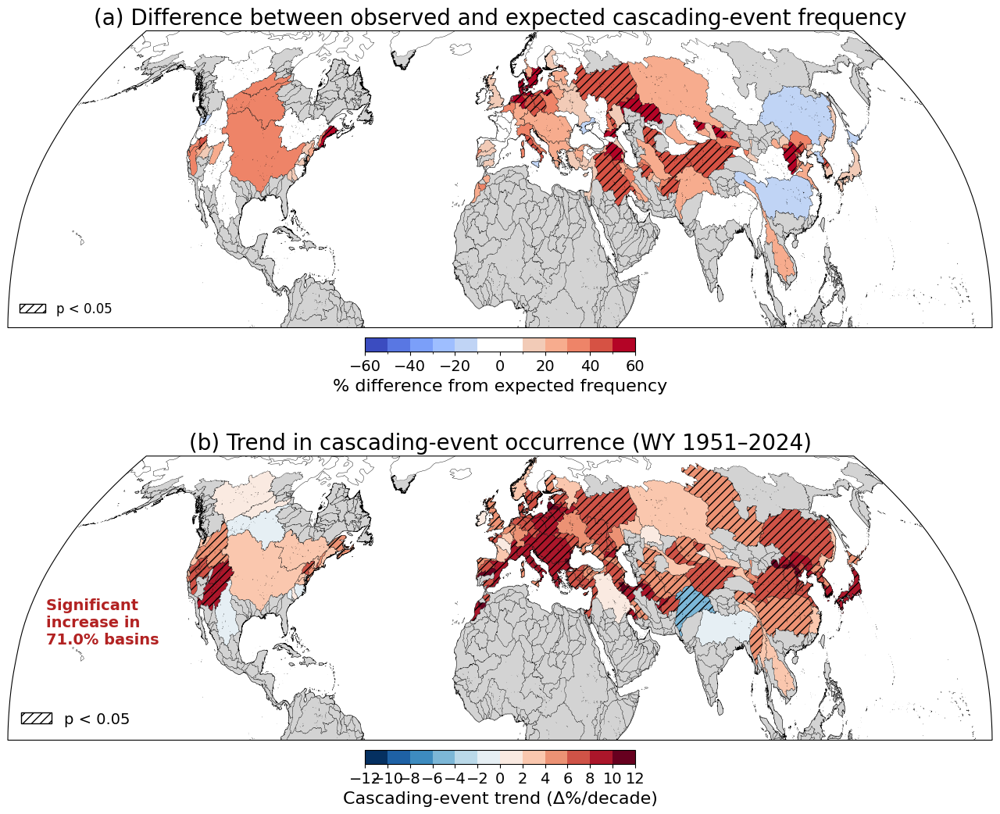

In [159]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import numpy as np


# ============================================================
# Prepare trend GeoDataFrame
# ============================================================

basins_diss_plot = basins_diss.copy()

cols = [
    "MAIN_BAS",
    "compound_trend_pct_decade",
    "p_trend",
    "sig_trend"
]

# Remove old versions if already present
basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "compound_trend_pct_decade",
        "p_trend",
        "sig_trend"
    ],
    errors="ignore"
)

# Join the 169-basin trend results back to all basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_169[cols],
    on="MAIN_BAS",
    how="left"
)


# ============================================================
# Significant increasing basin summary
# ============================================================

valid_trend = (
    basins_diss_169[
        "compound_trend_pct_decade"
    ].notna()
    &
    basins_diss_169[
        "p_trend"
    ].notna()
)

sig_increase = (
    valid_trend
    &
    (
        basins_diss_169[
            "p_trend"
        ] < 0.05
    )
    &
    (
        basins_diss_169[
            "compound_trend_pct_decade"
        ] > 0
    )
)

n_valid = int(
    valid_trend.sum()
)

n_sig_increase = int(
    sig_increase.sum()
)

pct_sig_increase = (
    100 * n_sig_increase / n_valid
    if n_valid > 0
    else np.nan
)

print(
    "Valid basins:",
    n_valid
)

print(
    "Significantly increasing basins:",
    n_sig_increase
)

print(
    "% significantly increasing:",
    round(
        pct_sig_increase,
        1
    )
)


# ============================================================
# Figure layout
# ============================================================

fig = plt.figure(
    figsize=(14, 12)
)

ax_a = fig.add_axes(
    [0.05, 0.54, 0.90, 0.36],
    projection=ccrs.Robinson()
)

ax_b = fig.add_axes(
    [0.05, 0.10, 0.90, 0.36],
    projection=ccrs.Robinson()
)


# ============================================================
# (a) Difference between observed and expected frequency
# ============================================================

bounds = np.array(
    [
        -60, -50, -40, -30, -20, -10,
         10,  20,  30,  40,  50,  60
    ]
)

base = plt.get_cmap(
    "coolwarm"
)

cmap_colors = base(
    np.linspace(
        0,
        1,
        len(bounds) - 1
    )
)

# White center bin: -10 to +10
center_idx = list(
    bounds[:-1]
).index(-10)

cmap_colors[
    center_idx
] = [
    1,
    1,
    1,
    1
]

disc_cmap = mcolors.ListedColormap(
    cmap_colors
)

disc_norm = mcolors.BoundaryNorm(
    boundaries=bounds,
    ncolors=disc_cmap.N,
    clip=True
)


# ------------------------------------------------------------
# Base map
# ------------------------------------------------------------

basins_diss.plot(
    column="compound_pct_diff",
    cmap=disc_cmap,
    norm=disc_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray"
    },
    ax=ax_a
)


# ------------------------------------------------------------
# Fisher significance hatching
# ------------------------------------------------------------

sig_fisher = (
    basins_diss[
        "p_fisher"
    ].notna()
    &
    (
        basins_diss[
            "p_fisher"
        ] < 0.05
    )
)

basins_diss.loc[
    sig_fisher
].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)


# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

sm_a = cm.ScalarMappable(
    norm=disc_norm,
    cmap=disc_cmap
)

sm_a.set_array([])

cbar_a = plt.colorbar(
    sm_a,
    ax=ax_a,
    orientation="horizontal",
    boundaries=bounds,
    ticks=np.arange(
        -60,
        61,
        20
    ),
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar_a.set_label(
    "% difference from expected frequency",
    fontsize=16
)

cbar_a.ax.tick_params(
    labelsize=14
)


# ------------------------------------------------------------
# Fisher significance legend
# ------------------------------------------------------------

hatch_patch_a = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax_a.legend(
    handles=[
        hatch_patch_a
    ],
    loc="lower left",
    frameon=False,
    fontsize=12
)


# ------------------------------------------------------------
# Panel formatting
# ------------------------------------------------------------

ax_a.set_title(
    "(a) Difference between observed and expected "
    "cascading-event frequency",
    fontsize=20
)

ax_a.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)

ax_a.coastlines(
    linewidth=0.3
)


# ============================================================
# (b) Trend in cascading-event occurrence
# ============================================================

bins = np.array(
    [
        -12, -10, -8, -6, -4, -2,
          0,
          2,   4,  6,  8, 10, 12
    ]
)

trend_cmap = plt.get_cmap(
    "RdBu_r",
    len(bins) - 1
)

trend_norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=trend_cmap.N,
    clip=True
)


# ------------------------------------------------------------
# Base trend map
# ------------------------------------------------------------

basins_diss_plot.plot(
    column="compound_trend_pct_decade",
    cmap=trend_cmap,
    norm=trend_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax_b
)


# ------------------------------------------------------------
# Hatching for significant basin-level logistic trends
# ------------------------------------------------------------

sig_mask = (
    basins_diss_plot[
        "sig_trend"
    ]
    .fillna(False)
    .astype(bool)
)

basins_diss_plot.loc[
    sig_mask
].plot(
    ax=ax_b,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)


# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------

sm_b = cm.ScalarMappable(
    cmap=trend_cmap,
    norm=trend_norm
)

sm_b.set_array([])

# fig.canvas.draw()
# pos_b = ax_b.get_position()

# cax_b = fig.add_axes([
#     pos_b.x0 - 0.06,
#     pos_b.y0 - 0.055,
#     pos_b.width + 0.12,
#     0.018
# ])

# cbar_b = fig.colorbar(
#     sm_b,
#     cax=cax_b,
#     orientation="horizontal",
#     boundaries=bins,
#     ticks=bins,
#     spacing="proportional"
# )

cbar_b = plt.colorbar(
    sm_b,
    ax=ax_b,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar_b.set_label(
    "Cascading-event trend (Δ%/decade)",
    fontsize=16
)

cbar_b.ax.tick_params(
    labelsize=14
)


# ------------------------------------------------------------
# Significance legend
# ------------------------------------------------------------

hatch_patch_b = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax_b.legend(
    handles=[
        hatch_patch_b
    ],
    loc="lower left",
    frameon=False,
    fontsize=14
)


# ------------------------------------------------------------
# Significant increasing basin annotation
# ------------------------------------------------------------

ax_b.text(
    -170,
    23,
    (
        "Significant \nincrease in\n"
        f"{pct_sig_increase:.1f}% basins"
    ),
    color="#B22222",
    fontsize=14,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


# ------------------------------------------------------------
# Panel formatting
# ------------------------------------------------------------

ax_b.set_title(
    "(b) Trend in cascading-event occurrence "
    "(WY 1951–2024)",
    fontsize=20
)

ax_b.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)

ax_b.coastlines(
    linewidth=0.3
)


# ============================================================
# Save
# ============================================================

plt.savefig(
    "Fig_S16.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

plt.show()

In [158]:
abc

NameError: name 'abc' is not defined

In [ ]:
WINDOW = 5

# Sum the 0/1 event masks across the 169 analysis basins
# Result: one basin count for each water year
compound_ts  = compound_169.sum("region")
snow_ts      = snow_169.sum("region")
demand_ts    = demand_169.sum("region")
nodrought_ts = normal_169.sum("region")

# 5-year centered moving averages
# These represent the mean annual number of basins affected
# within each 5-year centered window.

rolling_compound_n = compound_ts.rolling(wy=WINDOW, center=True).mean()
rolling_snow_n = snow_ts.rolling(wy=WINDOW, center=True).mean()
rolling_demand_n = demand_ts.rolling(wy=WINDOW, center=True).mean()
rolling_normal_n = nodrought_ts.rolling(wy=WINDOW, center=True).mean()

In [ ]:
# ============================================================
# Prepare full 602-basin GeoDataFrame
# with logistic trend results from the 169 analysis basins
# ============================================================

basins_diss_plot = basins_diss.copy()

trend_cols = [
    "snow_trend",
    "snow_p",
    "demand_trend",
    "demand_p",
    "normal_trend",
    "normal_p"
]

# Remove old or potentially misaligned trend columns
basins_diss_plot = basins_diss_plot.drop(
    columns=trend_cols,
    errors="ignore"
)

# Join correctly aligned logistic-regression results
#
# snow_trend / demand_trend / normal_trend:
#   Mean marginal probability trend from the basin-level
#   logistic model, expressed as Δ%/decade.
#
# snow_p / demand_p / normal_p:
#   p-value for the logistic time coefficient beta1.
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_169[
        ["MAIN_BAS"] + trend_cols
    ],
    on="MAIN_BAS",
    how="left"
)


# ============================================================
# Calculate significant trend percentages
# ============================================================

def significant_trend_stats(
    gdf,
    trend_col,
    p_col,
    alpha=0.05
):
    """
    Calculate the percentage of valid basins with significant
    increasing and decreasing logistic trends.
    """

    # Valid trend estimates
    valid = (
        gdf[trend_col].notna()
        &
        gdf[p_col].notna()
    )

    # Significant logistic time trends
    sig = (
        valid
        &
        (gdf[p_col] < alpha)
    )

    # Significant increasing trends
    increasing = (
        sig
        &
        (gdf[trend_col] > 0)
    )

    # Significant decreasing trends
    decreasing = (
        sig
        &
        (gdf[trend_col] < 0)
    )

    n_valid = int(
        valid.sum()
    )

    n_increasing = int(
        increasing.sum()
    )

    n_decreasing = int(
        decreasing.sum()
    )

    pct_increasing = (
        100 * n_increasing / n_valid
        if n_valid > 0
        else np.nan
    )

    pct_decreasing = (
        100 * n_decreasing / n_valid
        if n_valid > 0
        else np.nan
    )

    return (
        pct_increasing,
        pct_decreasing
    )


# ------------------------------------------------------------
# Snow-drought-only trends
# ------------------------------------------------------------

snow_pct_increase, snow_pct_decrease = significant_trend_stats(
    basins_diss_169,
    "snow_trend",
    "snow_p"
)


# ------------------------------------------------------------
# High-evaporative-demand-only trends
# ------------------------------------------------------------

demand_pct_increase, demand_pct_decrease = significant_trend_stats(
    basins_diss_169,
    "demand_trend",
    "demand_p"
)


# ------------------------------------------------------------
# No-drought trends
# ------------------------------------------------------------

normal_pct_increase, normal_pct_decrease = significant_trend_stats(
    basins_diss_169,
    "normal_trend",
    "normal_p"
)


# ============================================================
# Print summary statistics
# ============================================================

print(
    "Snow drought only:"
)

print(
    f"Significant increase: "
    f"{snow_pct_increase:.1f}%"
)

print(
    f"Significant decrease: "
    f"{snow_pct_decrease:.1f}%"
)


print(
    "\nHigh-evaporative demand only:"
)

print(
    f"Significant increase: "
    f"{demand_pct_increase:.1f}%"
)

print(
    f"Significant decrease: "
    f"{demand_pct_decrease:.1f}%"
)


print(
    "\nNo drought:"
)

print(
    f"Significant increase: "
    f"{normal_pct_increase:.1f}%"
)

print(
    f"Significant decrease: "
    f"{normal_pct_decrease:.1f}%"
)


# ============================================================
# Layout
# ============================================================

fig = plt.figure(
    figsize=(16, 12)
)


# ------------------------------------------------------------
# Panel (a): snow-drought-only map
# ------------------------------------------------------------

ax_a = fig.add_axes(
    [0.05, 0.62, 0.62, 0.30],
    projection=ccrs.Robinson()
)


# ------------------------------------------------------------
# Panel (b): high-demand-only map
# ------------------------------------------------------------

ax_b = fig.add_axes(
    [0.05, 0.27, 0.62, 0.30],
    projection=ccrs.Robinson()
)


# ============================================================
# (a) Snow-drought-only trend map
# ============================================================

# Discrete bins for snow-drought-only trends
#
# snow_trend is the mean marginal probability trend from
# logistic regression, expressed as Δ%/decade.
snow_bins = [
    0,
    2,
    4,
    6,
    8
]


# Keep existing color scheme
snow_cmap = plt.get_cmap(
    "Blues",
    len(snow_bins) - 1
)


snow_norm = mcolors.BoundaryNorm(
    boundaries=snow_bins,
    ncolors=snow_cmap.N,
    clip=True
)


# ------------------------------------------------------------
# Plot snow-drought-only logistic marginal trends
# ------------------------------------------------------------

basins_diss_plot.plot(
    column="snow_trend",
    cmap=snow_cmap,
    norm=snow_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),

    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },

    ax=ax_a
)


# ============================================================
# Significant snow-drought-only trends
#
# Significance is based on the p-value for beta1
# from the logistic regression.
# ============================================================

snow_sig_mask = (
    basins_diss_plot["snow_p"]
    .map(
        lambda value:
            bool(value < 0.05)
            if pd.notna(value)
            else False
    )
)


basins_diss_plot.loc[
    snow_sig_mask
].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)


# ============================================================
# Snow trend colorbar
# ============================================================

scalar_map_a = cm.ScalarMappable(
    cmap=snow_cmap,
    norm=snow_norm
)

scalar_map_a.set_array([])


cbar_a = plt.colorbar(
    scalar_map_a,
    ax=ax_a,
    orientation="horizontal",
    boundaries=snow_bins,
    ticks=snow_bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)


cbar_a.set_label(
    "Snow-drought-only trend "
    "(Δ%/decade)",
    fontsize=12
)


cbar_a.ax.tick_params(
    labelsize=12
)


# ============================================================
# Significance legend
# ============================================================

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)


ax_a.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)


# ============================================================
# Snow significant-increase annotation
# ============================================================

ax_a.text(
    -170,
    25,
    f"Significant \n"
    f"increase in\n"
    f"{snow_pct_increase:.1f}% basins",
    color="#1F77B4",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


# ============================================================
# Snow map formatting
# ============================================================

ax_a.set_title(
    "(a) Trend in snow-drought-only occurrence "
    "(WY 1951–2024)",
    fontsize=15
)


ax_a.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)


ax_a.coastlines(
    linewidth=0.3
)


# ============================================================
# (b) High-evaporative-demand-only trend map
# ============================================================

# Diverging bins for positive and negative demand-only trends
#
# demand_trend is the mean marginal probability trend from
# logistic regression, expressed as Δ%/decade.
demand_bins = [
    -6,
    -4,
    -2,
    0,
    2,
    4,
    6
]


# Keep existing color scheme
demand_cmap = plt.get_cmap(
    "BrBG_r",
    len(demand_bins) - 1
)


demand_norm = mcolors.BoundaryNorm(
    boundaries=demand_bins,
    ncolors=demand_cmap.N,
    clip=True
)


# ------------------------------------------------------------
# Plot high-demand-only logistic marginal trends
# ------------------------------------------------------------

basins_diss_plot.plot(
    column="demand_trend",
    cmap=demand_cmap,
    norm=demand_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),

    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },

    ax=ax_b
)


# ============================================================
# Significant high-demand-only trends
#
# Significance is based on the p-value for beta1
# from the logistic regression.
# ============================================================

demand_sig_mask = (
    basins_diss_plot["demand_p"]
    .map(
        lambda value:
            bool(value < 0.05)
            if pd.notna(value)
            else False
    )
)


basins_diss_plot.loc[
    demand_sig_mask
].plot(
    ax=ax_b,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)


# ============================================================
# Demand trend colorbar
# ============================================================

scalar_map_b = cm.ScalarMappable(
    cmap=demand_cmap,
    norm=demand_norm
)

scalar_map_b.set_array([])


cbar_b = plt.colorbar(
    scalar_map_b,
    ax=ax_b,
    orientation="horizontal",
    boundaries=demand_bins,
    ticks=demand_bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)


cbar_b.set_label(
    "High-evaporative demand-only trend "
    "(Δ%/decade)",
    fontsize=12
)


cbar_b.ax.tick_params(
    labelsize=12
)


# ============================================================
# Significance legend
# ============================================================

ax_b.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)


# ============================================================
# Demand significant-trend annotation
# ============================================================

x = -172
y = 30
dy = 6


ax_b.text(
    x,
    y,
    "Significant",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


ax_b.text(
    x,
    y - 0.8 * dy,
    "increase",
    color="#A67C2D",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


ax_b.text(
    x + 34,
    y - 0.8 * dy,
    "in",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


ax_b.text(
    x,
    y - 1.6 * dy,
    f"{demand_pct_increase:.1f}% of basins",
    color="#A67C2D",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


ax_b.text(
    x,
    y - 2.3 * dy,
    "and",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


ax_b.text(
    x + 15,
    y - 2.3 * dy,
    "decrease",
    color="#2E6B2E",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


ax_b.text(
    x,
    y - 3 * dy,
    "in",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


ax_b.text(
    x + 10,
    y - 3 * dy,
    f"{demand_pct_decrease:.1f}% of basins",
    color="#2E6B2E",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)


# ============================================================
# Demand map formatting
# ============================================================

ax_b.set_title(
    "(b) Trend in high-evaporative-demand-only occurrence "
    "(WY 1951–2024)",
    fontsize=15
)


ax_b.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)


ax_b.coastlines(
    linewidth=0.3
)


# ============================================================
# No-drought annotation
#
# normal_trend is also based on the logistic model.
# This reports the percentage of valid basins with a
# significant decreasing no-drought occurrence trend.
# ============================================================

fig.text(
    0.36,
    0.20,
    f"No-drought occurrence significantly decreased in "
    f"{normal_pct_decrease:.1f}% of basins.",
    color="0.35",
    fontsize=16,
    fontweight="bold",
    ha="center"
)


# ============================================================
# Save
# ============================================================

plt.savefig(
    "Fig_S6.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)


plt.show()

In [ ]:
# ============================================================
# Helper function for Sen trend annotation
# ============================================================

def sen_trend_text(da, unit_label):
    x = da["wy"].values.astype(float)
    y = da.values.astype(float)

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    # Convert annual trend to decadal trend
    trend_decade = sen_slope * 10
    lower_decade = lower * 10
    upper_decade = upper * 10

    sign = "+" if trend_decade > 0 else ""

    if p < 0.05:
        p_text = "p < 0.05"
    else:
        p_text = f"p = {p:.3f}"

    text = (
        "Cascading-event extent:\n"
        f"Sen slope: {sign}{trend_decade:.2f} {unit_label}/decade\n"
        f"95% CI: {lower_decade:.2f}–{upper_decade:.2f}\n"
        f"({p_text})"
    )

    return text, trend_decade, p


# ============================================================
# Convert absolute cropland area from km² to million hectares
# ============================================================

compound_crop_area_mha = compound_crop_area_km2 / 1e4
snow_crop_area_mha     = snow_crop_area_km2 / 1e4
demand_crop_area_mha   = demand_crop_area_km2 / 1e4
normal_crop_area_mha   = normal_crop_area_km2 / 1e4


# ============================================================
# Rolling means
# ============================================================

WINDOW = 5

# Number of basins
rolling_snow_n = (
    snow_ts
    .rolling(wy=WINDOW, center=True)
    .mean()
)

rolling_demand_n = (
    demand_ts
    .rolling(wy=WINDOW, center=True)
    .mean()
)

rolling_compound_n = (
    compound_ts
    .rolling(wy=WINDOW, center=True)
    .mean()
)

rolling_normal_n = (
    nodrought_ts
    .rolling(wy=WINDOW, center=True)
    .mean()
)


# Cropland area
rolling_snow_area = (
    snow_crop_area_mha
    .rolling(wy=WINDOW, center=True)
    .mean()
)

rolling_demand_area = (
    demand_crop_area_mha
    .rolling(wy=WINDOW, center=True)
    .mean()
)

rolling_compound_area = (
    compound_crop_area_mha
    .rolling(wy=WINDOW, center=True)
    .mean()
)

rolling_normal_area = (
    normal_crop_area_mha
    .rolling(wy=WINDOW, center=True)
    .mean()
)


# ============================================================
# Trend annotations
# ============================================================

basin_text, basin_trend, basin_p = sen_trend_text(
    compound_ts,
    "basins"
)

area_text, area_trend, area_p = sen_trend_text(
    compound_crop_area_mha,
    "million ha"
)


# ============================================================
# Plot settings
# ============================================================

colors = {
    "snow": "#4C78A8",
    "demand": "#F58518",
    "compound": "#E45756",
    "normal": "0.4"
}

annual_alpha = 0.18
annual_lw = 1.0
rolling_lw = 2.4

title_fs = 18
label_fs = 18
tick_fs = 16
legend_fs = 16
annotation_fs = 14


# ============================================================
# Figure layout: panel (a), panel (b), shared legend
# ============================================================

fig = plt.figure(figsize=(18, 7.5))

gs = fig.add_gridspec(
    nrows=1,
    ncols=3,
    width_ratios=[1.45, 1.45, 0.40],
    wspace=0.37
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
leg_ax = fig.add_subplot(gs[0, 2])

leg_ax.axis("off")

ax1.set_box_aspect(1)
ax2.set_box_aspect(1)


# ============================================================
# Panel (a): Annual extent across basins
# ============================================================

# Annual thin lines
ax1.plot(
    compound_169.wy,
    snow_ts,
    color=colors["snow"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax1.plot(
    compound_169.wy,
    demand_ts,
    color=colors["demand"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax1.plot(
    compound_169.wy,
    compound_ts,
    color=colors["compound"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax1.plot(
    compound_169.wy,
    nodrought_ts,
    color="0.75",
    alpha=annual_alpha,
    linewidth=annual_lw
)


# 5-year rolling means
ax1.plot(
    rolling_snow_n.wy,
    rolling_snow_n,
    color=colors["snow"],
    linewidth=rolling_lw
)

ax1.plot(
    rolling_demand_n.wy,
    rolling_demand_n,
    color=colors["demand"],
    linewidth=rolling_lw
)

ax1.plot(
    rolling_compound_n.wy,
    rolling_compound_n,
    color=colors["compound"],
    linewidth=rolling_lw
)

ax1.plot(
    rolling_normal_n.wy,
    rolling_normal_n,
    color=colors["normal"],
    linewidth=rolling_lw
)


ax1.set_title(
    "(a) Annual extent of basins affected by \nevent class",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax1.set_ylabel(
    "Number of basins",
    fontsize=label_fs
)

ax1.set_xlim(
    1951,
    2024
)

ax1.set_ylim(
    0,
    180
)

ax1.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)


ax1.text(
    0.03,
    0.985,
    basin_text,
    transform=ax1.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)


# ============================================================
# Panel (b): Cropland area affected
# ============================================================

# Annual thin lines
ax2.plot(
    compound_crop_area_mha.wy,
    snow_crop_area_mha,
    color=colors["snow"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax2.plot(
    compound_crop_area_mha.wy,
    demand_crop_area_mha,
    color=colors["demand"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax2.plot(
    compound_crop_area_mha.wy,
    compound_crop_area_mha,
    color=colors["compound"],
    alpha=annual_alpha,
    linewidth=annual_lw
)

ax2.plot(
    compound_crop_area_mha.wy,
    normal_crop_area_mha,
    color="0.75",
    alpha=annual_alpha,
    linewidth=annual_lw
)


# 5-year rolling means
ax2.plot(
    rolling_snow_area.wy,
    rolling_snow_area,
    color=colors["snow"],
    linewidth=rolling_lw
)

ax2.plot(
    rolling_demand_area.wy,
    rolling_demand_area,
    color=colors["demand"],
    linewidth=rolling_lw
)

ax2.plot(
    rolling_compound_area.wy,
    rolling_compound_area,
    color=colors["compound"],
    linewidth=rolling_lw
)

ax2.plot(
    rolling_normal_area.wy,
    rolling_normal_area,
    color=colors["normal"],
    linewidth=rolling_lw
)


ax2.set_title(
    "(b) Cropland area affected by event class",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax2.set_ylabel(
    "Cropland area affected (million ha)",
    fontsize=label_fs
)

ax2.set_xlim(
    1951,
    2024
)

ax2.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)


ax2.text(
    0.03,
    0.985,
    area_text,
    transform=ax2.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)


# ============================================================
# Shared legend on the right
# ============================================================

legend_handles = [
    Line2D(
        [0], [0],
        color=colors["snow"],
        linewidth=rolling_lw,
        label="Snow drought only"
    ),
    Line2D(
        [0], [0],
        color=colors["demand"],
        linewidth=rolling_lw,
        label="High-evaporative demand only"
    ),
    Line2D(
        [0], [0],
        color=colors["compound"],
        linewidth=rolling_lw,
        label="Cascading event"
    ),
    Line2D(
        [0], [0],
        color=colors["normal"],
        linewidth=rolling_lw,
        label="No drought"
    )
]


leg_ax.text(
    -0.60,
    0.72,
    f"({WINDOW}-year moving window)",
    fontsize=legend_fs,
    fontweight="bold",
    ha="left",
    va="top"
)

leg_ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(-0.60, 0.64),
    frameon=False,
    fontsize=legend_fs,
    handlelength=2.4
)


# ============================================================
# Final formatting
# ============================================================

for ax in [ax1, ax2]:

    for side in [
        "top",
        "bottom",
        "left",
        "right"
    ]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.2)


plt.savefig(
    "Fig_S7.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

plt.show()

In [ ]:
# ============================================================
# Basins with at least one valid water year
# ============================================================

analysis_mask = valid_wy.any("wy")

print("Total regions:", analysis_mask.size)                  # 602
print("Number of analysis basins:", int(analysis_mask.sum()))  # 169

# ============================================================
# Positions of the 169 analysis basins
# ============================================================

analysis_pos = np.flatnonzero(analysis_mask.values)

# ============================================================
# Subset all drought-category arrays by position
# ============================================================

compound_169 = compound.isel(region=analysis_pos)
snow_169 = low_swe_only.isel(region=analysis_pos)
demand_169 = high_eto_only.isel(region=analysis_pos)
normal_169 = normal.isel(region=analysis_pos)

# ============================================================
# Check dimensions
# ============================================================

print("Cascading-event basins:", compound_169.sizes["region"])
print("Snow-drought-only basins:", snow_169.sizes["region"])
print("High-evaporative-demand-only basins:", demand_169.sizes["region"])
print("No-drought basins:", normal_169.sizes["region"])

In [ ]:
# ============================================================
# Identify the 169 analysis basins
# ============================================================

# Basins with at least one valid water year
analysis_mask = valid_wy.any("wy")

# Positions of the 169 valid analysis basins
analysis_pos = np.flatnonzero(
    analysis_mask.values
)

print(
    "Number of analysis basins:",
    len(analysis_pos)
)

# ============================================================
# Select matching basin geometries
# ============================================================

# basins_diss is already in the same positional order as
# the region dimension used by valid_wy.
basins_diss_169 = (
    basins_diss
    .iloc[analysis_pos]
    .copy()
    .reset_index(drop=True)
)

# Actual MAIN_BAS IDs in the correct positional order
selected_ids = (
    basins_diss_169["MAIN_BAS"]
    .to_numpy()
)

# ============================================================
# Subset drought-category arrays
# and assign actual MAIN_BAS IDs
# ============================================================

compound_169 = (
    compound
    .isel(region=analysis_pos)
    .assign_coords(
        region=selected_ids
    )
)

snow_169 = (
    low_swe_only
    .isel(region=analysis_pos)
    .assign_coords(
        region=selected_ids
    )
)

demand_169 = (
    high_eto_only
    .isel(region=analysis_pos)
    .assign_coords(
        region=selected_ids
    )
)

normal_169 = (
    normal
    .isel(region=analysis_pos)
    .assign_coords(
        region=selected_ids
    )
)

# ============================================================
# Verify dimensions
# ============================================================

assert len(analysis_pos) == compound_169.sizes["region"]
assert len(basins_diss_169) == compound_169.sizes["region"]

assert compound_169.sizes["region"] == compound_169.sizes["region"]
assert snow_169.sizes["region"] == compound_169.sizes["region"]
assert demand_169.sizes["region"] == compound_169.sizes["region"]
assert normal_169.sizes["region"] == compound_169.sizes["region"]

# ============================================================
# Verify basin IDs/order
# ============================================================

assert np.array_equal(
    compound_169["region"].values,
    snow_169["region"].values
)

assert np.array_equal(
    compound_169["region"].values,
    demand_169["region"].values
)

assert np.array_equal(
    compound_169["region"].values,
    normal_169["region"].values
)

# Confirm GeoDataFrame and xarray arrays are aligned
assert np.array_equal(
    basins_diss_169["MAIN_BAS"].to_numpy(),
    compound_169["region"].values
)

# Confirm all selected basins have geometries
assert basins_diss_169["geometry"].notna().all()

print("Alignment confirmed.")
print("Analysis basins:", len(basins_diss_169))

In [ ]:
# Split water years into two halves
years = compound_169.wy.values

mid_idx = len(years) // 2

first_half_years = years[:mid_idx + 1]      # 1951–1988 (37 years)
second_half_years = years[mid_idx + 1:]     # 1989–2024 (37 years)

first_start = int(first_half_years[0])
first_end   = int(first_half_years[-1])

second_start = int(second_half_years[0])
second_end   = int(second_half_years[-1])

print(f"Period 1: {first_start}–{first_end}")
print(f"Period 2: {second_start}–{second_end}")

In [ ]:
compound_1 = compound_169.sel(wy=slice(first_start, first_end))
compound_2 = compound_169.sel(wy=slice(second_start, second_end))

snow_1 = snow_169.sel(wy=slice(first_start, first_end))
snow_2 = snow_169.sel(wy=slice(second_start, second_end))

demand_1 = demand_169.sel(wy=slice(first_start, first_end))
demand_2 = demand_169.sel(wy=slice(second_start, second_end))

normal_1 = normal_169.sel(wy=slice(first_start, first_end))
normal_2 = normal_169.sel(wy=slice(second_start, second_end))

In [ ]:
# ============================================================
# Basin-level logistic trend
#
# Model:
#
# logit(P(event)) = beta0 + beta1 * time
#
# Trend is expressed as the mean marginal probability change
# in Δ%/decade.
# ============================================================

def basin_logistic_trend(da):

    years = da["wy"].values.astype(float)

    # Center time for numerical stability
    x = years - years.mean()

    n_region = da.sizes["region"]

    trends = np.full(
        n_region,
        np.nan
    )

    pvals = np.full(
        n_region,
        np.nan
    )

    for r in range(n_region):

        y = (
            da
            .isel(region=r)
            .values
            .astype(float)
        )

        valid = (
            np.isfinite(x)
            &
            np.isfinite(y)
        )

        x_valid = x[valid]
        y_valid = y[valid]

        if len(y_valid) < 2:
            continue

        # ----------------------------------------------------
        # Constant event series
        # ----------------------------------------------------

        if np.all(
            y_valid == y_valid[0]
        ):

            trends[r] = 0.0
            pvals[r] = 1.0

            continue

        # ----------------------------------------------------
        # Logistic regression
        # ----------------------------------------------------

        X = sm_stats.add_constant(
            x_valid
        )

        try:

            model = sm_stats.GLM(
                y_valid,
                X,
                family=sm_stats.families.Binomial()
            ).fit()

            beta1 = model.params[1]

            pvals[r] = model.pvalues[1]

            # -----------------------------------------------
            # Predicted probabilities
            # -----------------------------------------------

            p_hat = model.predict(
                X
            )

            # -----------------------------------------------
            # Mean marginal probability trend
            #
            # dp/dt = beta1 * p * (1 - p)
            #
            # Convert:
            # probability/year
            # -> percentage points/decade
            # -----------------------------------------------

            marginal_effect = (
                beta1
                * p_hat
                * (1 - p_hat)
            )

            trends[r] = (
                np.mean(
                    marginal_effect
                )
                * 10
                * 100
            )

        except Exception:

            trends[r] = np.nan
            pvals[r] = np.nan

    return trends, pvals


# ============================================================
# Calculate trends for the two equal periods
# ============================================================

event_classes = {
    "compound": (
        compound_1,
        compound_2
    ),
    "snow": (
        snow_1,
        snow_2
    ),
    "demand": (
        demand_1,
        demand_2
    ),
    "normal": (
        normal_1,
        normal_2
    )
}

# ============================================================
# Attach results to basin GeoDataFrame
# ============================================================

basins_diss_periods = basins_diss_169.copy()

assert (
    len(basins_diss_periods)
    ==
    compound_1.sizes["region"]
)

assert np.array_equal(
    basins_diss_periods[
        "MAIN_BAS"
    ].values,
    compound_1[
        "region"
    ].values
)


# ============================================================
# Fit logistic trends for all event classes
# ============================================================

alpha = 0.05

for name, (da_1, da_2) in event_classes.items():

    # --------------------------------------------------------
    # Period 1
    # --------------------------------------------------------

    trend_1, p_1 = basin_logistic_trend(
        da_1
    )

    # --------------------------------------------------------
    # Period 2
    # --------------------------------------------------------

    trend_2, p_2 = basin_logistic_trend(
        da_2
    )

    # --------------------------------------------------------
    # Difference between periods
    # --------------------------------------------------------

    trend_diff = (
        trend_2
        -
        trend_1
    )

    # --------------------------------------------------------
    # Store trends
    # --------------------------------------------------------

    basins_diss_periods[
        f"{name}_trend_1_pct_decade"
    ] = trend_1

    basins_diss_periods[
        f"{name}_trend_2_pct_decade"
    ] = trend_2

    basins_diss_periods[
        f"{name}_trend_diff_pct_decade"
    ] = trend_diff

    # --------------------------------------------------------
    # Store p-values
    # --------------------------------------------------------

    basins_diss_periods[
        f"{name}_p_1"
    ] = p_1

    basins_diss_periods[
        f"{name}_p_2"
    ] = p_2

    # --------------------------------------------------------
    # Significance
    # --------------------------------------------------------

    basins_diss_periods[
        f"sig_{name}_trend_1"
    ] = (
        np.isfinite(p_1)
        &
        (p_1 < alpha)
    )

    basins_diss_periods[
        f"sig_{name}_trend_2"
    ] = (
        np.isfinite(p_2)
        &
        (p_2 < alpha)
    )


print(
    "Basins in period analysis:",
    len(basins_diss_periods)
)

In [ ]:
print([
    col for col in basins_diss_periods.columns
    if "normal" in col
])

In [ ]:
# # ============================================================
# # PART 1
# # Find a single breakpoint in the temporal trend
# # of annual cascading-event extent
# # ============================================================

# # Annual percentage of the 169 basins experiencing
# # a cascading event in each water year.
# years = compound_pct["wy"].values.astype(float)
# y = compound_pct.values.astype(float)

# # Keep only valid years
# valid = (
#     np.isfinite(years)
#     &
#     np.isfinite(y)
# )

# years = years[valid]
# y = y[valid]

# print(
#     "Analysis period:",
#     int(years.min()),
#     "to",
#     int(years.max())
# )

# print(
#     "Number of years:",
#     len(years)
# )

In [ ]:
# # ============================================================
# # Candidate breakpoint years
# # ============================================================

# # Require at least 5 years on both sides of the breakpoint.
# #
# # This prevents the algorithm from selecting a breakpoint
# # extremely close to the beginning or end of the record.
# candidate_breaks = years[
#     (years >= years.min() + 5)
#     &
#     (years <= years.max() - 5)
# ]


# print(
#     "Candidate breakpoint range:",
#     int(candidate_breaks.min()),
#     "to",
#     int(candidate_breaks.max())
# )

In [ ]:
# # ============================================================
# # Fit one segmented regression for every candidate breakpoint
# #
# # Model:
# #
# # y_t = beta0
# #       + beta1 * time
# #       + beta2 * post_break
# #
# # where:
# #
# # post_break = max(0, year - breakpoint)
# #
# # beta1:
# #     slope before breakpoint
# #
# # beta2:
# #     change in slope after breakpoint
# #
# # beta1 + beta2:
# #     slope after breakpoint
# # ============================================================

# break_results = []


# # Center time at the beginning of the record
# # for easier numerical interpretation.
# time = (
#     years - years.min()
# )


# for breakpoint in candidate_breaks:

#     # --------------------------------------------------------
#     # Hinge term
#     # --------------------------------------------------------

#     post_break = np.maximum(
#         0,
#         years - breakpoint
#     )


#     # --------------------------------------------------------
#     # Design matrix
#     # --------------------------------------------------------

#     X = np.column_stack(
#         [
#             time,
#             post_break
#         ]
#     )

#     X = sm_stats.add_constant(
#         X
#     )


#     # --------------------------------------------------------
#     # Fit segmented linear regression
#     # --------------------------------------------------------

#     model = sm_stats.OLS(
#         y,
#         X
#     ).fit()


#     # --------------------------------------------------------
#     # Model coefficients
#     # --------------------------------------------------------

#     beta0 = model.params[0]

#     # Trend before breakpoint
#     beta1 = model.params[1]

#     # Change in trend after breakpoint
#     beta2 = model.params[2]

#     # Trend after breakpoint
#     slope_after = (
#         beta1
#         +
#         beta2
#     )


#     # --------------------------------------------------------
#     # Residual sum of squares
#     # --------------------------------------------------------

#     rss = np.sum(
#         model.resid ** 2
#     )


#     # --------------------------------------------------------
#     # Store results
#     # --------------------------------------------------------

#     break_results.append(
#         {
#             "breakpoint": int(breakpoint),

#             "rss": rss,

#             "aic": model.aic,

#             "bic": model.bic,

#             "beta0": beta0,

#             "slope_before": beta1,

#             "slope_change": beta2,

#             "slope_after": slope_after,

#             "p_slope_change": model.pvalues[2]
#         }
#     )


# # Convert to DataFrame
# break_results = pd.DataFrame(
#     break_results
# )


# # ============================================================
# # Select best breakpoint
# #
# # Simplest criterion:
# # minimum residual sum of squares
# # ============================================================

# best = (
#     break_results
#     .sort_values(
#         "rss"
#     )
#     .iloc[0]
# )


# best_break = int(
#     best["breakpoint"]
# )


# print("\nBest breakpoint:", best_break)

# print(
#     "Slope before:",
#     round(
#         best["slope_before"] * 10,
#         3
#     ),
#     "Δ%/decade"
# )

# print(
#     "Slope after:",
#     round(
#         best["slope_after"] * 10,
#         3
#     ),
#     "Δ%/decade"
# )

# print(
#     "Change in slope:",
#     round(
#         best["slope_change"] * 10,
#         3
#     ),
#     "Δ%/decade"
# )

# print(
#     "p-value for slope-change coefficient:",
#     round(
#         best["p_slope_change"],
#         4
#     )
# )

# print(
#     "RSS:",
#     round(
#         best["rss"],
#         2
#     )
# )

# print(
#     "AIC:",
#     round(
#         best["aic"],
#         2
#     )
# )

# print(
#     "BIC:",
#     round(
#         best["bic"],
#         2
#     )
# )


# # ============================================================
# # Optional:
# # inspect the best candidate breakpoint years
# # ============================================================

# display(
#     break_results[
#         [
#             "breakpoint",
#             "rss",
#             "aic",
#             "bic",
#             "slope_before",
#             "slope_after",
#             "slope_change",
#             "p_slope_change"
#         ]
#     ]
#     .sort_values(
#         "rss"
#     )
# )

In [ ]:
# # ============================================================
# # PART 2
# # Define Period 1 and Period 2 using the detected breakpoint
# # ============================================================

# first_start = int(
#     years.min()
# )

# first_end = best_break

# second_start = (
#     best_break + 1
# )

# second_end = int(
#     years.max()
# )


# print(
#     f"\nPeriod 1: "
#     f"{first_start}–{first_end}"
# )

# print(
#     f"Period 2: "
#     f"{second_start}–{second_end}"
# )

In [ ]:
# # ============================================================
# # Subset the 169-basin binary event arrays
# # ============================================================

# compound_1 = compound_169.sel(
#     wy=slice(
#         first_start,
#         first_end
#     )
# )

# compound_2 = compound_169.sel(
#     wy=slice(
#         second_start,
#         second_end
#     )
# )


# snow_1 = snow_169.sel(
#     wy=slice(
#         first_start,
#         first_end
#     )
# )

# snow_2 = snow_169.sel(
#     wy=slice(
#         second_start,
#         second_end
#     )
# )


# demand_1 = demand_169.sel(
#     wy=slice(
#         first_start,
#         first_end
#     )
# )

# demand_2 = demand_169.sel(
#     wy=slice(
#         second_start,
#         second_end
#     )
# )


# normal_1 = normal_169.sel(
#     wy=slice(
#         first_start,
#         first_end
#     )
# )

# normal_2 = normal_169.sel(
#     wy=slice(
#         second_start,
#         second_end
#     )
# )


# # ============================================================
# # Check period lengths
# # ============================================================

# print(
#     "\nPeriod 1 years:",
#     compound_1.sizes["wy"]
# )

# print(
#     "Period 2 years:",
#     compound_2.sizes["wy"]
# )

In [ ]:
# # ============================================================
# # PART 3
# # Logistic trend function for each basin within a period
# # ============================================================

# def basin_logistic_trend(mask_da):
#     """
#     Calculate basin-level logistic temporal trends
#     in annual binary event occurrence.

#     Returns
#     -------
#     trends_pct_decade : np.ndarray
#         Mean marginal probability trend in Δ%/decade.

#     pvals : np.ndarray
#         p-value for the logistic time coefficient beta1.

#     beta1s : np.ndarray
#         Raw logistic temporal coefficient
#         in log-odds/year.
#     """

#     # Water years
#     x = (
#         mask_da["wy"]
#         .values
#         .astype(float)
#     )


#     n_regions = (
#         mask_da.sizes["region"]
#     )


#     trends_pct_decade = np.full(
#         n_regions,
#         np.nan
#     )

#     pvals = np.full(
#         n_regions,
#         np.nan
#     )

#     beta1s = np.full(
#         n_regions,
#         np.nan
#     )


#     # ========================================================
#     # Loop through basins
#     # ========================================================

#     for r in range(n_regions):

#         # Binary 0/1 annual series
#         y_basin = (
#             mask_da
#             .isel(region=r)
#             .values
#             .astype(float)
#         )


#         # Valid basin-years
#         valid = (
#             np.isfinite(x)
#             &
#             np.isfinite(y_basin)
#         )


#         if valid.sum() < 2:
#             continue


#         x_valid = x[valid]
#         y_valid = y_basin[valid]


#         # ----------------------------------------------------
#         # Constant series
#         #
#         # All 0 or all 1:
#         # no temporal variation
#         # ----------------------------------------------------

#         if np.all(
#             y_valid == y_valid[0]
#         ):

#             trends_pct_decade[r] = 0.0

#             pvals[r] = 1.0

#             beta1s[r] = 0.0

#             continue


#         # ----------------------------------------------------
#         # Center time for numerical stability
#         # ----------------------------------------------------

#         x_centered = (
#             x_valid
#             -
#             x_valid.mean()
#         )


#         # Add intercept
#         X = sm_stats.add_constant(
#             x_centered
#         )


#         try:

#             # ------------------------------------------------
#             # Binomial logistic regression
#             # ------------------------------------------------

#             model = sm_stats.GLM(
#                 y_valid,
#                 X,
#                 family=sm_stats.families.Binomial()
#             ).fit()


#             # ------------------------------------------------
#             # Logistic temporal coefficient
#             # ------------------------------------------------

#             beta1 = (
#                 model.params[1]
#             )


#             # ------------------------------------------------
#             # p-value for beta1
#             # ------------------------------------------------

#             pval = (
#                 model.pvalues[1]
#             )


#             # ------------------------------------------------
#             # Fitted event probabilities
#             # ------------------------------------------------

#             p_hat = (
#                 model.predict(X)
#             )


#             # ------------------------------------------------
#             # Marginal probability trend in each year
#             #
#             # dp/dt =
#             # beta1 * p * (1-p)
#             # ------------------------------------------------

#             marginal_effects = (
#                 beta1
#                 *
#                 p_hat
#                 *
#                 (1 - p_hat)
#             )


#             # ------------------------------------------------
#             # Mean marginal effect over this period
#             # ------------------------------------------------

#             mean_marginal_effect = np.mean(
#                 marginal_effects
#             )


#             # ------------------------------------------------
#             # Convert probability/year
#             # to Δ%/decade
#             # ------------------------------------------------

#             trends_pct_decade[r] = (
#                 mean_marginal_effect
#                 *
#                 100
#                 *
#                 10
#             )


#             pvals[r] = pval

#             beta1s[r] = beta1


#         except Exception as e:

#             print(
#                 f"Region {r} failed:",
#                 repr(e)
#             )


#     return (
#         trends_pct_decade,
#         pvals,
#         beta1s
#     )


# # ============================================================
# # PART 4
# # Event classes for Period 1 and Period 2
# # ============================================================

# event_classes = {

#     "compound": (
#         compound_1,
#         compound_2
#     ),

#     "snow": (
#         snow_1,
#         snow_2
#     ),

#     "demand": (
#         demand_1,
#         demand_2
#     ),

#     "normal": (
#         normal_1,
#         normal_2
#     )
# }


# # ============================================================
# # Prepare aligned GeoDataFrame
# # ============================================================

# basins_diss_periods = (
#     basins_diss_169.copy()
# )


# # Confirm basin alignment
# assert len(
#     basins_diss_periods
# ) == compound_169.sizes["region"]


# assert np.array_equal(
#     basins_diss_periods[
#         "MAIN_BAS"
#     ].to_numpy(),

#     compound_169[
#         "region"
#     ].values
# )


# # ============================================================
# # PART 5
# # Fit logistic trends for both periods
# # ============================================================

# alpha = 0.05


# for name, (da_1, da_2) in event_classes.items():

#     # --------------------------------------------------------
#     # Period 1
#     # --------------------------------------------------------

#     trend_1, p_1, beta1_1 = (
#         basin_logistic_trend(
#             da_1
#         )
#     )


#     # --------------------------------------------------------
#     # Period 2
#     # --------------------------------------------------------

#     trend_2, p_2, beta1_2 = (
#         basin_logistic_trend(
#             da_2
#         )
#     )


#     # --------------------------------------------------------
#     # Difference:
#     # Period 2 minus Period 1
#     # --------------------------------------------------------

#     trend_diff = (
#         trend_2
#         -
#         trend_1
#     )


#     # --------------------------------------------------------
#     # Store trend values
#     # --------------------------------------------------------

#     basins_diss_periods[
#         f"{name}_trend_1_pct_decade"
#     ] = trend_1


#     basins_diss_periods[
#         f"{name}_trend_2_pct_decade"
#     ] = trend_2


#     basins_diss_periods[
#         f"{name}_trend_diff_pct_decade"
#     ] = trend_diff


#     # --------------------------------------------------------
#     # Store p-values
#     # --------------------------------------------------------

#     basins_diss_periods[
#         f"{name}_p_1"
#     ] = p_1


#     basins_diss_periods[
#         f"{name}_p_2"
#     ] = p_2


#     # --------------------------------------------------------
#     # Store raw logistic coefficients
#     # --------------------------------------------------------

#     basins_diss_periods[
#         f"{name}_beta1_1"
#     ] = beta1_1


#     basins_diss_periods[
#         f"{name}_beta1_2"
#     ] = beta1_2


#     # --------------------------------------------------------
#     # Statistical significance
#     # --------------------------------------------------------

#     basins_diss_periods[
#         f"sig_{name}_trend_1"
#     ] = (
#         np.isfinite(p_1)
#         &
#         (p_1 < alpha)
#     )


#     basins_diss_periods[
#         f"sig_{name}_trend_2"
#     ] = (
#         np.isfinite(p_2)
#         &
#         (p_2 < alpha)
#     )


# print(
#     "\nBasins in period analysis:",
#     len(basins_diss_periods)
# )


# # ============================================================
# # PART 6
# # Summary statistics for all event classes
# # ============================================================

# trend_classes = {

#     "Cascading event":
#         "compound",

#     "Snow drought only":
#         "snow",

#     "High-evaporative demand only":
#         "demand",

#     "No drought":
#         "normal"
# }


# n_total = len(
#     basins_diss_periods
# )


# for class_label, col_prefix in trend_classes.items():

#     print(
#         f"\n{'=' * 50}"
#     )

#     print(
#         class_label
#     )

#     print(
#         f"{'=' * 50}"
#     )


#     for period_label in [
#         "1",
#         "2"
#     ]:

#         trend_col = (
#             f"{col_prefix}_trend_"
#             f"{period_label}_pct_decade"
#         )

#         p_col = (
#             f"{col_prefix}_p_"
#             f"{period_label}"
#         )


#         trend = (
#             basins_diss_periods[
#                 trend_col
#             ]
#         )


#         pvals = (
#             basins_diss_periods[
#                 p_col
#             ]
#         )


#         valid = (
#             trend.notna()
#             &
#             pvals.notna()
#         )


#         sig = (
#             valid
#             &
#             (pvals < 0.05)
#         )


#         pos = (
#             sig
#             &
#             (trend > 0)
#         )


#         neg = (
#             sig
#             &
#             (trend < 0)
#         )


#         n_valid = int(
#             valid.sum()
#         )

#         n_sig = int(
#             sig.sum()
#         )

#         n_pos = int(
#             pos.sum()
#         )

#         n_neg = int(
#             neg.sum()
#         )


#         pct_sig = (
#             100 * n_sig / n_valid
#             if n_valid > 0
#             else np.nan
#         )


#         pct_pos = (
#             100 * n_pos / n_valid
#             if n_valid > 0
#             else np.nan
#         )


#         pct_neg = (
#             100 * n_neg / n_valid
#             if n_valid > 0
#             else np.nan
#         )


#         if period_label == "1":

#             period_text = (
#                 f"{first_start}–{first_end}"
#             )

#         else:

#             period_text = (
#                 f"{second_start}–{second_end}"
#             )


#         print(
#             f"\nPeriod {period_label}: "
#             f"{period_text}"
#         )

#         print(
#             "Total analysis basins:",
#             n_total
#         )

#         print(
#             "Valid basins:",
#             n_valid
#         )

#         print(
#             f"Significant: "
#             f"{n_sig} "
#             f"({pct_sig:.1f}%)"
#         )

#         print(
#             f"Increasing: "
#             f"{n_pos} "
#             f"({pct_pos:.1f}%)"
#         )

#         print(
#             f"Decreasing: "
#             f"{n_neg} "
#             f"({pct_neg:.1f}%)"
#         )


# # ============================================================
# # PART 7
# # Full-period cascading-event logistic trend
# #
# # This replaces the old basin_ols_trend(compound_174)
# # ============================================================

# compound_trend_full, compound_p_full, compound_beta1_full = (
#     basin_logistic_trend(
#         compound_169
#     )
# )


# basins_diss_169[
#     "compound_trend_full"
# ] = compound_trend_full


# basins_diss_169[
#     "compound_p_full"
# ] = compound_p_full


# basins_diss_169[
#     "compound_beta1_full"
# ] = compound_beta1_full


# basins_diss_169[
#     "sig_compound_full"
# ] = (
#     np.isfinite(
#         compound_p_full
#     )
#     &
#     (
#         compound_p_full
#         <
#         0.05
#     )
# )


# # ============================================================
# # Compare full-period significance with Period 2
# # ============================================================

# print(
#     "\nFull-period significant:",
#     int(
#         basins_diss_169[
#             "sig_compound_full"
#         ].sum()
#     )
# )


# print(
#     "Period 2 significant:",
#     int(
#         basins_diss_periods[
#             "sig_compound_trend_2"
#         ].sum()
#     )
# )


# full_sig = (
#     basins_diss_169[
#         "sig_compound_full"
#     ].astype(bool)
# )


# late_sig = (
#     basins_diss_periods[
#         "sig_compound_trend_2"
#     ].astype(bool)
# )


# print(
#     "Full only:",
#     int(
#         (
#             full_sig
#             &
#             ~late_sig
#         ).sum()
#     )
# )


# print(
#     "Period 2 only:",
#     int(
#         (
#             ~full_sig
#             &
#             late_sig
#         ).sum()
#     )
# )


# print(
#     "Both:",
#     int(
#         (
#             full_sig
#             &
#             late_sig
#         ).sum()
#     )
# )


# print(
#     "Neither:",
#     int(
#         (
#             ~full_sig
#             &
#             ~late_sig
#         ).sum()
#     )
# )

In [ ]:
#What are valid basins?

# Examples for a split period:

# [0,0,0,0,0,...]   → never had cascading event
# → std = 0
# → trend = NaN

# [1,1,1,1,1,...]   → cascading event every year
# → std = 0
# → trend = NaN

# Examples that are valid:

# [0,0,1,0,1,...]
# → std > 0
# → trend estimated

# [1,0,1,1,0,...]
# → std > 0

In [ ]:
def plot_trend_with_hatching(
    full_gdf,
    results_gdf,
    column,
    sig_col,
    title,
    cmap_name,
    bins,
    cbar_label
):
    """
    Plot basin-level logistic trend results over the full basin domain.

    Parameters
    ----------
    full_gdf : GeoDataFrame
        Full basin GeoDataFrame containing all basins.

    results_gdf : GeoDataFrame
        GeoDataFrame containing the 169 analysis basins and
        the correctly aligned logistic trend results.

    column : str
        Column containing the basin-level mean marginal
        probability trend, expressed as Δ%/decade.

    sig_col : str
        Boolean column indicating statistical significance
        based on the logistic temporal coefficient p-value.

    title : str
        Figure title.

    cmap_name : str
        Matplotlib colormap name.

    bins : array-like
        Discrete bin boundaries for the mapped trend values.

    cbar_label : str
        Colorbar label.
    """

    # ========================================================
    # Start with all basins
    # ========================================================

    plot_gdf = full_gdf.copy()


    # ========================================================
    # Remove old or potentially misaligned result columns
    # ========================================================

    plot_gdf = plot_gdf.drop(
        columns=[
            column,
            sig_col
        ],
        errors="ignore"
    )


    # ========================================================
    # Join correctly aligned 169-basin logistic results
    # ========================================================

    plot_gdf = plot_gdf.merge(
        results_gdf[
            [
                "MAIN_BAS",
                column,
                sig_col
            ]
        ],
        on="MAIN_BAS",
        how="left"
    )


    # ========================================================
    # Discrete colormap
    # ========================================================

    n_bins = len(bins) - 1

    cmap = plt.get_cmap(
        cmap_name,
        n_bins
    )

    norm = mcolors.BoundaryNorm(
        boundaries=bins,
        ncolors=cmap.N,
        clip=True
    )


    # ========================================================
    # Figure
    # ========================================================

    fig = plt.figure(
        figsize=(14, 7)
    )

    ax = plt.axes(
        projection=ccrs.Robinson()
    )


    # ========================================================
    # Base map
    #
    # column contains the mean marginal probability trend
    # from logistic regression in Δ%/decade.
    # ========================================================

    plot_gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "edgecolor": "gray",
            "label": "Not included in analysis"
        },
        ax=ax
    )


    # ========================================================
    # Significant basins
    #
    # sig_col should already be based on:
    # logistic beta1 p-value < 0.05
    # ========================================================

    sig_mask = (
        plot_gdf[sig_col]
        .map(
            lambda value:
                bool(value)
                if pd.notna(value)
                else False
        )
    )


    sig_gdf = (
        plot_gdf.loc[
            sig_mask
        ]
    )


    if not sig_gdf.empty:

        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )


    # ========================================================
    # Colorbar
    # ========================================================

    scalar_map = cm.ScalarMappable(
        cmap=cmap,
        norm=norm
    )

    scalar_map.set_array([])


    cbar = plt.colorbar(
        scalar_map,
        ax=ax,
        orientation="horizontal",
        boundaries=bins,
        ticks=bins,
        pad=0.03,
        fraction=0.04,
        spacing="proportional"
    )


    cbar.set_label(
        cbar_label,
        fontsize=14
    )


    cbar.ax.tick_params(
        labelsize=12
    )


    # ========================================================
    # Significance legend
    # ========================================================

    if not sig_gdf.empty:

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )


        ax.legend(
            handles=[
                hatch_patch
            ],
            loc="lower left",
            frameon=False,
            fontsize=12
        )


    # ========================================================
    # Map formatting
    # ========================================================

    ax.set_title(
        title,
        fontsize=18
    )


    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )


    ax.coastlines(
        linewidth=0.3
    )


    plt.tight_layout()
    plt.show()

In [ ]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 169-basin period results
# ------------------------------------------------------------

period_cols = [
    "compound_trend_1_pct_decade",
    "compound_trend_2_pct_decade",
    "sig_compound_trend_1",
    "sig_compound_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 169 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: cascading-event summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):

    trend = gdf[trend_col]

    # Warning-free boolean mask
    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }


# Calculate summaries from only the 169 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "compound_trend_1_pct_decade",
    "sig_compound_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "compound_trend_2_pct_decade",
    "sig_compound_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)


# ------------------------------------------------------------
# Plot cascading-event trend panels
# ------------------------------------------------------------

fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes(
    [0.05, 0.50, 0.90, 0.38],
    projection=ccrs.Robinson()
)

ax_b = fig.add_axes(
    [0.05, 0.08, 0.90, 0.38],
    projection=ccrs.Robinson()
)

compound_bins = [
    -12, -10, -8, -6, -4, -2,
    0,
    2, 4, 6, 8, 10, 12
]

compound_cmap = "coolwarm"

norm = mcolors.BoundaryNorm(
    boundaries=compound_bins,
    ncolors=plt.get_cmap(compound_cmap).N,
    clip=True
)


def add_compound_panel(
    ax,
    gdf,
    column,
    sig_col,
    title,
    pct_pos,
    pct_neg
):

    gdf.plot(
        column=column,
        cmap=compound_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "label": "Not included in analysis"
        },
        ax=ax
    )

    # Warning-free significance mask
    sig_mask = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#B22222",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#3B4CC0",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

    if not sig_gdf.empty:

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )
        
        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    ax.set_title(
        title,
        fontsize=16
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    # Force map to fill the axes box
    ax.set_aspect("auto")

    ax.coastlines(
        linewidth=0.3
    )


# ------------------------------------------------------------
# Panels
# ------------------------------------------------------------

add_compound_panel(
    ax_a,
    gdf=basins_diss_plot,
    column="compound_trend_1_pct_decade",
    sig_col="sig_compound_trend_1",
    title=f"(a) Trend in cascading-event occurrence ({first_start}–{first_end})",
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_compound_panel(
    ax_b,
    gdf=basins_diss_plot,
    column="compound_trend_2_pct_decade",
    sig_col="sig_compound_trend_2",
    title=f"(b) Trend in cascading-event occurrence ({second_start}–{second_end})",
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------

sm = cm.ScalarMappable(
    cmap=compound_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=compound_bins,
    ticks=compound_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "Cascading-event trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=12
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "Fig_S8.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [ ]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 169-basin snow-period results
# ------------------------------------------------------------

period_cols = [
    "snow_trend_1_pct_decade",
    "snow_trend_2_pct_decade",
    "sig_snow_trend_1",
    "sig_snow_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 169 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: snow-drought-only summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):

    trend = gdf[trend_col]

    # Warning-free boolean mask
    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }

# Calculate summaries from only the 169 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "snow_trend_1_pct_decade",
    "sig_snow_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "snow_trend_2_pct_decade",
    "sig_snow_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)

# ------------------------------------------------------------
# Plot snow-drought-only trend panels
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes([0.05, 0.50, 0.90, 0.38], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.08, 0.90, 0.38], projection=ccrs.Robinson())

snow_bins = [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
snow_cmap = plt.get_cmap("RdBu", len(snow_bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=snow_bins,
    ncolors=snow_cmap.N,
    clip=True
)

def add_snow_panel(ax, gdf, column, sig_col, title, pct_pos, pct_neg):

    gdf.plot(
        column=column,
        cmap=snow_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "Not included in analysis"},
        ax=ax
    )

    # Significant basins
    sig_mask = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )


    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#053061",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#67001F",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

    # Keep same full-width map formatting as Fig. S8
    ax.set_aspect("auto")

    ax.coastlines(linewidth=0.3)


# ------------------------------------------------------------
# Summary text for each period
# ------------------------------------------------------------
add_snow_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    column="snow_trend_1_pct_decade",
    sig_col="sig_snow_trend_1",
    title=(
        f"(a) Trend in snow drought only occurrence "
        f"({first_start}–{first_end})"
    ),
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_snow_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    column="snow_trend_2_pct_decade",
    sig_col="sig_snow_trend_2",
    title=(
        f"(b) Trend in snow drought only occurrence "
        f"({second_start}–{second_end})"
    ),
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)

# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
sm = cm.ScalarMappable(
    cmap=snow_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=snow_bins,
    ticks=snow_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "Snow drought only trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(labelsize=12)


plt.savefig(
    "Fig_S9.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [ ]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 169-basin demand-period results
# ------------------------------------------------------------

period_cols = [
    "demand_trend_1_pct_decade",
    "demand_trend_2_pct_decade",
    "sig_demand_trend_1",
    "sig_demand_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 169 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: demand summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):
    trend = gdf[trend_col]

    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }

# Calculate summaries from only the 169 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "demand_trend_1_pct_decade",
    "sig_demand_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "demand_trend_2_pct_decade",
    "sig_demand_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)

# ------------------------------------------------------------
# Plot demand-drought trend panels
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes([0.05, 0.50, 0.90, 0.38], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.08, 0.90, 0.38], projection=ccrs.Robinson())

demand_bins = [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
demand_cmap = plt.get_cmap("BrBG_r", len(demand_bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=demand_bins,
    ncolors=demand_cmap.N,
    clip=True
)

def add_demand_panel(ax, gdf, column, sig_col, title, pct_pos, pct_neg):

    gdf.plot(
        column=column,
        cmap=demand_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "Not included in analysis"},
        ax=ax
    )

    # Significant basins
    sig_mask = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#543005",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#003C30",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.set_aspect("auto")
    ax.coastlines(linewidth=0.3)

# ------------------------------------------------------------
# Add panels
# ------------------------------------------------------------

add_demand_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    column="demand_trend_1_pct_decade",
    sig_col="sig_demand_trend_1",
    title=(
        f"(a) Trend in demand drought only occurrence "
        f"({first_start}–{first_end})"
    ),
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_demand_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    column="demand_trend_2_pct_decade",
    sig_col="sig_demand_trend_2",
    title=(
        f"(b) Trend in demand drought only occurrence "
        f"({second_start}–{second_end})"
    ),
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)

# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
sm = cm.ScalarMappable(
    cmap=demand_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=demand_bins,
    ticks=demand_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "Demand drought only trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(labelsize=12)

plt.savefig(
    "Fig_S10.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [ ]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 169-basin no-drought period results
# ------------------------------------------------------------

period_cols = [
    "normal_trend_1_pct_decade",
    "normal_trend_2_pct_decade",
    "sig_normal_trend_1",
    "sig_normal_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 169 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: no-drought summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):
    trend = gdf[trend_col]

    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }

# Calculate summaries from only the 169 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "normal_trend_1_pct_decade",
    "sig_normal_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "normal_trend_2_pct_decade",
    "sig_normal_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)

# ------------------------------------------------------------
# Plot no-drought trend panels
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes([0.05, 0.50, 0.90, 0.38], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.08, 0.90, 0.38], projection=ccrs.Robinson())

nodrought_bins = [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
nodrought_cmap = plt.get_cmap("PRGn", len(nodrought_bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=nodrought_bins,
    ncolors=nodrought_cmap.N,
    clip=True
)

def add_nodrought_panel(ax, gdf, column, sig_col, title, pct_pos, pct_neg):

    gdf.plot(
        column=column,
        cmap=nodrought_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "Not included in analysis"},
        ax=ax
    )

    # Significant basins
    sig_mask = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#00441B",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#40004B",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.set_aspect("auto")
    ax.coastlines(linewidth=0.3)


# ------------------------------------------------------------
# Add panels
# ------------------------------------------------------------

add_nodrought_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    column="normal_trend_1_pct_decade",
    sig_col="sig_normal_trend_1",
    title=(
        f"(a) Trend in no-drought occurrence "
        f"({first_start}–{first_end})"
    ),
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_nodrought_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    column="normal_trend_2_pct_decade",
    sig_col="sig_normal_trend_2",
    title=(
        f"(b) Trend in no-drought occurrence "
        f"({second_start}–{second_end})"
    ),
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)

# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
sm = cm.ScalarMappable(
    cmap=nodrought_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=nodrought_bins,
    ticks=nodrought_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "No drought trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(labelsize=12)

plt.savefig(
    "Fig_S11.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [ ]:
print(
    f"Water year range: "
    f"{compound_169.wy.min().item()}–{compound_169.wy.max().item()}"
)
print(f"Number of water years: {compound_169.sizes['wy']}")
print(f"Number of analysis basins: {compound_169.sizes['region']}")

In [ ]:
# # ============================================================
# # Redefine drought classes using detrended SWE and ETo
# # ============================================================

# q_lo, q_hi = 0.30, 0.70

# # Valid basin-years
# valid_wy = np.isfinite(swe_peak) & np.isfinite(eto_summer)

# # Thresholds per basin from detrended series
# swe_tlow = (
#     swe_peak
#     .where(valid_wy)
#     .quantile(q_lo, dim="wy", skipna=True)
# )

# eto_thigh = (
#     eto_summer
#     .where(valid_wy)
#     .quantile(q_hi, dim="wy", skipna=True)
# )

# # Binary conditions
# low_swe = (swe_peak <= swe_tlow) & valid_wy
# high_eto = (eto_summer >= eto_thigh) & valid_wy

# # Drought classes
# normal = (~low_swe) & (~high_eto) & valid_wy
# low_swe_only = low_swe & (~high_eto) & valid_wy
# high_eto_only = (~low_swe) & high_eto & valid_wy
# compound = low_swe & high_eto & valid_wy

In [ ]:
low_swe_169 = compound_169 | snow_169   # P(high ETo | low SWE) = compound / (compound + low_swe_only)
# means:
# True if low SWE only
# True if cascading event
# False otherwise

# P(high ETo | low SWE)
n_low_swe = low_swe_169.sum("wy")
n_compound = compound_169.sum("wy")

p_cond = xr.where(
    n_low_swe > 0,
    n_compound / n_low_swe,
    np.nan
)

p_cond.name = "p_high_eto_given_low_swe"

# Safe because basins_diss_169 and compound_169 are aligned
assert np.array_equal(
    basins_diss_169["MAIN_BAS"].values,
    p_cond["region"].values
)

basins_diss_169["p_cond"] = p_cond.values

In [ ]:
basins_diss_plot = (
    basins_diss
    .drop(columns=["p_cond"], errors="ignore")
    .merge(
        basins_diss_169[["MAIN_BAS", "p_cond"]],
        on="MAIN_BAS",
        how="left"
    )
)

In [ ]:
# Test whether P(high ETo | low SWE) > P(high ETo)
# Does having low SWE increase the probability of high ETo?

pvals_cond = []

for r in range(compound_169.sizes["region"]):

    comp = compound_169.isel(region=r).astype(float).values

    low = (
        compound_169.isel(region=r)
        | snow_169.isel(region=r)
    ).astype(float).values

    high_eto_basin = (
        compound_169.isel(region=r)
        | demand_169.isel(region=r)
    ).astype(float).values

    valid = (
        np.isfinite(comp)
        & np.isfinite(low)
        & np.isfinite(high_eto_basin)
    )

    comp_valid = comp[valid]
    low_valid = low[valid]
    high_valid = high_eto_basin[valid]

    trials = int(low_valid.sum())

    if trials > 0:

        successes = int(comp_valid.sum())

        # Unconditional probability of high ETo
        p_expected = float(np.mean(high_valid))

        if 0 < p_expected < 1:
            p = binomtest(
                successes,
                trials,
                p_expected,
                alternative="greater"
            ).pvalue
        else:
            p = np.nan

    else:
        p = np.nan

    pvals_cond.append(p)

pvals_cond = np.asarray(pvals_cond)

# Add results to the aligned 169-basin GeoDataFrame
basins_diss_169["p_cond_pval"] = pvals_cond
basins_diss_169["sig_p_cond"] = (
    np.isfinite(pvals_cond)
    & (pvals_cond < 0.05)
)

In [ ]:
assert len(pvals_cond) == len(basins_diss_169) == compound_169.sizes["region"]

assert np.array_equal(
    basins_diss_169["MAIN_BAS"].values,
    compound_169["region"].values
)

In [ ]:
# Compute excess probability
# Overall probability of high ETo in each of the 169 analysis basins
high_eto_169 = compound_169 | demand_169

# Number of valid WYs for each analysis basin
valid_wy_169 = valid_wy.isel(region=analysis_pos).assign_coords(
    region=compound_169["region"].values
)

n_valid_wy = valid_wy_169.sum("wy")

p_expected = xr.where(
    n_valid_wy > 0,
    high_eto_169.sum("wy") / n_valid_wy,
    np.nan
)

# Excess conditional probability:
# P(high ETo | low SWE) - P(high ETo)
p_cond_excess = p_cond - p_expected

# Confirm basin alignment
assert np.array_equal(
    basins_diss_169["MAIN_BAS"].values,
    p_cond_excess["region"].values
)


# Add to the aligned 169-basin GeoDataFrame
basins_diss_169["p_expected"] = p_expected.values
basins_diss_169["p_cond_excess"] = p_cond_excess.values

In [ ]:
print(
    basins_diss_169[
        ["MAIN_BAS", "p_cond", "p_expected", "p_cond_excess"]
    ].head()
)

In [ ]:
# Summarize conditional-probability results across the 169 analysis basins

excess = basins_diss_169["p_cond_excess"]

sig = basins_diss_169["sig_p_cond"].map(
    lambda value:
        bool(value)
        if pd.notna(value)
        else False
)

valid = (
    excess.notna()
    & basins_diss_169["p_cond_pval"].notna()
)

# Significant positive excess probability
pos = valid & sig & (excess > 0)

n_valid = int(valid.sum())
n_sig = int((valid & sig).sum())
n_pos = int(pos.sum())

median_excess = np.nanmedian(excess[valid])

print(
    "Median excess probability:",
    round(median_excess, 3)
)

print(f"Valid basins: {n_valid}")

print(
    f"Significant basins: {n_sig} "
    f"({100 * n_sig / n_valid:.1f}%)"
)

print(
    f"Significant increase: {n_pos} "
    f"({100 * n_pos / n_valid:.1f}%)"
)

In [ ]:
# ============================================================
# Prepare all 602 basins with 169-basin conditional results
# ============================================================

conditional_cols = [
    "p_cond",
    "p_expected",
    "p_cond_excess",
    "p_cond_pval",
    "sig_p_cond"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=conditional_cols, errors="ignore")
    .merge(
        basins_diss_169[
            ["MAIN_BAS"] + conditional_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

In [ ]:
def plot_pcond_panels_vertical(
    gdf,
    pcond_col="p_cond",
    excess_col="p_cond_excess",
    sig_col="sig_p_cond",
    extent=(-180, 180, 0, 70),
    hatch="///"
):
    """
    Plot:
    (a) P(high ETo | low SWE)
    (b) Excess probability = P(high ETo | low SWE) - P(high ETo)

    Significance hatching is based on sig_col.
    """

    # ============================================================
    # Summary statistics for annotation in panel (b)
    # ============================================================
    
    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    excess = gdf[excess_col]
    valid = excess.notna()

    pos_sig = sig & (excess > 0)

    n_valid = int(valid.sum())
    n_pos_sig = int(pos_sig.sum())

    pct_pos_sig = 100 * n_pos_sig / n_valid if n_valid > 0 else np.nan

    # ============================================================
    # Figure and axes
    # ============================================================
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(14, 12),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    ax1, ax2 = axes

    title_fs = 24
    cbar_label_fs = 22
    tick_fs = 18
    annotation_fs = 20

    # ============================================================
    # Panel (a): Conditional probability
    # ============================================================
    bins_a = [0.0, 0.2, 0.4, 0.6, 0.8]

    cmap_a = plt.get_cmap("YlOrRd", len(bins_a) - 1)

    norm_a = mcolors.BoundaryNorm(
        boundaries=bins_a,
        ncolors=cmap_a.N,
        clip=True
    )

    ax1.set_global()

    gdf.plot(
        column=pcond_col,
        cmap=cmap_a,
        norm=norm_a,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax1
    )

    sig_gdf = gdf.loc[sig]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax1,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )
        
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch=hatch,
            label="p < 0.05"
        )

        ax1.legend(
            handles=[hatch_patch],
            loc="lower left",
            bbox_to_anchor=(0.03, 0.08),
            frameon=False,
            fontsize=18,
            handlelength=1.5,
            handleheight=0.8
        )

    ax1.set_title(
        "(a) Probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax1.set_extent(extent, crs=ccrs.PlateCarree())
    ax1.coastlines(linewidth=0.3)

    # Colorbar for panel (a)
    fig.canvas.draw()
    pos1 = ax1.get_position()

    cax1 = fig.add_axes([
        pos1.x0 + 0.03,
        pos1.y0 - 0.04,
        pos1.width - 0.06,
        0.025
    ])

    sm1 = plt.cm.ScalarMappable(
        norm=norm_a,
        cmap=cmap_a
    )

    sm1.set_array([])

    cb1 = fig.colorbar(
        sm1,
        cax=cax1,
        orientation="horizontal",
        boundaries=bins_a,
        ticks=bins_a,
        spacing="proportional"
    )

    cb1.set_label(
        "P(high ETo | low SWE)",
        fontsize=cbar_label_fs
    )

    cb1.ax.tick_params(
        labelsize=tick_fs
    )

    # ============================================================
    # Panel (b): Excess probability
    # ============================================================
    bounds_b = np.arange(-0.4, 0.45, 0.05)

    # Use PuOr_r so that:
    # negative/decrease = purple
    # positive/increase = orange
    cmap_b = plt.get_cmap(
        "PuOr_r",
        len(bounds_b) - 1
    )

    norm_b = mcolors.BoundaryNorm(
        boundaries=bounds_b,
        ncolors=cmap_b.N,
        clip=True
    )

    ax2.set_global()

    gdf.plot(
        column=excess_col,
        cmap=cmap_b,
        norm=norm_b,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax2
    )

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax2,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    ax2.set_title(
        "(b) Excess probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax2.set_extent(extent, crs=ccrs.PlateCarree())
    ax2.coastlines(linewidth=0.3)

    # ------------------------------------------------------------
    # Add significant increase annotation on left side of panel (b)
    # ------------------------------------------------------------
    ax2.text(
        -170,
        18,
        f"Significant \nincrease\nin {pct_pos_sig:.1f}% \nbasins",
        transform=ccrs.PlateCarree(),
        fontsize=annotation_fs,
        color="#B35806",
        ha="left",
        va="center",
        fontweight="bold"
    )

    # Colorbar for panel (b)
    fig.canvas.draw()
    pos2 = ax2.get_position()

    cax2 = fig.add_axes([
        pos2.x0 + 0.03,
        pos2.y0 - 0.10,
        pos2.width - 0.06,
        0.025
    ])

    sm2 = plt.cm.ScalarMappable(
        norm=norm_b,
        cmap=cmap_b
    )

    sm2.set_array([])

    cb2 = fig.colorbar(
        sm2,
        cax=cax2,
        orientation="horizontal",
        boundaries=bounds_b,
        ticks=[
            -0.4, -0.3, -0.2, -0.1,
            0,
            0.1, 0.2, 0.3, 0.4
        ],
        spacing="proportional"
    )

    cb2.set_label(
        "Excess probability = P(high ETo | low SWE) − P(high ETo)",
        fontsize=cbar_label_fs
    )

    cb2.ax.tick_params(
        labelsize=tick_fs
    )

    # ============================================================
    # Final spacing
    # ============================================================
    plt.subplots_adjust(
        top=0.96,
        bottom=0.06,
        left=0.02,
        right=0.98,
        hspace=0.16
    )

    outpath = os.path.abspath(
        "Fig_S12.png"
    )

    fig.savefig(
        outpath,
        dpi=300,
        bbox_inches=None,
        facecolor="white"
    )

    print(
        f"Saved figure to: {outpath}"
    )

    plt.show()


plot_pcond_panels_vertical(
    basins_diss_plot,
    pcond_col="p_cond",
    excess_col="p_cond_excess",
    sig_col="sig_p_cond"
)

In [ ]:
ax1.get_position().bounds

In [ ]:
ax2.get_position().bounds

In [ ]:
print(
    "Median P(high ETo | low SWE):",
    round(np.nanmedian(basins_diss_169["p_cond"]), 3)
)

In [ ]:
median_p = np.nanmedian(basins_diss_169["p_cond"])
print(f"{median_p:.2f}")

In [ ]:
median_pct = 100 * np.nanmedian(basins_diss_169["p_cond"].values)
print(f"Median conditional probability = {median_pct:.1f}%")

In [ ]:
mean_pct = 100 * np.nanmean(basins_diss_169["p_cond"].values)
print(f"Mean conditional probability = {mean_pct:.1f}%")

In [ ]:
# ============================================================
# Detrend SWE peak and summer ETo before redefining drought classes
# ============================================================

def detrend_dim(da, dim="wy"):
    """
    Remove the linear trend along dim independently for each basin.

    Returns the detrended series with the original mean retained.
    Works for xarray DataArray with dimensions such as (wy, region).
    """

    x = da[dim].astype(float)

    # Valid-data mask
    valid = np.isfinite(da)

    # Number of valid observations
    n_valid = valid.sum(dim=dim)

    # Mean of the variable over valid years
    da_mean = da.mean(
        dim=dim,
        skipna=True
    )

    # Mean year using only valid observations for each basin
    x_mean = (
        x.where(valid)
        .mean(dim=dim, skipna=True)
    )

    # Center time separately for each basin
    x_centered = x - x_mean

    # OLS slope = covariance(x, y) / variance(x)
    numerator = (
        ((da - da_mean) * x_centered)
        .where(valid)
        .sum(dim=dim, skipna=True)
    )

    denominator = (
        (x_centered ** 2)
        .where(valid)
        .sum(dim=dim, skipna=True)
    )

    slope = xr.where(
        (n_valid >= 2) & (denominator > 0),
        numerator / denominator,
        np.nan
    )

    # Remove the linear trend while retaining the original mean
    da_detrended = da - slope * x_centered

    da_detrended.name = (
        f"{da.name}_detrended"
        if da.name is not None
        else "detrended"
    )

    da_detrended.attrs = da.attrs.copy()

    return da_detrended

In [ ]:
# Align first
swe_peak, eto_summer = xr.align(swe_peak, eto_summer, join="inner")

# Detrend continuous variables
swe_peak_dt = detrend_dim(swe_peak, dim="wy")
eto_summer_dt = detrend_dim(eto_summer, dim="wy")

In [ ]:
# ============================================================
# Redefine drought classes using detrended SWE and ETo
# ============================================================

q_lo, q_hi = 0.30, 0.70

# Valid basin-years
valid_wy_dt = np.isfinite(swe_peak_dt) & np.isfinite(eto_summer_dt)

# Apply common valid-year mask
swe_valid_dt = swe_peak_dt.where(valid_wy_dt)
eto_valid_dt = eto_summer_dt.where(valid_wy_dt)

# ------------------------------------------------------------
# Remove basins that are entirely NaN before calculating
# percentiles. This avoids the "All-NaN slice" warning.
# ------------------------------------------------------------

swe_valid_nonempty = swe_valid_dt.dropna(dim="region", how="all")

eto_valid_nonempty = eto_valid_dt.dropna(dim="region", how="all")

# Thresholds per basin from detrended series
swe_tlow_dt = (
    swe_valid_nonempty
    .quantile(q_lo, dim="wy", skipna=True)
    .reindex(region=swe_peak_dt["region"])
)

eto_thigh_dt = (
    eto_valid_nonempty
    .quantile(q_hi, dim="wy", skipna=True)
    .reindex(region=eto_summer_dt["region"])
)

# Binary conditions
low_swe_dt = (
    (swe_peak_dt <= swe_tlow_dt)
    & valid_wy_dt
)

high_eto_dt = (
    (eto_summer_dt >= eto_thigh_dt)
    & valid_wy_dt
)

# Drought classes
normal_dt = (~low_swe_dt) & (~high_eto_dt) & valid_wy_dt
low_swe_only_dt = low_swe_dt & (~high_eto_dt) & valid_wy_dt
high_eto_only_dt = (~low_swe_dt) & high_eto_dt & valid_wy_dt
compound_dt = low_swe_dt & high_eto_dt & valid_wy_dt

In [ ]:
# # ============================================================
# # Redefine drought classes using detrended SWE and ETo
# # ============================================================

# q_lo, q_hi = 0.30, 0.70

# # Valid basin-years
# valid_wy_dt = np.isfinite(swe_peak_dt) & np.isfinite(eto_summer_dt)

# # Thresholds per basin from detrended series
# swe_tlow_dt = (
#     swe_peak_dt
#     .where(valid_wy_dt)
#     .quantile(q_lo, dim="wy", skipna=True)
# )

# eto_thigh_dt = (
#     eto_summer_dt
#     .where(valid_wy_dt)
#     .quantile(q_hi, dim="wy", skipna=True)
# )

# # Binary conditions
# low_swe_dt = (swe_peak_dt <= swe_tlow_dt) & valid_wy_dt
# high_eto_dt = (eto_summer_dt >= eto_thigh_dt) & valid_wy_dt

# # Drought classes
# normal_dt = (~low_swe_dt) & (~high_eto_dt) & valid_wy_dt
# low_swe_only_dt = low_swe_dt & (~high_eto_dt) & valid_wy_dt
# high_eto_only_dt = (~low_swe_dt) & high_eto_dt & valid_wy_dt
# compound_dt = low_swe_dt & high_eto_dt & valid_wy_dt

In [ ]:
# Actual basin IDs in the aligned 169-basin order
analysis_ids = basins_diss_169["MAIN_BAS"].to_numpy()

# Subset detrended drought masks to the same 169 basin positions
compound_dt_169 = (
    compound_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

snow_dt_169 = (
    low_swe_only_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

demand_dt_169 = (
    high_eto_only_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

normal_dt_169 = (
    normal_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

# Verify alignment
assert compound_dt_169.sizes["region"] == compound_169.sizes["region"]

assert np.array_equal(
    compound_dt_169["region"].values,
    basins_diss_169["MAIN_BAS"].values
)

In [ ]:
low_swe_dt_169 = compound_dt_169 | snow_dt_169   # P(high ETo | low SWE) = compound / (compound + low_swe_only)
# means:
# True if low SWE only
# True if cascading event
# False otherwise

# P(high ETo | low SWE) after detrending
n_low_swe_dt = low_swe_dt_169.sum("wy")
n_compound_dt = compound_dt_169.sum("wy")

p_cond_dt = xr.where(
    n_low_swe_dt > 0,
    n_compound_dt / n_low_swe_dt,
    np.nan
)

p_cond_dt.name = "p_cond_dt"

# Confirm alignment
assert np.array_equal(
    basins_diss_169["MAIN_BAS"].values,
    p_cond_dt["region"].values
)

# Add to the aligned 169-basin GeoDataFrame
basins_diss_169["p_cond_dt"] = p_cond_dt.values

In [ ]:
# Test whether P(high ETo | low SWE) > P(high ETo)
# Does having low SWE increase the probability of high ETo?

# Test whether P(high ETo | low SWE) > P(high ETo)
# after detrending SWE and ETo

pvals_cond_dt = []

for r in range(compound_dt_169.sizes["region"]):

    comp = (
        compound_dt_169
        .isel(region=r)
        .astype(float)
        .values
    )

    low = (
        compound_dt_169.isel(region=r)
        | snow_dt_169.isel(region=r)
    ).astype(float).values

    high_eto_basin = (
        compound_dt_169.isel(region=r)
        | demand_dt_169.isel(region=r)
    ).astype(float).values

    valid = (
        np.isfinite(comp)
        & np.isfinite(low)
        & np.isfinite(high_eto_basin)
    )

    comp_valid = comp[valid]
    low_valid = low[valid]
    high_valid = high_eto_basin[valid]

    trials = int(low_valid.sum())

    if trials > 0:
        successes = int(comp_valid.sum())

        # Unconditional probability of high ETo
        p_expected_dt = float(np.mean(high_valid))

        if 0 < p_expected_dt < 1:
            p = binomtest(
                successes,
                trials,
                p_expected_dt,
                alternative="greater"
            ).pvalue
        else:
            p = np.nan
    else:
        p = np.nan

    pvals_cond_dt.append(p)

pvals_cond_dt = np.asarray(pvals_cond_dt)

# Store results in the aligned 169-basin GeoDataFrame
basins_diss_169["p_cond_pval_dt"] = pvals_cond_dt

basins_diss_169["sig_p_cond_dt"] = (
    np.isfinite(pvals_cond_dt)
    & (pvals_cond_dt < 0.05)
)

# Check expected length and alignment
assert len(pvals_cond_dt) == len(basins_diss_169) == compound_169.sizes["region"]

assert np.array_equal(
    basins_diss_169["MAIN_BAS"].values,
    compound_dt_169["region"].values
)

In [ ]:
detrended_cond_cols = [
    "p_cond_dt",
    "p_cond_pval_dt",
    "sig_p_cond_dt"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=detrended_cond_cols, errors="ignore")
    .merge(
        basins_diss_169[
            ["MAIN_BAS"] + detrended_cond_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

print(basins_diss_plot[detrended_cond_cols].head())

In [ ]:
print(
    basins_diss_169[
        [
            "MAIN_BAS",
            "p_cond_dt",
            "p_cond_pval_dt",
            "sig_p_cond_dt"
        ]
    ].head(10)
)

In [ ]:
print(
    "Non-NaN p_cond_dt:",
    basins_diss_169["p_cond_dt"].notna().sum()
)

print(
    "Non-NaN p-values:",
    basins_diss_169["p_cond_pval_dt"].notna().sum()
)

print(
    "Significant basins:",
    int(basins_diss_169["sig_p_cond_dt"].sum())
)

In [ ]:
def plot_pcond_with_hatching(gdf, column, sig_col, title):

    fig = plt.figure(figsize=(14,7))
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()

    # Discrete probability colormap
    bins = [0.0, 0.2, 0.4, 0.6, 0.8]
    
    cmap = plt.get_cmap("YlOrRd", len(bins) - 1)
    
    norm = mcolors.BoundaryNorm(
        boundaries=bins,
        ncolors=cmap.N,
        clip=True
    )

    # plot basins
    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    # Warning-free significance mask
    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    sig_gdf = gdf.loc[sig]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=14
        )

    # map styling
    ax.set_title(
        title,
        fontsize=24
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    # Finalize map geometry before positioning colorbar
    fig.canvas.draw()

    # --- colorbar ---
    pos = ax.get_position()

    cax = fig.add_axes([
        pos.x0 + 0.03,
        pos.y0 - 0.12,
        pos.width - 0.06,
        0.035
    ])

    sm = plt.cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )

    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bins,
        ticks=bins,
        spacing="proportional"
    )

    cb.set_label(
        "P(high ETo | low SWE)",
        fontsize=22
    )

    cb.ax.tick_params(
        labelsize=18
    )

    plt.subplots_adjust(
        top=0.92,
        bottom=0.06,
        left=0.02,
        right=0.98
    )

    plt.show()

In [ ]:
plot_pcond_with_hatching(
    basins_diss_plot,
    column="p_cond_dt",
    sig_col="sig_p_cond_dt",
    title="Probability of high evaporative demand following snow drought"
)

In [ ]:
# Many basins are significant:

# Snow drought → increases probability of atmospheric demand
# Non-random coupling

# strong mechanistic finding

In [ ]:
# plot excess probability over independence:
# P(high ETo∣low SWE)−P(high ETo)

# This shows where snow drought makes high ETo more likely than expected by chance.

In [ ]:
# Compute excess probability
# Overall probability of high ETo after detrending
high_eto_dt_169 = compound_dt_169 | demand_dt_169

# Valid basin-years for the same 169 analysis basins
valid_wy_dt_169 = (
    valid_wy_dt
    .isel(region=analysis_pos)
    .assign_coords(region=basins_diss_169["MAIN_BAS"].values)
)

n_valid_wy_dt = valid_wy_dt_169.sum("wy")

p_expected_dt = xr.where(
    n_valid_wy_dt > 0,
    high_eto_dt_169.sum("wy") / n_valid_wy_dt,
    np.nan
)

p_expected_dt.name = "p_expected_dt"

# Excess conditional probability after detrending
p_cond_excess_dt = p_cond_dt - p_expected_dt
p_cond_excess_dt.name = "p_cond_excess_dt"

# Verify alignment
assert np.array_equal(
    basins_diss_169["MAIN_BAS"].values,
    p_expected_dt["region"].values
)

assert np.array_equal(
    p_cond_dt["region"].values,
    p_expected_dt["region"].values
)

# Store results in the aligned 169-basin GeoDataFrame
basins_diss_169["p_expected_dt"] = p_expected_dt.values
basins_diss_169["p_cond_excess_dt"] = p_cond_excess_dt.values

In [ ]:
detrended_cond_cols = [
    "p_cond_dt",
    "p_expected_dt",
    "p_cond_excess_dt",
    "p_cond_pval_dt",
    "sig_p_cond_dt"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=detrended_cond_cols, errors="ignore")
    .merge(
        basins_diss_169[
            ["MAIN_BAS"] + detrended_cond_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

In [ ]:
# Plotting function for excess probability
def plot_pcond_excess_with_hatching(gdf, column, sig_col, title):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()

    # discrete bins
    bounds = np.arange(-0.4, 0.45, 0.05)   # 0.05 resolution
    cmap = plt.get_cmap("RdBu_r", len(bounds) - 1)
    norm = mcolors.BoundaryNorm(
        boundaries=bounds,
        ncolors=cmap.N,
        clip=True
    )

    # main plot
    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    # warning-free significance mask
    sig_mask = gdf[sig_col].map(
        lambda value: bool(value) if pd.notna(value) else False
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    # colorbar
    fig.canvas.draw()
    pos = ax.get_position()

    cax = fig.add_axes([
        pos.x0 + 0.03,
        pos.y0 + 0.05,
        pos.width - 0.06,
        0.035
    ])

    sm = plt.cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )
    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=[-0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4],
        spacing="proportional"
    )

    cb.set_label(
        "Excess probability = P(high ETo | low SWE) − P(high ETo)",
        fontsize=13
    )

    cb.ax.tick_params(labelsize=12)

    # styling
    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

    plt.subplots_adjust(
        top=0.92,
        bottom=0.12,
        left=0.02,
        right=0.98
    )

    plt.show()

In [ ]:
plot_pcond_excess_with_hatching(
    basins_diss_plot,
    column="p_cond_excess_dt",
    sig_col="sig_p_cond_dt",
    title="Excess probability of high evaporative demand following snow drought"
)

In [ ]:
# Summary of detrended conditional-probability results
excess = basins_diss_169["p_cond_excess_dt"]

sig = basins_diss_169["sig_p_cond_dt"].map(
    lambda value:
        bool(value)
        if pd.notna(value)
        else False
)

valid = (
    excess.notna()
    & basins_diss_169["p_cond_pval_dt"].notna()
)

# Significant positive excess probability
pos = valid & sig & (excess > 0)

n_valid = int(valid.sum())
n_sig = int((valid & sig).sum())
n_pos = int(pos.sum())

median_excess = float(
    np.nanmedian(excess[valid])
)

pct_sig = (
    100 * n_sig / n_valid
    if n_valid > 0
    else np.nan
)

pct_pos = (
    100 * n_pos / n_valid
    if n_valid > 0
    else np.nan
)

print(
    "Median excess probability:",
    round(median_excess, 3)
)

print(f"Valid basins: {n_valid}")

print(
    f"Significant basins: {n_sig} "
    f"({pct_sig:.1f}%)"
)

print(
    f"Significant increase: {n_pos} "
    f"({pct_pos:.1f}%)"
)

In [ ]:
def plot_pcond_panels_vertical(
    gdf,
    pcond_col="p_cond_dt",
    excess_col="p_cond_excess_dt",
    sig_col="sig_p_cond_dt",
    extent=(-180, 180, 0, 70),
    hatch="///"
):
    """
    Plot:
    (c) P(high ETo | low SWE)
    (d) Excess probability = P(high ETo | low SWE) - P(high ETo)

    Significance hatching is based on sig_col.
    """

    # ============================================================
    # Summary statistics for annotation in panel (d)
    # ============================================================
    
    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    excess = gdf[excess_col]
    valid = excess.notna()

    pos_sig = sig & (excess > 0)

    n_valid = int(valid.sum())
    n_pos_sig = int(pos_sig.sum())

    pct_pos_sig = 100 * n_pos_sig / n_valid if n_valid > 0 else np.nan

    # ============================================================
    # Figure and axes
    # ============================================================
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(14, 12),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    ax1, ax2 = axes

    title_fs = 24
    cbar_label_fs = 22
    tick_fs = 18
    annotation_fs = 20

    # ============================================================
    # Panel (c): Conditional probability
    # ============================================================
    bins_a = [0.0, 0.2, 0.4, 0.6, 0.8]

    cmap_a = plt.get_cmap("YlOrRd", len(bins_a) - 1)

    norm_a = mcolors.BoundaryNorm(
        boundaries=bins_a,
        ncolors=cmap_a.N,
        clip=True
    )

    ax1.set_global()

    gdf.plot(
        column=pcond_col,
        cmap=cmap_a,
        norm=norm_a,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax1
    )

    sig_gdf = gdf.loc[sig]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax1,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )
        
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch=hatch,
            label="p < 0.05"
        )

        ax1.legend(
            handles=[hatch_patch],
            loc="lower left",
            bbox_to_anchor=(0.03, 0.08),
            frameon=False,
            fontsize=18,
            handlelength=1.5,
            handleheight=0.8
        )

    ax1.set_title(
        "(c) Probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax1.set_extent(extent, crs=ccrs.PlateCarree())
    ax1.coastlines(linewidth=0.3)

    # Colorbar for panel (c)
    fig.canvas.draw()
    pos1 = ax1.get_position()

    cax1 = fig.add_axes([
        pos1.x0 + 0.03,
        pos1.y0 - 0.04,
        pos1.width - 0.06,
        0.025
    ])

    sm1 = plt.cm.ScalarMappable(
        norm=norm_a,
        cmap=cmap_a
    )

    sm1.set_array([])

    cb1 = fig.colorbar(
        sm1,
        cax=cax1,
        orientation="horizontal",
        boundaries=bins_a,
        ticks=bins_a,
        spacing="proportional"
    )

    cb1.set_label(
        "P(high ETo | low SWE)",
        fontsize=cbar_label_fs
    )

    cb1.ax.tick_params(
        labelsize=tick_fs
    )

    # ============================================================
    # Panel (d): Excess probability
    # ============================================================
    bounds_b = np.arange(-0.4, 0.45, 0.05)

    # Use PuOr_r so that:
    # negative/decrease = purple
    # positive/increase = orange
    cmap_b = plt.get_cmap(
        "PuOr_r",
        len(bounds_b) - 1
    )

    norm_b = mcolors.BoundaryNorm(
        boundaries=bounds_b,
        ncolors=cmap_b.N,
        clip=True
    )

    ax2.set_global()

    gdf.plot(
        column=excess_col,
        cmap=cmap_b,
        norm=norm_b,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax2
    )

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax2,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    ax2.set_title(
        "(d) Excess probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax2.set_extent(extent, crs=ccrs.PlateCarree())
    ax2.coastlines(linewidth=0.3)

    # ------------------------------------------------------------
    # Add significant increase annotation on left side of panel (d)
    # ------------------------------------------------------------
    ax2.text(
        -170,
        18,
        f"Significant \nincrease\nin {pct_pos_sig:.1f}% \nbasins",
        transform=ccrs.PlateCarree(),
        fontsize=annotation_fs,
        color="#B35806",
        ha="left",
        va="center",
        fontweight="bold"
    )

    # Colorbar for panel (d)
    fig.canvas.draw()
    pos2 = ax2.get_position()

    cax2 = fig.add_axes([
        pos2.x0 + 0.03,
        pos2.y0 - 0.10,
        pos2.width - 0.06,
        0.025
    ])

    sm2 = plt.cm.ScalarMappable(
        norm=norm_b,
        cmap=cmap_b
    )

    sm2.set_array([])

    cb2 = fig.colorbar(
        sm2,
        cax=cax2,
        orientation="horizontal",
        boundaries=bounds_b,
        ticks=[
            -0.4, -0.3, -0.2, -0.1,
            0,
            0.1, 0.2, 0.3, 0.4
        ],
        spacing="proportional"
    )

    cb2.set_label(
        "Excess probability = P(high ETo | low SWE) − P(high ETo)",
        fontsize=cbar_label_fs
    )

    cb2.ax.tick_params(
        labelsize=tick_fs
    )

    # ============================================================
    # Final spacing
    # ============================================================
    plt.subplots_adjust(
        top=0.96,
        bottom=0.06,
        left=0.02,
        right=0.98,
        hspace=0.16
    )

    outpath = os.path.abspath(
        "Fig_S13.png"
    )

    fig.savefig(
        outpath,
        dpi=300,
        bbox_inches=None,
        facecolor="white"
    )

    print(
        f"Saved figure to: {outpath}"
    )

    plt.show()


plot_pcond_panels_vertical(
    basins_diss_plot,
    pcond_col="p_cond_dt",
    excess_col="p_cond_excess_dt",
    sig_col="sig_p_cond_dt"
)

In [ ]:
ax1.get_position().bounds

In [ ]:
ax2.get_position().bounds

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib import cm
import cartopy.crs as ccrs

# ============================================================
# Prepare all 602 basins with both non-detrended and detrended
# conditional-probability results
# ============================================================

all_conditional_cols = [
    "p_cond",
    "p_expected",
    "p_cond_excess",
    "p_cond_pval",
    "sig_p_cond",
    "p_cond_dt",
    "p_expected_dt",
    "p_cond_excess_dt",
    "p_cond_pval_dt",
    "sig_p_cond_dt"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=all_conditional_cols, errors="ignore")
    .merge(
        basins_diss_169[
            ["MAIN_BAS"] + all_conditional_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

# ============================================================
# Helper: warning-free boolean mask
# ============================================================

def get_bool_mask(series):
    return series.map(
        lambda value: bool(value) if pd.notna(value) else False
    )

# ============================================================
# Summary statistics for annotation
# ============================================================

# Non-detrended
sig_ab = get_bool_mask(basins_diss_plot["sig_p_cond"])
valid_ab = (
    basins_diss_plot["p_cond"].notna()
    & basins_diss_plot["p_cond_excess"].notna()
)
pos_sig_ab = valid_ab & sig_ab & (basins_diss_plot["p_cond_excess"] > 0)

n_valid_ab = int(valid_ab.sum())
n_pos_sig_ab = int(pos_sig_ab.sum())

pct_pos_sig_ab = (
    100 * n_pos_sig_ab / n_valid_ab
    if n_valid_ab > 0 else np.nan
)

# Detrended
sig_cd = get_bool_mask(basins_diss_plot["sig_p_cond_dt"])
valid_cd = (
    basins_diss_plot["p_cond_dt"].notna()
    & basins_diss_plot["p_cond_excess_dt"].notna()
)
pos_sig_cd = valid_cd & sig_cd & (basins_diss_plot["p_cond_excess_dt"] > 0)

n_valid_cd = int(valid_cd.sum())
n_pos_sig_cd = int(pos_sig_cd.sum())

pct_pos_sig_cd = (
    100 * n_pos_sig_cd / n_valid_cd
    if n_valid_cd > 0 else np.nan
)

# ============================================================
# Colormaps and norms
# ============================================================

# Probability
prob_bins = [0.0, 0.2, 0.4, 0.6, 0.8]
prob_cmap = plt.get_cmap("YlOrRd", len(prob_bins) - 1)
prob_norm = mcolors.BoundaryNorm(
    boundaries=prob_bins,
    ncolors=prob_cmap.N,
    clip=True
)

# Excess probability
excess_bins = np.arange(-0.4, 0.45, 0.05)
excess_cmap = plt.get_cmap("PuOr_r", len(excess_bins) - 1)
excess_norm = mcolors.BoundaryNorm(
    boundaries=excess_bins,
    ncolors=excess_cmap.N,
    clip=True
)

# ============================================================
# Helper function to draw one map panel
# ============================================================

def draw_map_panel(
    ax,
    gdf,
    value_col,
    sig_col,
    cmap,
    norm,
    title,
    extent=(-180, 180, 0, 70),
    hatch="///",
    show_legend=False,
    annotation_text=None,
    annotation_color="#B35806"
):
    # Main map
    gdf.plot(
        column=value_col,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    # Significant basins
    sig_mask = get_bool_mask(gdf[sig_col])
    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    # Optional legend
    if show_legend and (not sig_gdf.empty):
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch=hatch,
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            bbox_to_anchor=(0.03, 0.08),
            frameon=False,
            fontsize=18,
            handlelength=1.5,
            handleheight=0.8
        )

    # Optional annotation
    if annotation_text is not None:
        ax.text(
            -170,
            18,
            annotation_text,
            transform=ccrs.PlateCarree(),
            fontsize=20,
            color=annotation_color,
            ha="left",
            va="center",
            fontweight="bold"
        )

    # Panel styling
    ax.set_title(title, fontsize=24)
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

# ============================================================
# Figure layout (manual fixed positions)
# This guarantees equal map sizes in all 4 panels
# ============================================================

fig = plt.figure(figsize=(28, 12))

ax_a = fig.add_axes(
    [0.02, 0.58, 0.46, 0.31],
    projection=ccrs.Robinson()
)

ax_c = fig.add_axes(
    [0.52, 0.58, 0.46, 0.31],
    projection=ccrs.Robinson()
)

ax_b = fig.add_axes(
    [0.02, 0.16, 0.46, 0.31],
    projection=ccrs.Robinson()
)

ax_d = fig.add_axes(
    [0.52, 0.16, 0.46, 0.31],
    projection=ccrs.Robinson()
)

# ============================================================
# Draw the 4 panels
# ============================================================

# (a) Non-detrended conditional probability
draw_map_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    value_col="p_cond",
    sig_col="sig_p_cond",
    cmap=prob_cmap,
    norm=prob_norm,
    title="(a) Probability of high evaporative demand following snow drought",
    show_legend=True
)

# (b) Non-detrended excess probability
draw_map_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    value_col="p_cond_excess",
    sig_col="sig_p_cond",
    cmap=excess_cmap,
    norm=excess_norm,
    title="(b) Excess probability of high evaporative demand following snow drought",
    annotation_text=(
        f"Significant\nincrease\nin {pct_pos_sig_ab:.1f}%\nbasins"
    ),
    annotation_color="#B35806"
)

# (c) Detrended conditional probability
draw_map_panel(
    ax=ax_c,
    gdf=basins_diss_plot,
    value_col="p_cond_dt",
    sig_col="sig_p_cond_dt",
    cmap=prob_cmap,
    norm=prob_norm,
    title="(c) Probability of high evaporative demand following snow drought",
    show_legend=True
)

# (d) Detrended excess probability
draw_map_panel(
    ax=ax_d,
    gdf=basins_diss_plot,
    value_col="p_cond_excess_dt",
    sig_col="sig_p_cond_dt",
    cmap=excess_cmap,
    norm=excess_norm,
    title="(d) Excess probability of high evaporative demand following snow drought",
    annotation_text=(
        f"Significant\nincrease\nin {pct_pos_sig_cd:.1f}%\nbasins"
    ),
    annotation_color="#B35806"
)

# ============================================================
# Shared colorbar for top row: P(high ETo | low SWE)
# ============================================================

cax_top = fig.add_axes([0.12, 0.53, 0.76, 0.018])

sm_top = cm.ScalarMappable(
    cmap=prob_cmap,
    norm=prob_norm
)
sm_top.set_array([])

cb_top = fig.colorbar(
    sm_top,
    cax=cax_top,
    orientation="horizontal",
    boundaries=prob_bins,
    ticks=prob_bins,
    spacing="proportional"
)

cb_top.set_label(
    "P(high ETo | low SWE)",
    fontsize=22
)

cb_top.ax.tick_params(labelsize=18)

# ============================================================
# Shared colorbar for bottom row: excess probability
# ============================================================

cax_bottom = fig.add_axes([0.12, 0.07, 0.76, 0.018])

sm_bottom = cm.ScalarMappable(
    cmap=excess_cmap,
    norm=excess_norm
)
sm_bottom.set_array([])

cb_bottom = fig.colorbar(
    sm_bottom,
    cax=cax_bottom,
    orientation="horizontal",
    boundaries=excess_bins,
    ticks=[-0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4],
    spacing="proportional"
)

cb_bottom.set_label(
    "Excess probability = P(high ETo | low SWE) − P(high ETo)",
    fontsize=22
)

cb_bottom.ax.tick_params(labelsize=18)

# ============================================================
# Save and show
# Important: do NOT use bbox_inches='tight'
# because that can change the final saved layout
# ============================================================

outpath = os.path.abspath("Fig_S14.png")

fig.savefig(
    outpath,
    dpi=300,
    bbox_inches=None,
    facecolor="white"
)

print(f"Saved figure to: {outpath}")

plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import cartopy.crs as ccrs

# ============================================================
# Prepare all 602 basins with both non-detrended and detrended
# conditional-probability results from the 169 analysis basins
# ============================================================

all_conditional_cols = [
    "p_cond",
    "p_expected",
    "p_cond_excess",
    "p_cond_pval",
    "sig_p_cond",
    "p_cond_dt",
    "p_expected_dt",
    "p_cond_excess_dt",
    "p_cond_pval_dt",
    "sig_p_cond_dt"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=all_conditional_cols, errors="ignore")
    .merge(
        basins_diss_169[
            ["MAIN_BAS"] + all_conditional_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

# ============================================================
# Helper: summary for significant positive excess probability
# ============================================================

def get_pos_sig_summary(gdf, pcond_col, excess_col, sig_col):

    sig = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    valid = (
        gdf[pcond_col].notna()
        & gdf[excess_col].notna()
    )

    pos_sig = (
        valid
        & sig
        & (gdf[excess_col] > 0)
    )

    n_valid = int(valid.sum())
    n_pos_sig = int(pos_sig.sum())

    pct_pos_sig = (
        100 * n_pos_sig / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos_sig": n_pos_sig,
        "pct_pos_sig": pct_pos_sig
    }

summary_nd = get_pos_sig_summary(
    basins_diss_plot,
    pcond_col="p_cond",
    excess_col="p_cond_excess",
    sig_col="sig_p_cond"
)

summary_dt = get_pos_sig_summary(
    basins_diss_plot,
    pcond_col="p_cond_dt",
    excess_col="p_cond_excess_dt",
    sig_col="sig_p_cond_dt"
)

print("Non-detrended:", summary_nd)
print("Detrended:", summary_dt)

# ============================================================
# Helper: plot one panel
# ============================================================

def add_panel(
    ax,
    gdf,
    column,
    sig_col,
    title,
    cmap,
    norm,
    extent=(-180, 180, 0, 70),
    hatch="///",
    add_legend=False,
    annotation_text=None,
    annotation_color="#B35806"
):

    ax.set_global()

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    sig_mask = gdf[sig_col].map(
        lambda value:
            bool(value)
            if pd.notna(value)
            else False
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    if add_legend:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch=hatch,
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            bbox_to_anchor=(0.03, 0.08),
            frameon=False,
            fontsize=16,
            handlelength=1.5,
            handleheight=0.8
        )

    if annotation_text is not None:
        ax.text(
            -170,
            18,
            annotation_text,
            transform=ccrs.PlateCarree(),
            fontsize=18,
            color=annotation_color,
            ha="left",
            va="center",
            fontweight="bold"
        )

    ax.set_title(
        title,
        fontsize=20
    )

    ax.set_extent(
        extent,
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

# ============================================================
# Figure layout
# Left column  = non-detrended
# Right column = detrended
# Top row      = P(high ETo | low SWE)
# Bottom row   = excess probability
# ============================================================

fig = plt.figure(figsize=(28, 12))

# Manual axes so all map frames are identical
ax_a = fig.add_axes(
    [0.07, 0.60, 0.44, 0.27],
    projection=ccrs.Robinson()
)

ax_c = fig.add_axes(
    [0.49, 0.60, 0.44, 0.27],
    projection=ccrs.Robinson()
)

ax_b = fig.add_axes(
    [0.07, 0.18, 0.44, 0.27],
    projection=ccrs.Robinson()
)

ax_d = fig.add_axes(
    [0.49, 0.18, 0.44, 0.27],
    projection=ccrs.Robinson()
)

# ============================================================
# Column headers
# ============================================================

fig.text(
    0.29,
    0.94,
    "Non-detrended",
    ha="center",
    va="bottom",
    fontsize=24,
    fontweight="bold"
)

fig.text(
    0.71,
    0.94,
    "Detrended",
    ha="center",
    va="bottom",
    fontsize=24,
    fontweight="bold"
)

# ============================================================
# Color settings
# ============================================================

# Conditional probability
bins_a = [0.0, 0.2, 0.4, 0.6, 0.8]

cmap_a = plt.get_cmap(
    "YlOrRd",
    len(bins_a) - 1
)

norm_a = mcolors.BoundaryNorm(
    boundaries=bins_a,
    ncolors=cmap_a.N,
    clip=True
)

# Excess probability
bounds_b = np.arange(-0.4, 0.45, 0.05)

cmap_b = plt.get_cmap(
    "PuOr_r",
    len(bounds_b) - 1
)

norm_b = mcolors.BoundaryNorm(
    boundaries=bounds_b,
    ncolors=cmap_b.N,
    clip=True
)

# ============================================================
# Panels
# ============================================================

# (a) Non-detrended conditional probability
add_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    column="p_cond",
    sig_col="sig_p_cond",
    title="(a) Probability of high evaporative demand\nfollowing snow drought",
    cmap=cmap_a,
    norm=norm_a,
    add_legend=True
)

# (b) Non-detrended excess probability
add_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    column="p_cond_excess",
    sig_col="sig_p_cond",
    title="(b) Excess probability of high evaporative demand\nfollowing snow drought",
    cmap=cmap_b,
    norm=norm_b,
    annotation_text=(
        f"Significant\nincrease\nin {summary_nd['pct_pos_sig']:.1f}%\nbasins"
    ),
    annotation_color="#B35806"
)

# (c) Detrended conditional probability
add_panel(
    ax=ax_c,
    gdf=basins_diss_plot,
    column="p_cond_dt",
    sig_col="sig_p_cond_dt",
    title="(c) Probability of high evaporative demand\nfollowing snow drought",
    cmap=cmap_a,
    norm=norm_a,
    add_legend=True
)

# (d) Detrended excess probability
add_panel(
    ax=ax_d,
    gdf=basins_diss_plot,
    column="p_cond_excess_dt",
    sig_col="sig_p_cond_dt",
    title="(d) Excess probability of high evaporative demand\nfollowing snow drought",
    cmap=cmap_b,
    norm=norm_b,
    annotation_text=(
        f"Significant\nincrease\nin {summary_dt['pct_pos_sig']:.1f}%\nbasins"
    ),
    annotation_color="#B35806"
)

# ============================================================
# Shared colorbar for top row
# Same vertical distance below both top-row maps
# ============================================================

cax_top = fig.add_axes([
    0.18,   # x
    0.545,  # y
    0.64,   # width
    0.018   # height
])

sm1 = cm.ScalarMappable(
    norm=norm_a,
    cmap=cmap_a
)
sm1.set_array([])

cb1 = fig.colorbar(
    sm1,
    cax=cax_top,
    orientation="horizontal",
    boundaries=bins_a,
    ticks=bins_a,
    spacing="proportional"
)

cb1.set_label(
    "P(high ETo | low SWE)",
    fontsize=20
)

cb1.ax.tick_params(
    labelsize=16
)

# ============================================================
# Shared colorbar for bottom row
# Same vertical distance below both bottom-row maps
# ============================================================

cax_bottom = fig.add_axes([
    0.18,   # x
    0.13,   # y
    0.66,   # width
    0.018   # height
])

sm2 = cm.ScalarMappable(
    norm=norm_b,
    cmap=cmap_b
)
sm2.set_array([])

cb2 = fig.colorbar(
    sm2,
    cax=cax_bottom,
    orientation="horizontal",
    boundaries=bounds_b,
    ticks=[
        -0.4, -0.3, -0.2, -0.1,
        0,
        0.1, 0.2, 0.3, 0.4
    ],
    spacing="proportional"
)

cb2.set_label(
    "Excess probability = P(high ETo | low SWE) − P(high ETo)",
    fontsize=20
)

cb2.ax.tick_params(
    labelsize=16
)

# ============================================================
# Save
# ============================================================

outpath = os.path.abspath("Fig_S14.png")

fig.savefig(
    outpath,
    dpi=300,
    facecolor="white"
)

print(f"Saved figure to: {outpath}")

plt.show()